# Facial Emotion Recognition — Clean Scratch Training Notebook

**Goal:** Train a completely new SE-ResNet FER model from random initialization. No pretrained weights and no checkpoints from Model 1–11 or the previous FER models are loaded.

## Important folder arrangement

Keep the existing dataset and audit files untouched. Save this notebook inside the new folder:

`E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\`

The notebook reads input data from the existing project root:

- `E:\Deploy\Facial Expression Detection\Data Sets\train`
- `E:\Deploy\Facial Expression Detection\Data Sets\validation`
- `E:\Deploy\Facial Expression Detection\FER_Final_Project\Audit\FER_Leakage_Audit_Group_Manifest.csv`

**All new outputs** are written only under:

`E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\`

This new folder will contain `Models`, `Results`, and `Figures`. The old project folders and checkpoints are not modified.

## Notebook workflow

1. Check environment and GPU.
2. Resolve project, dataset, manifest, and output paths.
3. Validate the group-aware train/validation/test split and image files.
4. Inspect class counts and sample images.
5. Build datasets and preprocessing pipelines.
6. Define a new SE-ResNet architecture from scratch.
7. Train with validation Macro-F1 checkpoint selection and early stopping.
8. Review learning curves and prediction distribution.
9. Evaluate the held-out test split once.
10. Save metrics, class report, confusion matrices, per-image predictions, and model checkpoints in the new folder.

Run cells in order from top to bottom. Do not run the old model-training notebooks. If the notebook stops, inspect the error before continuing; do not skip prerequisite cells.

**Evaluation note:** The group-aware test split was used in earlier project experiments. It is useful for a consistent comparison, but it is not a completely untouched external benchmark.


## 1. Imports, reproducibility and device

In [1]:
import os
import gc
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, classification_report,
    confusion_matrix, f1_score
)
from IPython.display import display

SEED = 2026

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # Reproducibility; benchmark is disabled to avoid nondeterministic algorithm selection.
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Python working directory:', Path.cwd())
print('PyTorch:', torch.__version__)
print('NumPy:', np.__version__)
print('CUDA available:', torch.cuda.is_available())
print('Device:', device)
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
    print('VRAM (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))
else:
    raise RuntimeError('CUDA GPU was expected for this training notebook. Select the facenet_env kernel with CUDA-enabled PyTorch.')


Python working directory: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment
PyTorch: 2.2.2+cu121
NumPy: 1.26.4
CUDA available: True
Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM (GB): 8.0


## 2. Project paths and existing group manifest

In [2]:
# Existing project root (input data only)
PROJECT_ROOT = Path(r"E:\Deploy\Facial Expression Detection")

# Existing inputs — never write into these folders
TRAIN_DIR = PROJECT_ROOT / 'Data Sets' / 'train'
VALIDATION_DIR = PROJECT_ROOT / 'Data Sets' / 'validation'

MANIFEST_CANDIDATES = [
    PROJECT_ROOT / 'FER_Final_Project' / 'Audit' / 'FER_Leakage_Audit_Group_Manifest.csv',
    PROJECT_ROOT / 'FER_Final_Project' / 'FER_Leakage_Audit_Group_Manifest.csv',
    PROJECT_ROOT / 'FER_Leakage_Audit_Group_Manifest.csv',
]
MANIFEST_PATH = next((p for p in MANIFEST_CANDIDATES if p.is_file()), None)

CLASS_NAMES = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
DISPLAY_NAMES = [name.title() for name in CLASS_NAMES]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}
IMG_SIZE = 48

# All new artifacts go into this new experiment folder.
OUTPUT_DIR = PROJECT_ROOT / 'FER_Scratch_Experiment'
MODEL_DIR = OUTPUT_DIR / 'Models'
RESULT_DIR = OUTPUT_DIR / 'Results'
FIGURE_DIR = OUTPUT_DIR / 'Figures'

for folder in (OUTPUT_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print('Project root:', PROJECT_ROOT)
print('Project root exists:', PROJECT_ROOT.is_dir())
print('Training directory exists:', TRAIN_DIR.is_dir())
print('Validation directory exists:', VALIDATION_DIR.is_dir())
print('Leakage manifest:', MANIFEST_PATH)
print('NEW OUTPUT DIRECTORY:', OUTPUT_DIR)
print('Model outputs:', MODEL_DIR)
print('CSV outputs:', RESULT_DIR)
print('Figure outputs:', FIGURE_DIR)

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f'Project root not found: {PROJECT_ROOT}')
if not TRAIN_DIR.is_dir() or not VALIDATION_DIR.is_dir():
    raise FileNotFoundError(
        'Expected existing input folders Data Sets/train and Data Sets/validation under PROJECT_ROOT.'
    )
if MANIFEST_PATH is None:
    raise FileNotFoundError(
        'Could not find FER_Leakage_Audit_Group_Manifest.csv. '
        'Check that the existing FER_Final_Project/Audit folder and manifest are present.'
    )


Project root: E:\Deploy\Facial Expression Detection
Project root exists: True
Training directory exists: True
Validation directory exists: True
Leakage manifest: E:\Deploy\Facial Expression Detection\FER_Final_Project\Audit\FER_Leakage_Audit_Group_Manifest.csv
NEW OUTPUT DIRECTORY: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment
Model outputs: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Models
CSV outputs: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results
Figure outputs: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Figures


## 3. Load and verify the group-aware split

In [3]:
manifest = pd.read_csv(MANIFEST_PATH)
required_columns = {'Image_Path', 'Class', 'Group_ID', 'New_Split'}
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f'Manifest is missing columns: {sorted(missing_columns)}')

manifest['Class'] = manifest['Class'].astype(str).str.lower().str.strip()
manifest['New_Split'] = manifest['New_Split'].astype(str).str.strip()
manifest = manifest[manifest['New_Split'].isin(['Train', 'Validation', 'Test'])].copy()

# Resolve manifest paths relative to the notebook working directory.
def resolve_image_path(value):
    p = Path(str(value))
    candidates = [p, PROJECT_ROOT / p]
    for candidate in candidates:
        if candidate.exists():
            return str(candidate.resolve())
    return str((PROJECT_ROOT / p).resolve())

manifest['Resolved_Path'] = manifest['Image_Path'].map(resolve_image_path)
missing_paths = manifest.loc[~manifest['Resolved_Path'].map(lambda p: Path(p).is_file()), 'Resolved_Path']
if len(missing_paths):
    print('Missing path examples:')
    display(missing_paths.head(10).to_frame())
    raise FileNotFoundError(f'{len(missing_paths)} image files from the manifest cannot be found.')

unknown_classes = sorted(set(manifest['Class']) - set(CLASS_NAMES))
if unknown_classes:
    raise ValueError(f'Unexpected class names in manifest: {unknown_classes}')

manifest['Label'] = manifest['Class'].map(CLASS_TO_IDX).astype(int)

train_df = manifest[manifest['New_Split'] == 'Train'].reset_index(drop=True)
val_df = manifest[manifest['New_Split'] == 'Validation'].reset_index(drop=True)
test_df = manifest[manifest['New_Split'] == 'Test'].reset_index(drop=True)

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError('One of the train/validation/test splits is empty.')

# Confirm no near-duplicate group appears in more than one partition.
train_groups = set(train_df['Group_ID'].astype(str))
val_groups = set(val_df['Group_ID'].astype(str))
test_groups = set(test_df['Group_ID'].astype(str))
assert train_groups.isdisjoint(val_groups)
assert train_groups.isdisjoint(test_groups)
assert val_groups.isdisjoint(test_groups)

split_table = pd.DataFrame({
    'Emotion': DISPLAY_NAMES,
    'Train': [int((train_df['Label'] == i).sum()) for i in range(7)],
    'Validation': [int((val_df['Label'] == i).sum()) for i in range(7)],
    'Test': [int((test_df['Label'] == i).sum()) for i in range(7)],
})
split_table['Total'] = split_table[['Train', 'Validation', 'Test']].sum(axis=1)
display(split_table)
print(f"Total images: {len(manifest):,}")
print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print('Group overlap check: PASSED')
print('New split percentages:', {
    'Train': round(100 * len(train_df) / len(manifest), 2),
    'Validation': round(100 * len(val_df) / len(manifest), 2),
    'Test': round(100 * len(test_df) / len(manifest), 2),
})
split_table.to_csv(RESULT_DIR / 'scratch_split_class_counts.csv', index=False)


,Emotion,Train,Validation,Test,Total
0,Angry,3082,701,954,4737
1,Disgust,1380,332,367,2079
2,Fear,3116,731,979,4826
3,Happy,5744,1304,1749,8797
4,Neutral,3931,915,1204,6050
5,Sad,3835,910,1169,5914
6,Surprise,2324,540,717,3581


Total images: 35,984
Train: 23,412 | Validation: 5,433 | Test: 7,139
Group overlap check: PASSED
New split percentages: {'Train': 65.06, 'Validation': 15.1, 'Test': 19.84}


## 4. Inspect examples and labels before training

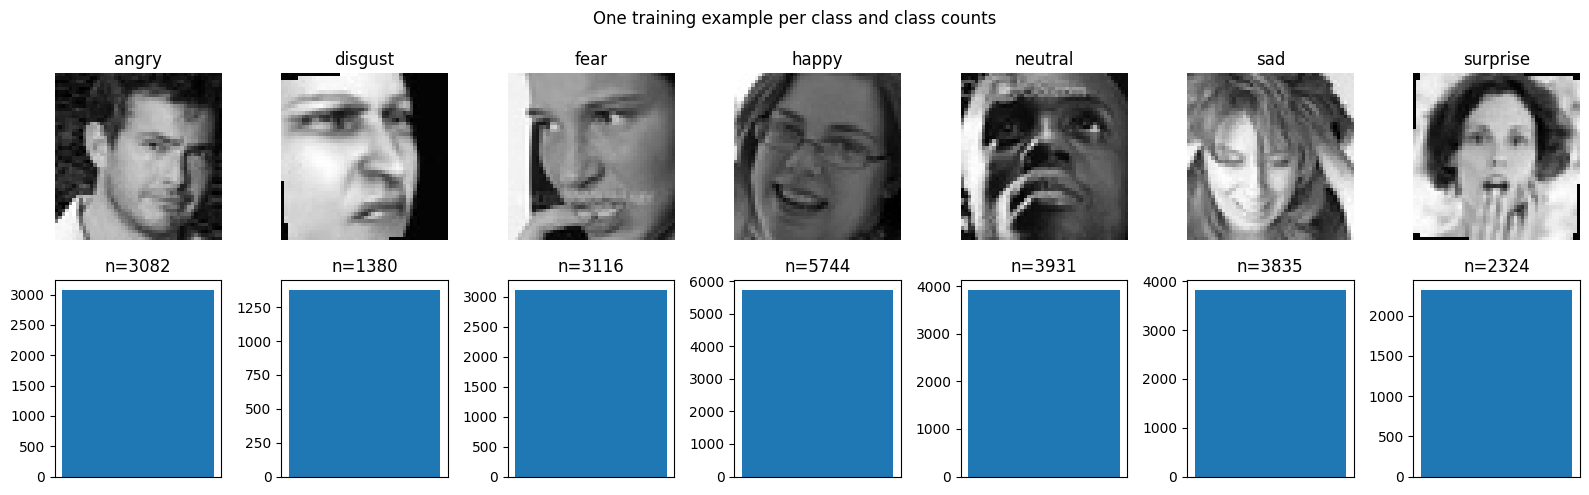

Check whether each image visually matches its folder label. If many labels are wrong, model architecture alone cannot fix the dataset.


In [4]:
fig, axes = plt.subplots(2, 7, figsize=(16, 5))
for class_idx, class_name in enumerate(CLASS_NAMES):
    rows = train_df[train_df['Label'] == class_idx]
    if rows.empty:
        axes[0, class_idx].set_title(f'{class_name} (none)')
        axes[0, class_idx].axis('off')
        axes[1, class_idx].axis('off')
        continue
    row = rows.iloc[0]
    with Image.open(row['Resolved_Path']) as im:
        axes[0, class_idx].imshow(im.convert('L'), cmap='gray')
    axes[0, class_idx].set_title(class_name)
    axes[0, class_idx].axis('off')
    axes[1, class_idx].bar(['Train'], [len(rows)])
    axes[1, class_idx].set_title(f'n={len(rows)}')
    axes[1, class_idx].set_xticks([])
plt.suptitle('One training example per class and class counts')
plt.tight_layout()
plt.show()

print('Check whether each image visually matches its folder label. If many labels are wrong, model architecture alone cannot fix the dataset.')


## 5. Preprocessing and augmentation

All images are converted to grayscale and resized to 48×48. Pixel normalization is consistently mapped from `[0, 1]` to `[-1, 1]` for both training and inference. Augmentation is deliberately mild: strong rotations/erasing can destroy expression cues.

In [5]:
from torchvision.transforms import RandomApply

train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=8,
        translate=(0.04, 0.04),
        scale=(0.95, 1.05),
        shear=2,
        interpolation=InterpolationMode.BILINEAR,
        fill=0,
    ),
    RandomApply([transforms.ColorJitter(brightness=0.12, contrast=0.15)], p=0.30),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
    transforms.RandomErasing(p=0.08, scale=(0.01, 0.025), ratio=(0.5, 2.0), value=0),
])

eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,)),
])

class FERManifestDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.paths = dataframe['Resolved_Path'].tolist()
        self.labels = dataframe['Label'].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        path = self.paths[index]
        label = self.labels[index]
        try:
            with Image.open(path) as image:
                image = image.convert('L')
            if self.transform:
                image = self.transform(image)
            return image, label
        except Exception as exc:
            raise RuntimeError(f'Could not read image: {path}') from exc

train_dataset = FERManifestDataset(train_df, train_transform)
val_dataset = FERManifestDataset(val_df, eval_transform)
test_dataset = FERManifestDataset(test_df, eval_transform)

BATCH_SIZE = 128
NUM_WORKERS = 0  # Windows/Jupyter safe
PIN_MEMORY = device.type == 'cuda'

# Mild inverse-square-root sampling reduces the dominance of frequent classes
# without aggressively oversampling the smallest classes.
train_counts = np.bincount(train_df['Label'].to_numpy(), minlength=7)
class_sampling_weights = 1.0 / np.sqrt(np.maximum(train_counts, 1))
sample_weights = class_sampling_weights[train_df['Label'].to_numpy()]
train_sampler = WeightedRandomSampler(
    weights=torch.as_tensor(sample_weights, dtype=torch.double),
    num_samples=len(sample_weights),
    replacement=True,
)

generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, generator=generator
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY
)

print('Train batches:', len(train_loader))
print('Validation batches:', len(val_loader))
print('Test batches:', len(test_loader))
print('Training class counts:', dict(zip(DISPLAY_NAMES, train_counts.tolist())))


Train batches: 183
Validation batches: 43
Test batches: 56
Training class counts: {'Angry': 3082, 'Disgust': 1380, 'Fear': 3116, 'Happy': 5744, 'Neutral': 3931, 'Sad': 3835, 'Surprise': 2324}


## 6. New architecture: SE-ResNet FER (from scratch)

**Design:** four residual stages with channel attention (Squeeze-and-Excitation). Residual paths help optimization; SE recalibrates feature channels; global average pooling avoids a large flatten layer. The model is initialized randomly and receives no pretrained or previous FER weights.

In [6]:
class SqueezeExcitation(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        scale = self.fc(self.pool(x))
        return x * scale


class SEResidualBlock(nn.Module):
    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1, dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3,
            stride=stride, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.act = nn.SiLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3,
            stride=1, padding=1, bias=False
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.se = SqueezeExcitation(out_channels, reduction=8)
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels),
            )
        else:
            self.shortcut = nn.Identity()

        # Zero-init the last BN in each residual branch to start near identity.
        nn.init.zeros_(self.bn2.weight)

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.act(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        out = self.drop(out)
        out = self.act(out + identity)
        return out


class FER_SEResNetScratch(nn.Module):
    """48x48 grayscale FER network trained from random initialization."""
    def __init__(self, num_classes=7):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True),
        )
        self.stage1 = nn.Sequential(
            SEResidualBlock(32, 32, stride=1, dropout=0.02),
            SEResidualBlock(32, 32, stride=1, dropout=0.02),
        )
        self.stage2 = nn.Sequential(
            SEResidualBlock(32, 64, stride=2, dropout=0.04),
            SEResidualBlock(64, 64, stride=1, dropout=0.04),
        )
        self.stage3 = nn.Sequential(
            SEResidualBlock(64, 128, stride=2, dropout=0.06),
            SEResidualBlock(128, 128, stride=1, dropout=0.06),
        )
        self.stage4 = nn.Sequential(
            SEResidualBlock(128, 192, stride=2, dropout=0.08),
            SEResidualBlock(192, 192, stride=1, dropout=0.08),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(192, 128),
            nn.LayerNorm(128),
            nn.SiLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(128, num_classes),
        )
        self._initialize_weights()

    def _initialize_weights(self):
        for module in self.modules():
            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, (nn.BatchNorm2d, nn.LayerNorm)):
                if module.weight is not None:
                    nn.init.ones_(module.weight)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.Linear):
                nn.init.kaiming_uniform_(module.weight, a=5**0.5)
                if module.bias is not None:
                    nn.init.zeros_(module.bias)
        # Keep residual branches initially close to identity after other init.
        for module in self.modules():
            if isinstance(module, SEResidualBlock):
                nn.init.zeros_(module.bn2.weight)

    def forward(self, x):
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)
        return self.head(x)


model = FER_SEResNetScratch(num_classes=len(CLASS_NAMES)).to(device)
num_parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f'\nTrainable parameters: {num_parameters:,}')

# Shape check before training
with torch.no_grad():
    dummy = torch.zeros(2, 1, IMG_SIZE, IMG_SIZE, device=device)
    dummy_logits = model(dummy)
print('Input shape:', tuple(dummy.shape))
print('Output shape:', tuple(dummy_logits.shape))
assert dummy_logits.shape == (2, 7)
print('Architecture shape check: PASSED')


FER_SEResNetScratch(
  (stem): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): SiLU(inplace=True)
  )
  (stage1): Sequential(
    (0): SEResidualBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (se): SqueezeExcitation(
        (pool): AdaptiveAvgPool2d(output_size=1)
        (fc): Sequential(
          (0): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
          (1): SiLU(inplace=True)
          (2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
          (3): Sigmoid()
   

## 7. Training setup

In [7]:
EPOCHS = 90
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 2e-4
EARLY_STOPPING_PATIENCE = 14
LABEL_SMOOTHING = 0.05
USE_AMP = device.type == 'cuda'
GRAD_CLIP_NORM = 1.0

BEST_CHECKPOINT_PATH = MODEL_DIR / 'FER_SEResNet_Scratch_Best.pth'
LAST_CHECKPOINT_PATH = MODEL_DIR / 'FER_SEResNet_Scratch_Last.pth'

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.5, patience=4, min_lr=1e-6
)
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

history = {
    'epoch': [], 'train_loss': [], 'train_accuracy': [],
    'val_loss': [], 'val_accuracy': [], 'val_macro_f1': [],
    'val_macro_recall': [], 'learning_rate': [],
    'val_pred_neutral_ratio': [],
}

best_val_macro_f1 = -1.0
best_val_accuracy = 0.0
best_epoch = 0
early_stop_counter = 0

print('Training starts from RANDOM INITIALIZATION.')
print('No previous checkpoint is loaded.')
print('Batch size:', BATCH_SIZE, '| Epoch limit:', EPOCHS, '| AMP:', USE_AMP)


Training starts from RANDOM INITIALIZATION.
No previous checkpoint is loaded.
Batch size: 128 | Epoch limit: 90 | AMP: True


## 8. Train and validate — select best epoch by Macro-F1

In [9]:
def run_validation(net, loader):
    net.eval()
    losses = []
    y_true, y_pred = [], []
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = net(images)
                loss = criterion(logits, labels)
            losses.append(loss.item() * labels.size(0))
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(logits.argmax(1).cpu().numpy().tolist())
    val_loss = float(sum(losses) / len(loader.dataset))
    val_acc = accuracy_score(y_true, y_pred)
    val_macro_f1 = f1_score(y_true, y_pred, labels=list(range(7)), average='macro', zero_division=0)
    _, macro_recall, _, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(7)), average='macro', zero_division=0
    )
    pred_counts = np.bincount(y_pred, minlength=7)
    return val_loss, val_acc, val_macro_f1, macro_recall, y_true, y_pred, pred_counts

start_time = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    train_true, train_pred = [], []

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * labels.size(0)
        train_true.extend(labels.detach().cpu().numpy().tolist())
        train_pred.extend(logits.detach().argmax(1).cpu().numpy().tolist())

    train_loss = running_loss / len(train_loader.dataset)
    train_acc = accuracy_score(train_true, train_pred)
    (val_loss, val_acc, val_f1, val_macro_recall,
     val_true, val_pred, val_pred_counts) = run_validation(model, val_loader)

    scheduler.step(val_f1)
    current_lr = optimizer.param_groups[0]['lr']
    neutral_ratio = val_pred_counts[CLASS_TO_IDX['neutral']] / max(1, len(val_pred))

    history['epoch'].append(epoch)
    history['train_loss'].append(train_loss)
    history['train_accuracy'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)
    history['val_macro_f1'].append(val_f1)
    history['val_macro_recall'].append(val_macro_recall)
    history['learning_rate'].append(current_lr)
    history['val_pred_neutral_ratio'].append(neutral_ratio)

    improved = val_f1 > best_val_macro_f1 + 1e-6
    if improved:
        best_val_macro_f1 = val_f1
        best_val_accuracy = val_acc
        best_epoch = epoch
        early_stop_counter = 0
        torch.save({
            'epoch': best_epoch,
            'architecture': 'FER_SEResNetScratch',
            'model_state_dict': {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
            'class_names': CLASS_NAMES,
            'img_size': IMG_SIZE,
            'normalization_mean': [0.5],
            'normalization_std': [0.5],
            'best_val_accuracy': best_val_accuracy,
            'best_val_macro_f1': best_val_macro_f1,
            'optimizer_state_dict': optimizer.state_dict(),
        }, BEST_CHECKPOINT_PATH)
        marker = '  [BEST CHECKPOINT SAVED]'
    else:
        early_stop_counter += 1
        marker = ''

    torch.save({
        'epoch': epoch,
        'architecture': 'FER_SEResNetScratch',
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
    }, LAST_CHECKPOINT_PATH)

    predicted_dist = ', '.join(
        f'{DISPLAY_NAMES[i]}:{val_pred_counts[i]}' for i in range(7)
    )
    print(
        f'Epoch {epoch:03d}/{EPOCHS} | '
        f'Train loss {train_loss:.4f} acc {train_acc:.4f} | '
        f'Val loss {val_loss:.4f} acc {val_acc:.4f} '
        f'Macro-F1 {val_f1:.4f} Macro-Recall {val_macro_recall:.4f} | '
        f'Neutral predictions {neutral_ratio:.1%} | LR {current_lr:.2e}'
        f'{marker}'
    )
    print('  Validation predicted-class counts:', predicted_dist)

    if early_stop_counter >= EARLY_STOPPING_PATIENCE:
        print(f'\nEarly stopping at epoch {epoch}; best epoch was {best_epoch}.')
        break

    if device.type == 'cuda' and epoch % 5 == 0:
        torch.cuda.empty_cache()

history_df = pd.DataFrame(history)
history_df.to_csv(RESULT_DIR / 'training_history.csv', index=False)
print('\nTraining completed in', round((time.time() - start_time) / 60, 1), 'minutes')
print('Best epoch:', best_epoch)
print('Best validation accuracy:', round(best_val_accuracy, 4))
print('Best validation Macro-F1:', round(best_val_macro_f1, 4))
print('Best checkpoint:', BEST_CHECKPOINT_PATH)
if best_epoch == 0:
    raise RuntimeError('No best checkpoint was saved. Check the training logs.')


Epoch 001/90 | Train loss 1.9256 acc 0.1899 | Val loss 1.8576 acc 0.2406 Macro-F1 0.1654 Macro-Recall 0.1885 | Neutral predictions 5.9% | LR 5.00e-04  [BEST CHECKPOINT SAVED]
  Validation predicted-class counts: Angry:122, Disgust:0, Fear:547, Happy:2665, Neutral:323, Sad:1202, Surprise:574
Epoch 002/90 | Train loss 1.8963 acc 0.2095 | Val loss 1.9081 acc 0.1920 Macro-F1 0.1378 Macro-Recall 0.1980 | Neutral predictions 0.2% | LR 5.00e-04
  Validation predicted-class counts: Angry:89, Disgust:0, Fear:1459, Happy:675, Neutral:12, Sad:1464, Surprise:1734
Epoch 003/90 | Train loss 1.8706 acc 0.2321 | Val loss 1.8072 acc 0.2638 Macro-F1 0.2127 Macro-Recall 0.2396 | Neutral predictions 1.7% | LR 5.00e-04  [BEST CHECKPOINT SAVED]
  Validation predicted-class counts: Angry:898, Disgust:51, Fear:323, Happy:2437, Neutral:95, Sad:632, Surprise:997
Epoch 004/90 | Train loss 1.8110 acc 0.2768 | Val loss 1.8282 acc 0.2811 Macro-F1 0.2240 Macro-Recall 0.2684 | Neutral predictions 2.1% | LR 5.00e-04  

## 9. Review training curves

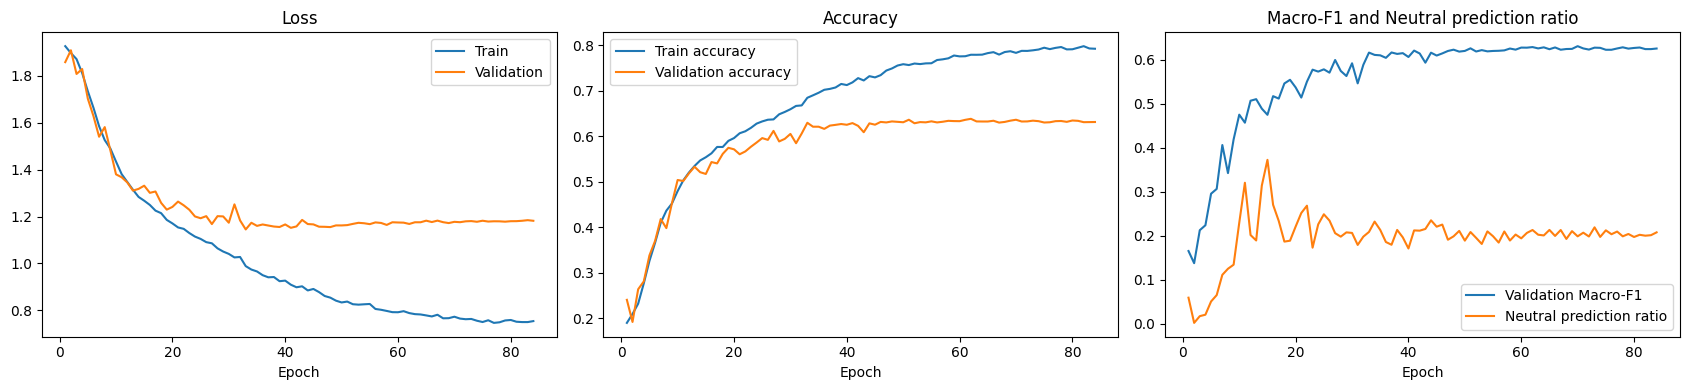

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(history_df['epoch'], history_df['train_loss'], label='Train')
axes[0].plot(history_df['epoch'], history_df['val_loss'], label='Validation')
axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history_df['epoch'], history_df['train_accuracy'], label='Train accuracy')
axes[1].plot(history_df['epoch'], history_df['val_accuracy'], label='Validation accuracy')
axes[1].set_title('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend()

axes[2].plot(history_df['epoch'], history_df['val_macro_f1'], label='Validation Macro-F1')
axes[2].plot(history_df['epoch'], history_df['val_pred_neutral_ratio'], label='Neutral prediction ratio')
axes[2].set_title('Macro-F1 and Neutral prediction ratio')
axes[2].set_xlabel('Epoch')
axes[2].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()


## 10. Final test evaluation (run once after training)

The test split is not used for gradient updates or checkpoint selection. It is evaluated only after the best validation checkpoint has been selected.

In [8]:
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location='cpu')
if checkpoint.get('architecture') != 'FER_SEResNetScratch':
    raise RuntimeError('Unexpected checkpoint architecture.')
model.load_state_dict(checkpoint['model_state_dict'], strict=True)
model = model.to(device)
model.eval()

all_test_labels, all_test_preds, all_test_probs = [], [], []
with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
        probs = torch.softmax(logits.float(), dim=1)
        preds = probs.argmax(1)
        all_test_labels.extend(labels.numpy().tolist())
        all_test_preds.extend(preds.cpu().numpy().tolist())
        all_test_probs.extend(probs.cpu().numpy().tolist())

all_test_labels = np.asarray(all_test_labels, dtype=np.int64)
all_test_preds = np.asarray(all_test_preds, dtype=np.int64)
all_test_probs = np.asarray(all_test_probs, dtype=np.float32)

test_accuracy = accuracy_score(all_test_labels, all_test_preds)
test_balanced_accuracy = balanced_accuracy_score(all_test_labels, all_test_preds)
test_precision, test_recall, test_f1, test_support = precision_recall_fscore_support(
    all_test_labels, all_test_preds, labels=list(range(7)), average=None, zero_division=0
)
test_macro_f1 = f1_score(all_test_labels, all_test_preds, labels=list(range(7)), average='macro', zero_division=0)
test_weighted_f1 = f1_score(all_test_labels, all_test_preds, labels=list(range(7)), average='weighted', zero_division=0)

summary = pd.DataFrame([{
    'Architecture': 'FER_SEResNetScratch',
    'Best_Epoch': int(checkpoint['epoch']),
    'Validation_Accuracy': float(checkpoint['best_val_accuracy']),
    'Validation_Macro_F1': float(checkpoint['best_val_macro_f1']),
    'Test_Accuracy': float(test_accuracy),
    'Test_Balanced_Accuracy': float(test_balanced_accuracy),
    'Test_Macro_Precision': float(np.mean(test_precision)),
    'Test_Macro_Recall': float(np.mean(test_recall)),
    'Test_Macro_F1': float(test_macro_f1),
    'Test_Weighted_F1': float(test_weighted_f1),
    'Test_Images': int(len(all_test_labels)),
    'Train_Images': int(len(train_dataset)),
    'Validation_Images': int(len(val_dataset)),
}])
display(summary.style.format({c: '{:.4f}' for c in summary.select_dtypes(include='number').columns if c not in ['Best_Epoch','Test_Images','Train_Images','Validation_Images']}))
summary.to_csv(RESULT_DIR / 'final_test_metrics.csv', index=False)

report = classification_report(
    all_test_labels, all_test_preds, labels=list(range(7)),
    target_names=DISPLAY_NAMES, output_dict=True, zero_division=0
)
report_df = pd.DataFrame(report).transpose()
display(report_df)
report_df.to_csv(RESULT_DIR / 'classification_report.csv')

cm = confusion_matrix(all_test_labels, all_test_preds, labels=list(range(7)))
cm_df = pd.DataFrame(cm, index=DISPLAY_NAMES, columns=DISPLAY_NAMES)
cm_df.to_csv(RESULT_DIR / 'confusion_matrix.csv')

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(7), DISPLAY_NAMES, rotation=45, ha='right')
ax.set_yticks(range(7), DISPLAY_NAMES)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Test Confusion Matrix — Scratch SE-ResNet')
for i in range(7):
    for j in range(7):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color='black', fontsize=9)
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'test_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

row_sums = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(7), DISPLAY_NAMES, rotation=45, ha='right')
ax.set_yticks(range(7), DISPLAY_NAMES)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Normalized Test Confusion Matrix')
for i in range(7):
    for j in range(7):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', color='black', fontsize=9)
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.savefig(FIGURE_DIR / 'test_confusion_matrix_normalized.png', dpi=180, bbox_inches='tight')
plt.show()

true_counts = np.bincount(all_test_labels, minlength=7)
pred_counts = np.bincount(all_test_preds, minlength=7)
pred_distribution = pd.DataFrame({
    'Emotion': DISPLAY_NAMES,
    'True_Count': true_counts,
    'Predicted_Count': pred_counts,
    'Predicted_Percentage': pred_counts / max(1, len(all_test_preds)) * 100,
    'Precision': test_precision,
    'Recall': test_recall,
    'F1': test_f1,
    'Support': test_support,
})
display(pred_distribution)
pred_distribution.to_csv(RESULT_DIR / 'prediction_distribution_and_class_metrics.csv', index=False)

neutral_idx = CLASS_TO_IDX['neutral']
neutral_prediction_ratio = pred_counts[neutral_idx] / max(1, len(all_test_preds))
majority_prediction_ratio = pred_counts.max() / max(1, len(all_test_preds))
print(f"\nNeutral predicted on {neutral_prediction_ratio:.1%} of test images.")
print(f"Largest single-class prediction share: {majority_prediction_ratio:.1%}.")
if majority_prediction_ratio > 0.50:
    print('WARNING: The model is still strongly concentrated on one predicted class; inspect confusion matrix, labels, and crop preprocessing before deployment.')
else:
    print('Prediction distribution check: no single class exceeds 50% of predictions.')

# Save per-image predictions and confidences.
row_paths = test_df['Resolved_Path'].tolist()
test_output = pd.DataFrame({
    'Image_Path': row_paths,
    'Actual_Label': [DISPLAY_NAMES[i] for i in all_test_labels],
    'Predicted_Label': [DISPLAY_NAMES[i] for i in all_test_preds],
    'Confidence': all_test_probs.max(axis=1),
})
test_output.to_csv(RESULT_DIR / 'test_image_predictions.csv', index=False)

print('\nAll test results saved under:', RESULT_DIR)
print('Best scratch checkpoint:', BEST_CHECKPOINT_PATH)


NameError: name 'BEST_CHECKPOINT_PATH' is not defined

## 11. Compare predictions on balanced sample examples

NameError: name 'all_test_preds' is not defined

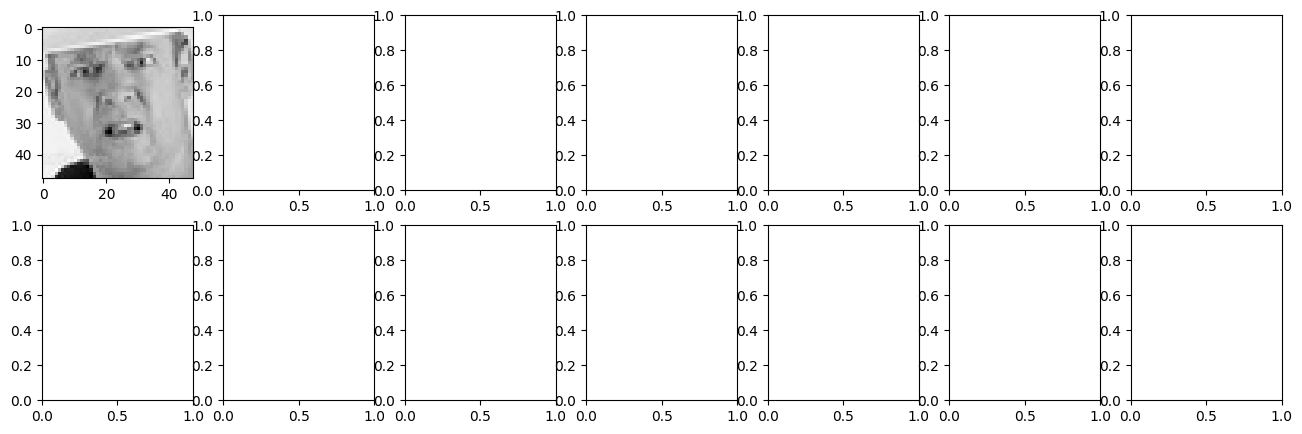

In [9]:
# Show one or two test examples per class with predicted label and confidence.
fig, axes = plt.subplots(2, 7, figsize=(16, 5))
for class_idx, class_name in enumerate(CLASS_NAMES):
    rows = test_df[test_df['Label'] == class_idx]
    for row_idx in range(2):
        ax = axes[row_idx, class_idx]
        if row_idx >= len(rows):
            ax.axis('off')
            continue
        row = rows.iloc[row_idx]
        path = row['Resolved_Path']
        test_position = test_df.index[test_df['Resolved_Path'] == path][0]
        with Image.open(path) as im:
            ax.imshow(im.convert('L'), cmap='gray')
        pred = DISPLAY_NAMES[int(all_test_preds[test_position])]
        conf = float(all_test_probs[test_position].max()) * 100
        ax.set_title(f'True: {class_name}\nPred: {pred} ({conf:.0f}%)', fontsize=8)
        ax.axis('off')
plt.suptitle('Held-out test examples (not training data)')
plt.tight_layout()
plt.show()


## 12. Final artifacts and next step

All artifacts are saved inside the new folder:

`E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\`

- `Models/FER_SEResNet_Scratch_Best.pth` — best checkpoint selected by validation Macro-F1
- `Models/FER_SEResNet_Scratch_Last.pth` — latest training checkpoint
- `Results/` — split counts, training history, final metrics, classification report, confusion matrix CSVs, prediction distribution, and per-image predictions
- `Figures/` — training curves and test confusion-matrix plots

The original dataset, leakage manifest, previous checkpoints, and old results remain untouched. Do not deploy automatically after training. First inspect the validation and test class-wise metrics, confusion matrix, and predicted-class distribution. Then align the webcam face-crop preprocessing with this model's training preprocessing.


In [14]:
from pathlib import Path
import shutil

PROJECT_ROOT = Path(r"E:\Deploy\Facial Expression Detection")

OUTPUT_DIR = PROJECT_ROOT / "FER_Scratch_Experiment"

BEST_MODEL = (
    OUTPUT_DIR / "Models" /
    "FER_SEResNet_Scratch_Best.pth"
)

BACKUP_DIR = OUTPUT_DIR / "Backup"
BACKUP_DIR.mkdir(parents=True, exist_ok=True)

BACKUP_MODEL = (
    BACKUP_DIR / "FER_SEResNet_Scratch_Best_Backup.pth"
)

if BEST_MODEL.exists():
    shutil.copy2(BEST_MODEL, BACKUP_MODEL)
    print("Backup successful!")
    print("Saved at:", BACKUP_MODEL)
else:
    print("ERROR: Best model not found!")

Backup successful!
Saved at: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Backup\FER_SEResNet_Scratch_Best_Backup.pth


In [15]:
RESULTS_DIR = OUTPUT_DIR / "Results"

for file in sorted(RESULTS_DIR.iterdir()):
    print(file.name)

classification_report.csv
confusion_matrix.csv
final_test_metrics.csv
prediction_distribution_and_class_metrics.csv
scratch_split_class_counts.csv
test_image_predictions.csv
training_history.csv


In [16]:
import pandas as pd
from pathlib import Path

RESULTS_DIR = Path(
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results"
)

pred_df = pd.read_csv(
    RESULTS_DIR / "test_image_predictions.csv"
)

print("Total test predictions:", len(pred_df))

print("\nColumn Names:")
print(pred_df.columns.tolist())

print("\nFirst 10 Predictions:")
display(pred_df.head(10))

print("\nData Information:")
pred_df.info()

Total test predictions: 7139

Column Names:
['Image_Path', 'Actual_Label', 'Predicted_Label', 'Confidence']

First 10 Predictions:


,Image_Path,Actual_Label,Predicted_Label,Confidence
0,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Disgust,0.528410
1,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Disgust,0.384544
2,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Neutral,0.670795
3,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Neutral,0.486961
4,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Angry,0.852577
5,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,0.845904
6,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Angry,0.944704
7,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Angry,0.854839
8,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Angry,0.641775
9,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,0.381178



Data Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7139 entries, 0 to 7138
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Image_Path       7139 non-null   object 
 1   Actual_Label     7139 non-null   object 
 2   Predicted_Label  7139 non-null   object 
 3   Confidence       7139 non-null   float64
dtypes: float64(1), object(3)
memory usage: 223.2+ KB


In [17]:
import pandas as pd

# Correct and incorrect predictions
pred_df["Correct"] = (
    pred_df["Actual_Label"] == pred_df["Predicted_Label"]
)

print("Correct Predictions:", pred_df["Correct"].sum())
print("Wrong Predictions:", (~pred_df["Correct"]).sum())

print("\nOverall Accuracy:")
print(round(pred_df["Correct"].mean() * 100, 2), "%")


# 1. Most common misclassifications
wrong_df = pred_df[~pred_df["Correct"]].copy()

wrong_pairs = (
    wrong_df.groupby(
        ["Actual_Label", "Predicted_Label"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nTop 15 Misclassification Pairs:")
display(wrong_pairs.head(15))


# 2. Class-wise correct and wrong predictions
class_analysis = (
    pred_df.groupby("Actual_Label")
    .agg(
        Total=("Correct", "count"),
        Correct=("Correct", "sum"),
        Accuracy=("Correct", "mean")
    )
)

class_analysis["Wrong"] = (
    class_analysis["Total"] - class_analysis["Correct"]
)

class_analysis["Accuracy"] *= 100

print("\nClass-wise Performance:")
display(class_analysis.round(2))


# 3. Confidence comparison
print("\nAverage Confidence:")
display(
    pred_df.groupby("Correct")["Confidence"]
    .agg(["mean", "median", "count"])
    .round(3)
)

Correct Predictions: 4527
Wrong Predictions: 2612

Overall Accuracy:
63.41 %

Top 15 Misclassification Pairs:


,Actual_Label,Predicted_Label,Count
33,Sad,Neutral,243
16,Fear,Sad,230
27,Neutral,Sad,169
4,Angry,Sad,145
12,Fear,Angry,143
31,Sad,Fear,140
29,Sad,Angry,129
3,Angry,Neutral,108
15,Fear,Neutral,106
21,Happy,Neutral,92



Class-wise Performance:


,Total,Correct,Accuracy,Wrong
Actual_Label,,,,
Angry,954,545,57.13,409
Disgust,367,226,61.58,141
Fear,979,369,37.69,610
Happy,1749,1485,84.91,264
Neutral,1204,819,68.02,385
Sad,1169,584,49.96,585
Surprise,717,499,69.60,218



Average Confidence:


,mean,median,count
Correct,,,
False,0.628,0.614,2612
True,0.802,0.874,4527


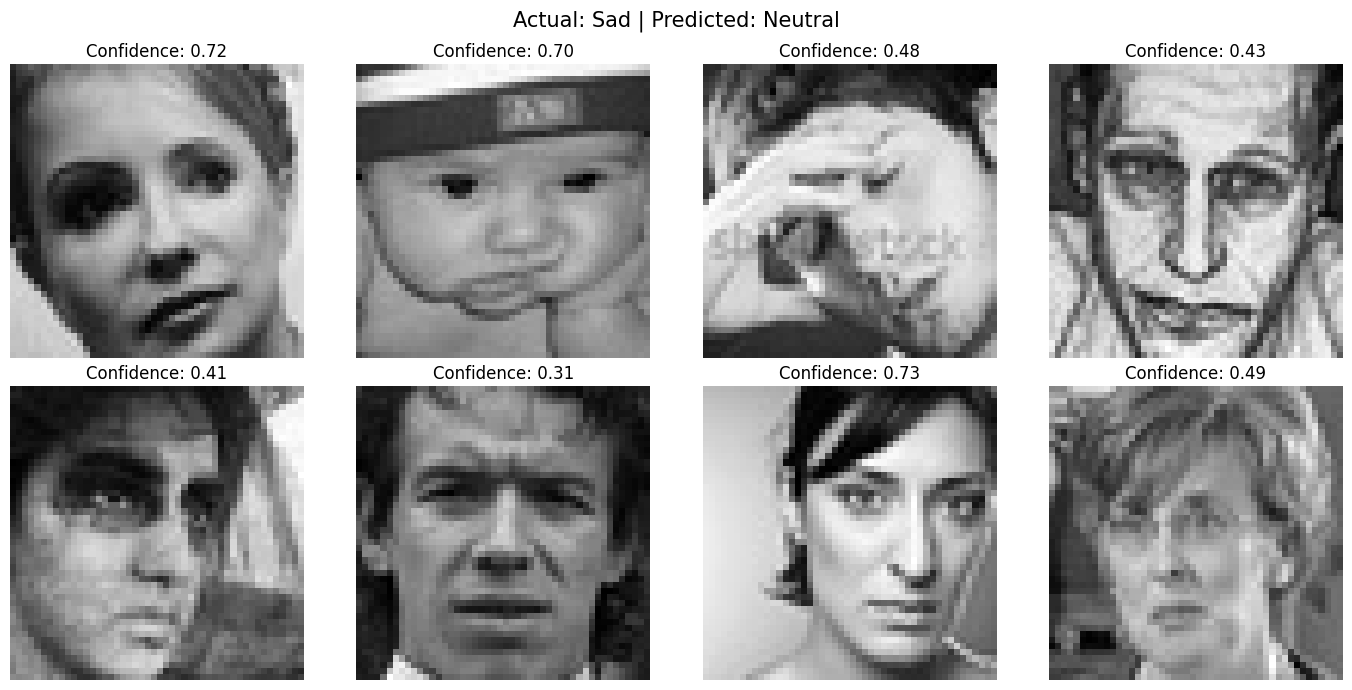

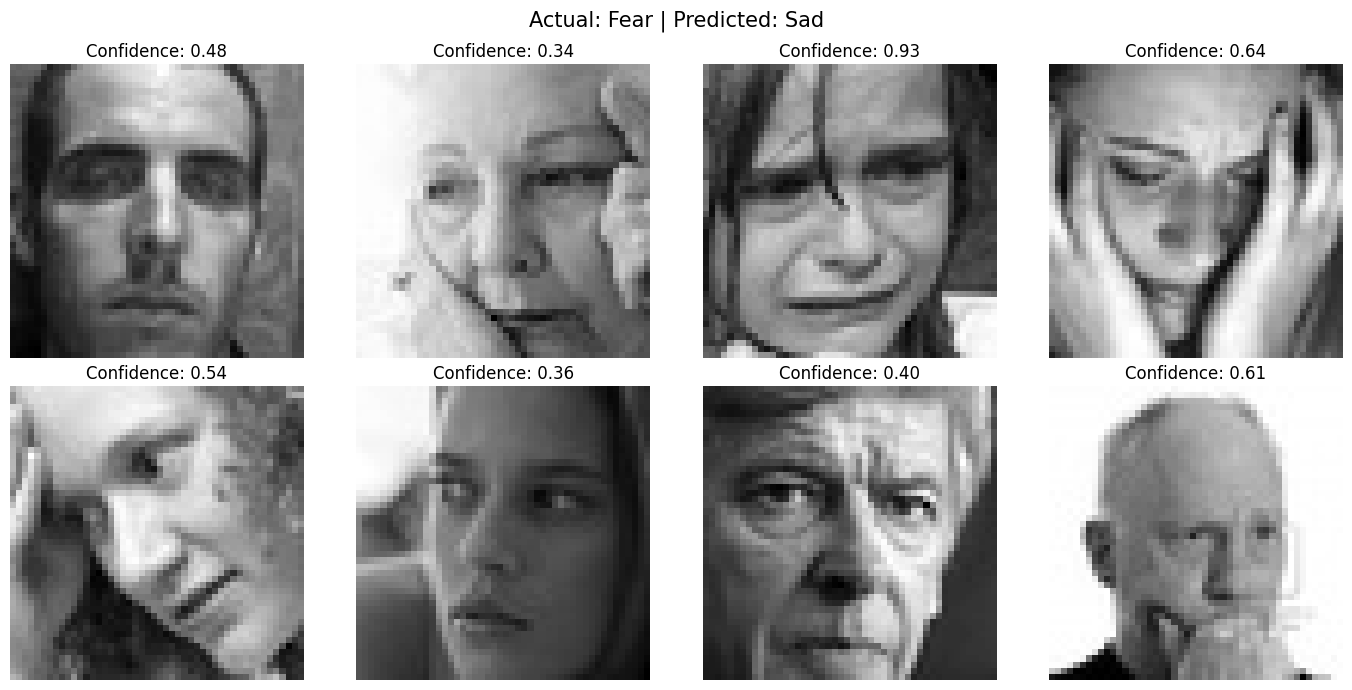

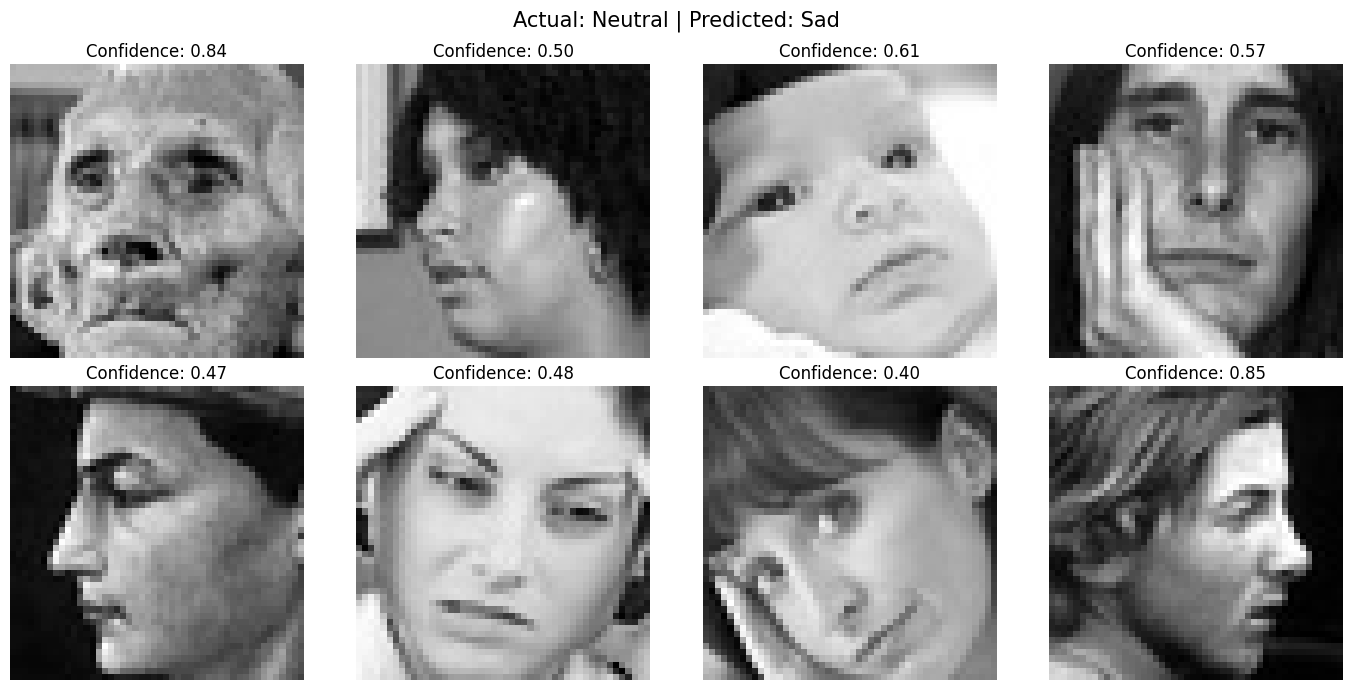

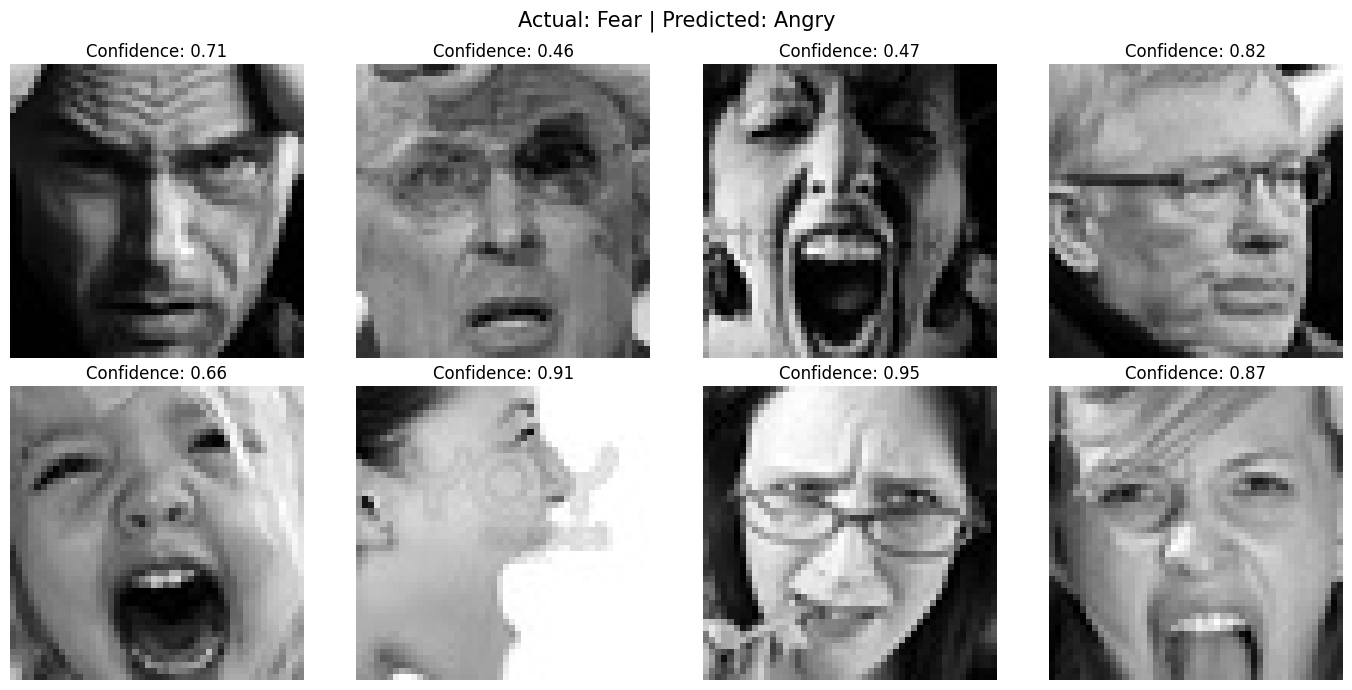

In [18]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Focus on the most confused emotion pairs
selected_pairs = [
    ("Sad", "Neutral"),
    ("Fear", "Sad"),
    ("Neutral", "Sad"),
    ("Fear", "Angry"),
]

for actual, predicted in selected_pairs:

    subset = wrong_df[
        (wrong_df["Actual_Label"] == actual) &
        (wrong_df["Predicted_Label"] == predicted)
    ]

    sample = subset.sample(
        n=min(8, len(subset)),
        random_state=42
    )

    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    fig.suptitle(
        f"Actual: {actual} | Predicted: {predicted}",
        fontsize=15
    )

    for ax, (_, row) in zip(axes.flat, sample.iterrows()):

        try:
            img = Image.open(row["Image_Path"]).convert("L")
            ax.imshow(img, cmap="gray")
            ax.set_title(
                f"Confidence: {row['Confidence']:.2f}"
            )
        except Exception as e:
            ax.set_title("Image loading error")

        ax.axis("off")

    for ax in axes.flat[len(sample):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

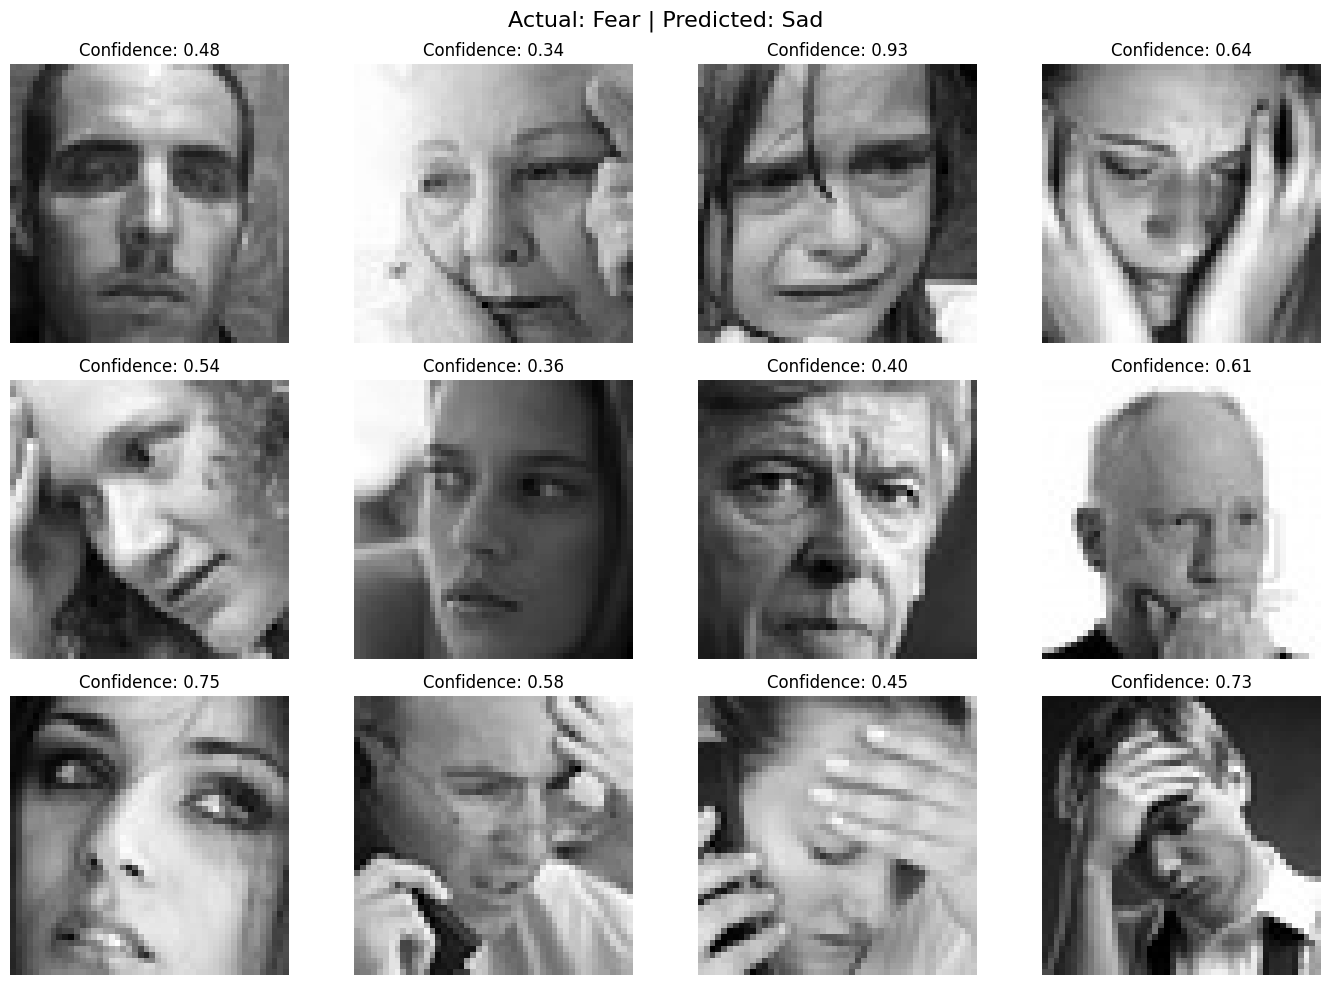

In [19]:
import matplotlib.pyplot as plt
from PIL import Image

actual = "Fear"
predicted = "Sad"

subset = wrong_df[
    (wrong_df["Actual_Label"] == actual) &
    (wrong_df["Predicted_Label"] == predicted)
]

sample = subset.sample(
    n=min(12, len(subset)),
    random_state=42
)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

fig.suptitle(
    "Actual: Fear | Predicted: Sad",
    fontsize=16
)

for ax, (_, row) in zip(axes.flat, sample.iterrows()):

    try:
        img = Image.open(row["Image_Path"]).convert("L")
        ax.imshow(img, cmap="gray")

        ax.set_title(
            f"Confidence: {row['Confidence']:.2f}"
        )

    except Exception as e:
        ax.set_title("Image loading error")

    ax.axis("off")

for ax in axes.flat[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

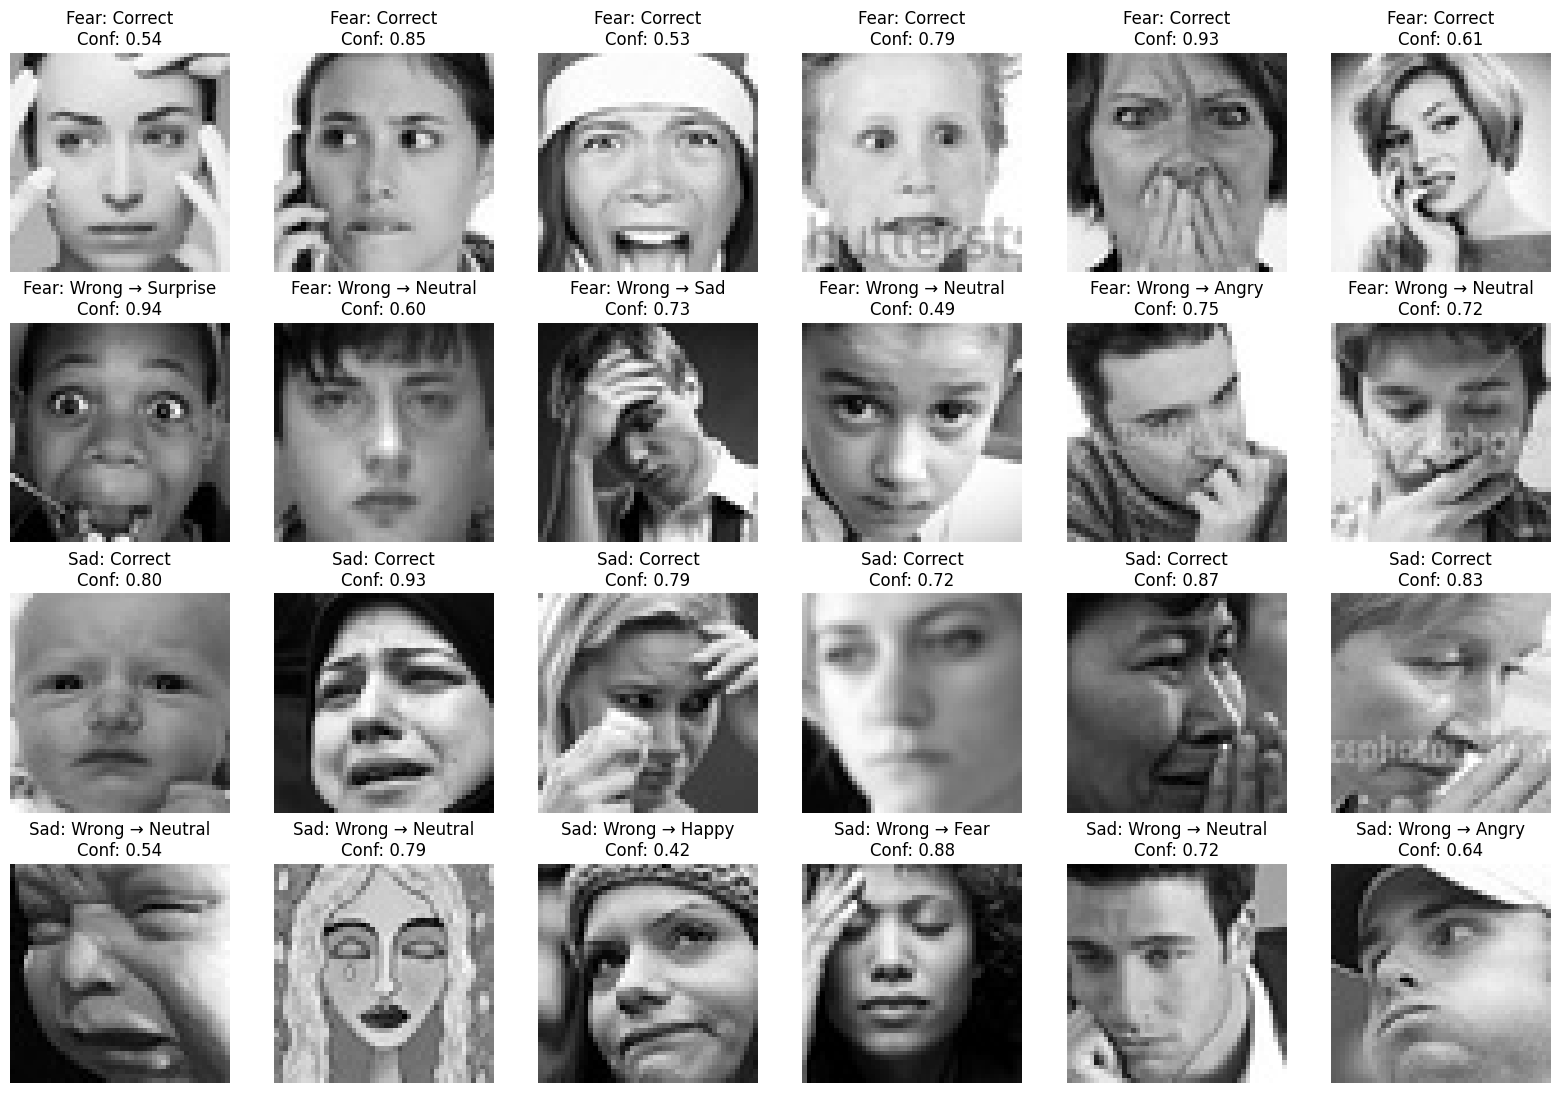

In [20]:
import matplotlib.pyplot as plt
from PIL import Image

emotions = ["Fear", "Sad"]

fig, axes = plt.subplots(4, 6, figsize=(16, 11))

for col, emotion in enumerate(emotions):

    # Correct predictions
    correct_samples = pred_df[
        (pred_df["Actual_Label"] == emotion) &
        (pred_df["Predicted_Label"] == emotion)
    ].sample(n=6, random_state=42)

    # Incorrect predictions
    wrong_samples = wrong_df[
        (wrong_df["Actual_Label"] == emotion)
    ].sample(n=6, random_state=42)

    for i, (_, row) in enumerate(correct_samples.iterrows()):
        img = Image.open(row["Image_Path"]).convert("L")
        axes[col * 2, i].imshow(img, cmap="gray")
        axes[col * 2, i].set_title(
            f"{emotion}: Correct\nConf: {row['Confidence']:.2f}"
        )
        axes[col * 2, i].axis("off")

    for i, (_, row) in enumerate(wrong_samples.iterrows()):
        img = Image.open(row["Image_Path"]).convert("L")
        axes[col * 2 + 1, i].imshow(img, cmap="gray")
        axes[col * 2 + 1, i].set_title(
            f"{emotion}: Wrong → {row['Predicted_Label']}\n"
            f"Conf: {row['Confidence']:.2f}"
        )
        axes[col * 2 + 1, i].axis("off")

axes[0, 0].set_ylabel("Fear Correct", fontsize=12)
axes[1, 0].set_ylabel("Fear Wrong", fontsize=12)
axes[2, 0].set_ylabel("Sad Correct", fontsize=12)
axes[3, 0].set_ylabel("Sad Wrong", fontsize=12)

plt.tight_layout()
plt.show()

In [21]:
# High confidence wrong predictions
high_conf_wrong = wrong_df[
    wrong_df["Confidence"] >= 0.80
].sort_values(
    "Confidence",
    ascending=False
)

print("Total high-confidence wrong predictions:",
      len(high_conf_wrong))

print("\nTop 20 high-confidence mistakes:")

display(
    high_conf_wrong[
        [
            "Image_Path",
            "Actual_Label",
            "Predicted_Label",
            "Confidence"
        ]
    ].head(20)
)

Total high-confidence wrong predictions: 565

Top 20 high-confidence mistakes:


,Image_Path,Actual_Label,Predicted_Label,Confidence
763,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Disgust,0.973952
1924,E:\Deploy\Facial Expression Detection\Data Set...,Fear,Surprise,0.968991
5481,E:\Deploy\Facial Expression Detection\Data Set...,Surprise,Happy,0.968829
1557,E:\Deploy\Facial Expression Detection\Data Set...,Fear,Surprise,0.967831
4049,E:\Deploy\Facial Expression Detection\Data Set...,Neutral,Happy,0.966832
3369,E:\Deploy\Facial Expression Detection\Data Set...,Neutral,Happy,0.966575
4485,E:\Deploy\Facial Expression Detection\Data Set...,Sad,Happy,0.966088
7085,E:\Deploy\Facial Expression Detection\Data Set...,Surprise,Happy,0.966081
3222,E:\Deploy\Facial Expression Detection\Data Set...,Happy,Angry,0.965420
5396,E:\Deploy\Facial Expression Detection\Data Set...,Surprise,Angry,0.965370


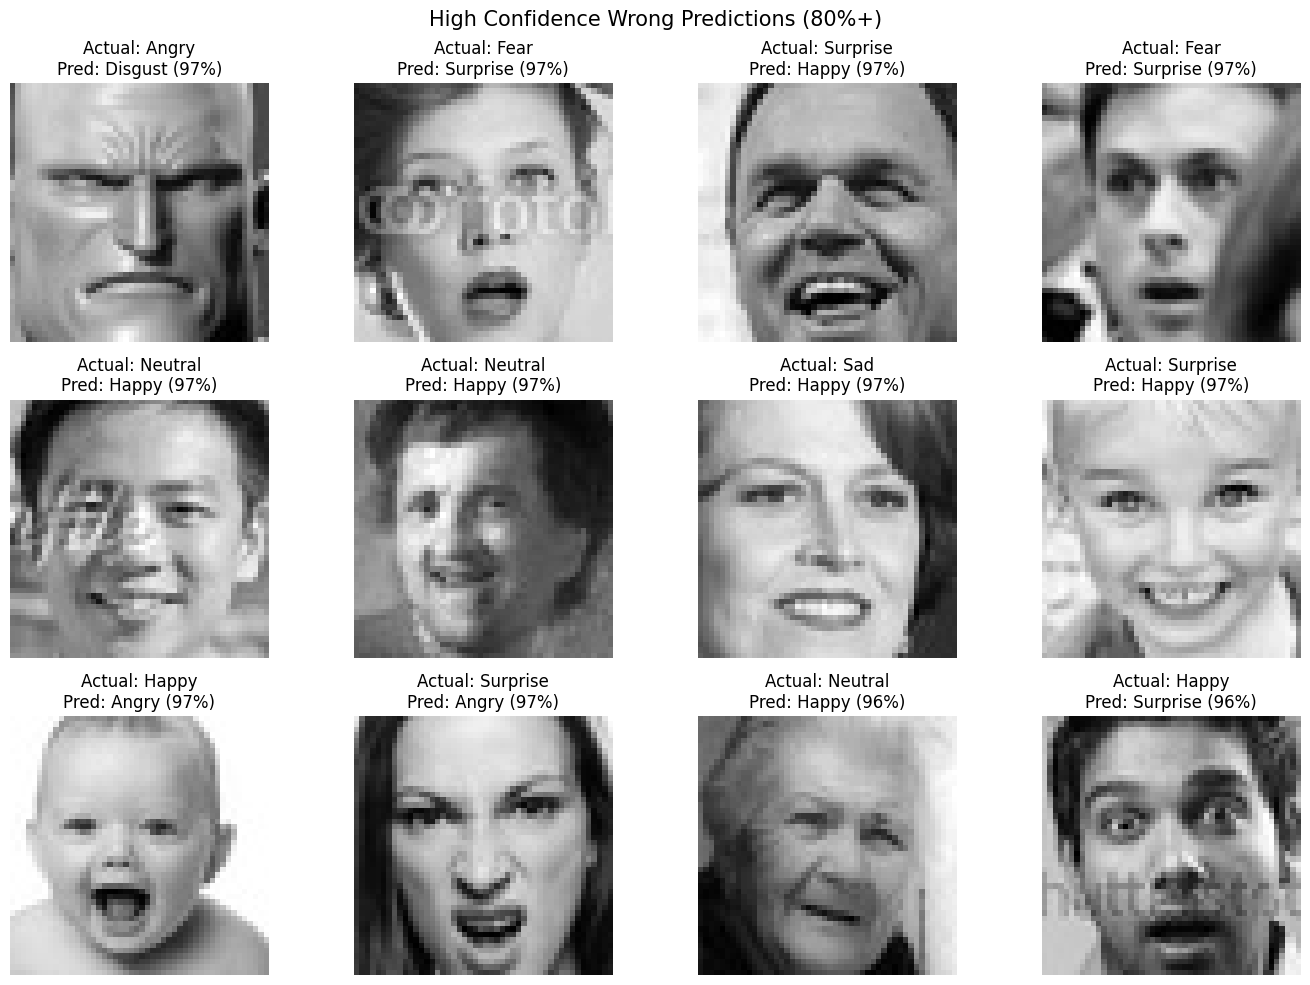

In [22]:
import matplotlib.pyplot as plt
from PIL import Image

sample = high_conf_wrong.head(12)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))

fig.suptitle(
    "High Confidence Wrong Predictions (80%+)",
    fontsize=15
)

for ax, (_, row) in zip(axes.flat, sample.iterrows()):

    img = Image.open(row["Image_Path"]).convert("L")

    ax.imshow(img, cmap="gray")

    ax.set_title(
        f"Actual: {row['Actual_Label']}\n"
        f"Pred: {row['Predicted_Label']} "
        f"({row['Confidence']:.0%})"
    )

    ax.axis("off")

for ax in axes.flat[len(sample):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# High confidence errors grouped by emotion pairs

high_conf_summary = (
    high_conf_wrong
    .groupby(["Actual_Label", "Predicted_Label"])
    .agg(
        Count=("Confidence", "size"),
        Avg_Confidence=("Confidence", "mean"),
        Max_Confidence=("Confidence", "max")
    )
    .reset_index()
    .sort_values("Count", ascending=False)
)

print("High-confidence error pairs:")
display(high_conf_summary.head(20).round(3))

print("\nHigh-confidence error statistics:")

print("Total wrong predictions:", len(wrong_df))
print("High-confidence wrong:", len(high_conf_wrong))

print(
    "Percentage of wrong predictions:",
    round(len(high_conf_wrong) / len(wrong_df) * 100, 2),
    "%"
)

print(
    "Percentage of all test images:",
    round(len(high_conf_wrong) / len(pred_df) * 100, 2),
    "%"
)

High-confidence error pairs:


,Actual_Label,Predicted_Label,Count,Avg_Confidence,Max_Confidence
11,Fear,Angry,57,0.885,0.949
23,Neutral,Happy,42,0.903,0.967
26,Sad,Angry,33,0.882,0.955
15,Fear,Surprise,33,0.900,0.969
29,Sad,Neutral,32,0.860,0.947
14,Fear,Sad,29,0.851,0.926
32,Surprise,Fear,28,0.877,0.940
27,Sad,Fear,26,0.878,0.933
6,Disgust,Angry,24,0.878,0.959
33,Surprise,Happy,24,0.894,0.969



High-confidence error statistics:
Total wrong predictions: 2612
High-confidence wrong: 565
Percentage of wrong predictions: 21.63 %
Percentage of all test images: 7.91 %


In [24]:
audit_path = RESULTS_DIR / "high_confidence_error_audit.csv"

high_conf_wrong.to_csv(audit_path, index=False)

print("Audit CSV saved successfully!")
print(audit_path)

Audit CSV saved successfully!
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results\high_confidence_error_audit.csv


In [25]:
import cv2
import numpy as np
import pandas as pd

def calculate_image_quality(image_path):

    img = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

    if img is None:
        return pd.Series([np.nan, np.nan, np.nan])

    blur_score = cv2.Laplacian(
        img, cv2.CV_64F
    ).var()

    contrast_score = img.std()

    brightness = img.mean()

    return pd.Series([
        blur_score,
        contrast_score,
        brightness
    ])


quality_df = pred_df.copy()

quality_df[
    ["Blur_Score", "Contrast", "Brightness"]
] = quality_df["Image_Path"].apply(
    calculate_image_quality
)

print("Image Quality Summary:")
display(
    quality_df[
        ["Blur_Score", "Contrast", "Brightness"]
    ].describe().round(2)
)

Image Quality Summary:


,Blur_Score,Contrast,Brightness
count,7139.00,7139.00,7139.00
mean,2460.95,54.11,129.06
std,1609.44,13.49,33.15
min,71.59,11.68,5.35
25%,1484.09,44.88,106.76
50%,2170.48,53.65,129.12
75%,3055.05,62.97,151.82
max,29270.47,106.93,244.79


In [26]:
quality_df["Correct"] = (
    quality_df["Actual_Label"] ==
    quality_df["Predicted_Label"]
)

print("Correct vs Wrong Image Quality:")

display(
    quality_df.groupby("Correct")[
        ["Blur_Score", "Contrast", "Brightness"]
    ].mean().round(2)
)

Correct vs Wrong Image Quality:


,Blur_Score,Contrast,Brightness
Correct,,,
False,2463.66,54.60,128.21
True,2459.39,53.83,129.54


In [27]:
class_quality = (
    quality_df.groupby("Actual_Label")
    .agg(
        Image_Count=("Image_Path", "count"),
        Avg_Blur=("Blur_Score", "mean"),
        Avg_Contrast=("Contrast", "mean"),
        Avg_Brightness=("Brightness", "mean"),
        Accuracy=("Correct", "mean")
    )
)

class_quality["Accuracy"] *= 100

display(class_quality.round(2))

,Image_Count,Avg_Blur,Avg_Contrast,Avg_Brightness,Accuracy
Actual_Label,,,,,
Angry,954,2566.74,54.72,127.07,57.13
Disgust,367,3053.98,52.86,124.94,61.58
Fear,979,2590.20,54.53,135.44,37.69
Happy,1749,2349.31,53.33,128.93,84.91
Neutral,1204,2228.68,54.39,123.32,68.02
Sad,1169,2262.11,54.04,122.87,49.96
Surprise,717,2826.74,54.92,145.12,69.60


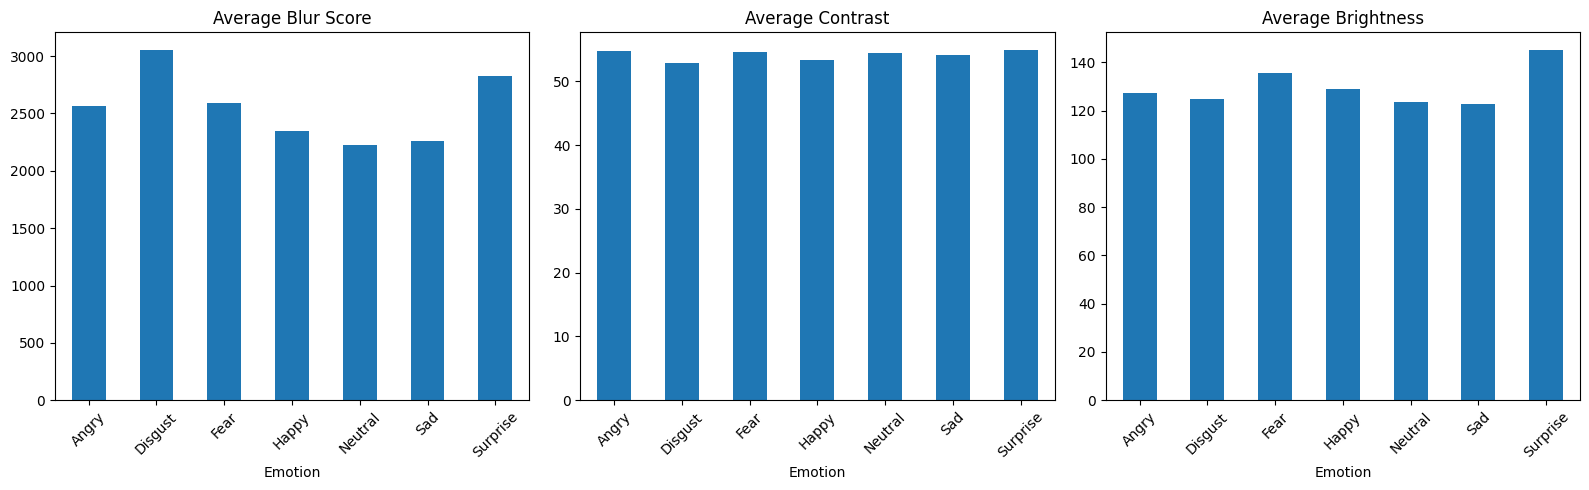

In [28]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = [
    ("Avg_Blur", "Average Blur Score"),
    ("Avg_Contrast", "Average Contrast"),
    ("Avg_Brightness", "Average Brightness")
]

for ax, (column, title) in zip(axes, metrics):

    class_quality[column].plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Emotion")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

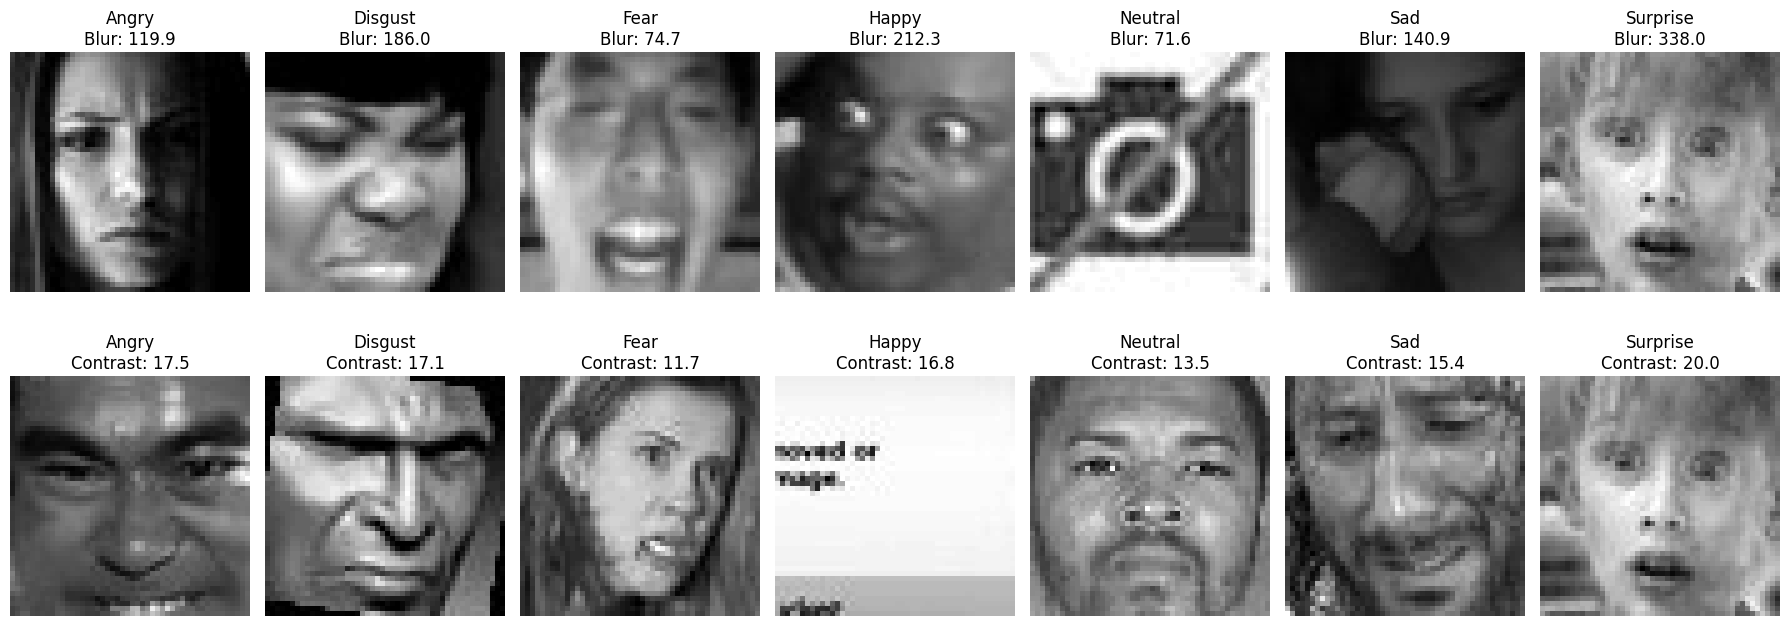

In [29]:
import matplotlib.pyplot as plt
from PIL import Image

emotions = sorted(quality_df["Actual_Label"].unique())

fig, axes = plt.subplots(2, 7, figsize=(18, 7))

for col, emotion in enumerate(emotions):

    subset = quality_df[
        quality_df["Actual_Label"] == emotion
    ]

    # Lowest Blur Score = potentially blurrier
    blurry = subset.nsmallest(1, "Blur_Score").iloc[0]

    # Lowest Contrast
    low_contrast = subset.nsmallest(1, "Contrast").iloc[0]

    for row_idx, sample in enumerate([blurry, low_contrast]):

        img = Image.open(
            sample["Image_Path"]
        ).convert("L")

        axes[row_idx, col].imshow(img, cmap="gray")

        if row_idx == 0:
            axes[row_idx, col].set_title(
                f"{emotion}\nBlur: {sample['Blur_Score']:.1f}"
            )
        else:
            axes[row_idx, col].set_title(
                f"{emotion}\nContrast: {sample['Contrast']:.1f}"
            )

        axes[row_idx, col].axis("off")

axes[0, 0].set_ylabel("Lowest Blur")
axes[1, 0].set_ylabel("Lowest Contrast")

plt.tight_layout()
plt.show()

In [30]:
# Identify suspicious images for manual inspection

suspicious_df = quality_df[
    (quality_df["Blur_Score"] < 200) |
    (quality_df["Contrast"] < 20)
].copy()

suspicious_df = suspicious_df.sort_values(
    ["Blur_Score", "Contrast"]
)

print("Total suspicious images:", len(suspicious_df))

display(
    suspicious_df[
        [
            "Image_Path",
            "Actual_Label",
            "Predicted_Label",
            "Blur_Score",
            "Contrast",
            "Brightness",
            "Correct"
        ]
    ].head(30)
)

Total suspicious images: 20


,Image_Path,Actual_Label,Predicted_Label,Blur_Score,Contrast,Brightness,Correct
4070,E:\Deploy\Facial Expression Detection\Data Set...,Neutral,Sad,71.589301,16.268987,232.929688,False
1643,E:\Deploy\Facial Expression Detection\Data Set...,Fear,Angry,74.696990,19.333329,48.560330,False
1366,E:\Deploy\Facial Expression Detection\Data Set...,Fear,Angry,97.991053,11.681626,35.190104,False
351,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,119.913176,20.522669,19.443142,False
6974,E:\Deploy\Facial Expression Detection\Data Set...,Sad,Sad,140.877283,23.585569,42.224392,True
5006,E:\Deploy\Facial Expression Detection\Data Set...,Sad,Angry,147.466421,16.378692,43.836806,False
1045,E:\Deploy\Facial Expression Detection\Data Set...,Disgust,Disgust,186.021966,34.113722,45.233941,True
1074,E:\Deploy\Facial Expression Detection\Data Set...,Disgust,Disgust,197.802407,30.652705,42.724826,True
6647,E:\Deploy\Facial Expression Detection\Data Set...,Neutral,Neutral,236.855136,18.068095,119.759549,True
1070,E:\Deploy\Facial Expression Detection\Data Set...,Disgust,Disgust,258.338228,17.075892,29.460069,True


In [31]:
# Save suspicious images for manual review

audit_file = RESULTS_DIR / "suspicious_image_quality_audit.csv"

suspicious_df.to_csv(audit_file, index=False)

print("Saved:", audit_file)

Saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results\suspicious_image_quality_audit.csv


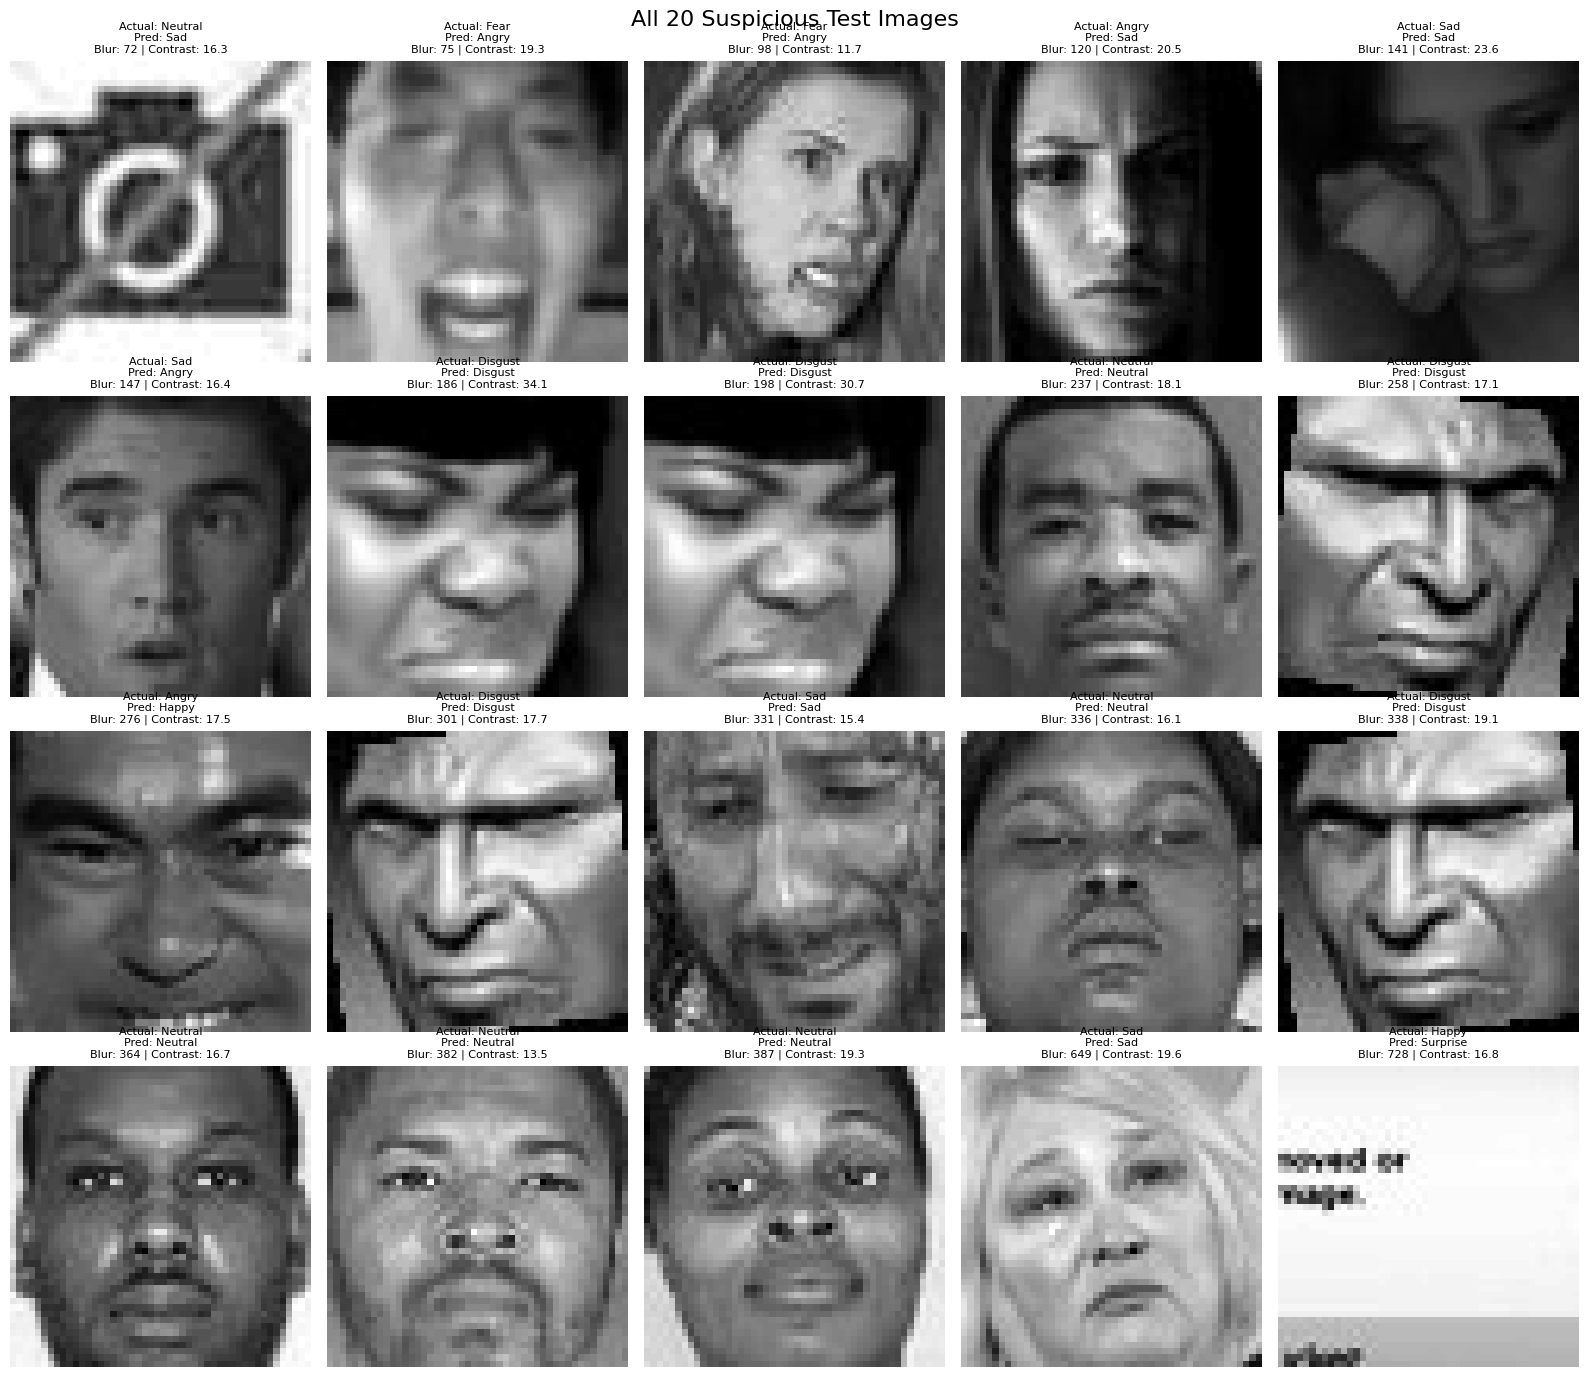

In [32]:
import matplotlib.pyplot as plt
from PIL import Image
import math

samples = suspicious_df.reset_index(drop=True)

n = len(samples)
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(
    rows, cols,
    figsize=(16, rows * 3.5)
)

axes = axes.flatten()

for i, row in samples.iterrows():

    img = Image.open(row["Image_Path"]).convert("L")

    axes[i].imshow(img, cmap="gray")

    axes[i].set_title(
        f"Actual: {row['Actual_Label']}\n"
        f"Pred: {row['Predicted_Label']}\n"
        f"Blur: {row['Blur_Score']:.0f} | "
        f"Contrast: {row['Contrast']:.1f}",
        fontsize=8
    )

    axes[i].axis("off")

for ax in axes[n:]:
    ax.axis("off")

plt.suptitle("All 20 Suspicious Test Images", fontsize=16)
plt.tight_layout()
plt.show()

In [33]:
import hashlib
from PIL import Image
from collections import defaultdict

image_hashes = defaultdict(list)

for _, row in suspicious_df.iterrows():

    try:
        img = Image.open(row["Image_Path"]).convert("L")

        # Exact pixel-based hash
        pixel_bytes = img.tobytes()
        image_hash = hashlib.sha256(pixel_bytes).hexdigest()

        image_hashes[image_hash].append({
            "path": row["Image_Path"],
            "label": row["Actual_Label"]
        })

    except Exception as e:
        print("Error:", row["Image_Path"], e)

duplicates = {
    h: items
    for h, items in image_hashes.items()
    if len(items) > 1
}

print("Exact duplicate groups:", len(duplicates))

for group_no, items in enumerate(duplicates.values(), 1):

    print(f"\nDuplicate Group {group_no}")

    for item in items:
        print("Label:", item["label"])
        print("Path:", item["path"])

Exact duplicate groups: 0


In [34]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"E:\Deploy\Facial Expression Detection")

TRAIN_DIR = PROJECT_ROOT / "Data Sets" / "train"
VAL_DIR = PROJECT_ROOT / "Data Sets" / "validation"

classes = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

for split_name, split_dir in [
    ("TRAIN", TRAIN_DIR),
    ("VALIDATION", VAL_DIR)
]:
    print(f"\n{split_name} DATASET")

    for emotion in classes:
        folder = split_dir / emotion

        if folder.exists():
            count = len([
                f for f in folder.iterdir()
                if f.is_file()
            ])
            print(f"{emotion}: {count}")
        else:
            print(f"Missing folder: {folder}")


TRAIN DATASET
angry: 3849
disgust: 2000
fear: 3904
happy: 7086
neutral: 4868
sad: 4716
surprise: 3000

VALIDATION DATASET
angry: 888
disgust: 79
fear: 922
happy: 1711
neutral: 1182
sad: 1198
surprise: 581


In [35]:
import pandas as pd
from pathlib import Path

counts_file = (
    Path(r"E:\Deploy\Facial Expression Detection")
    / "FER_Scratch_Experiment"
    / "Results"
    / "scratch_split_class_counts.csv"
)

split_counts = pd.read_csv(counts_file)

print("Actual Group-aware Split Class Counts:")
display(split_counts)

print("\nCSV Columns:")
print(split_counts.columns.tolist())

Actual Group-aware Split Class Counts:


,Emotion,Train,Validation,Test,Total
0,Angry,3082,701,954,4737
1,Disgust,1380,332,367,2079
2,Fear,3116,731,979,4826
3,Happy,5744,1304,1749,8797
4,Neutral,3931,915,1204,6050
5,Sad,3835,910,1169,5914
6,Surprise,2324,540,717,3581



CSV Columns:
['Emotion', 'Train', 'Validation', 'Test', 'Total']


In [36]:
split_pct = split_counts.copy()

for col in ["Train", "Validation", "Test"]:
    split_pct[col + "_Pct"] = (
        split_pct[col] / split_pct["Total"] * 100
    )

display(
    split_pct[
        [
            "Emotion",
            "Train_Pct",
            "Validation_Pct",
            "Test_Pct"
        ]
    ].round(2)
)

,Emotion,Train_Pct,Validation_Pct,Test_Pct
0,Angry,65.06,14.80,20.14
1,Disgust,66.38,15.97,17.65
2,Fear,64.57,15.15,20.29
3,Happy,65.29,14.82,19.88
4,Neutral,64.98,15.12,19.90
5,Sad,64.85,15.39,19.77
6,Surprise,64.90,15.08,20.02


In [37]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(r"E:\Deploy\Facial Expression Detection")

manifest_candidates = [
    PROJECT_ROOT / "FER_Final_Project" / "Audit" /
    "FER_Leakage_Audit_Group_Manifest.csv",

    PROJECT_ROOT / "FER_Final_Project" /
    "FER_Leakage_Audit_Group_Manifest.csv",

    PROJECT_ROOT / "FER_Leakage_Audit_Group_Manifest.csv"
]

manifest_path = next(
    (p for p in manifest_candidates if p.exists()),
    None
)

if manifest_path is None:
    print("Manifest file not found!")
else:
    manifest_df = pd.read_csv(manifest_path)

    print("Manifest found:", manifest_path)
    print("\nShape:", manifest_df.shape)
    print("\nColumns:")
    print(manifest_df.columns.tolist())

    print("\nFirst 10 rows:")
    display(manifest_df.head(10))

Manifest found: E:\Deploy\Facial Expression Detection\FER_Final_Project\Audit\FER_Leakage_Audit_Group_Manifest.csv

Shape: (35984, 7)

Columns:
['Image_Path', 'Class', 'SHA256', 'pHash', 'Group_ID', 'Old_Partitions', 'New_Split']

First 10 rows:


,Image_Path,Class,SHA256,pHash,Group_ID,Old_Partitions,New_Split
0,Data Sets/train\angry\Training_10118481.jpg,angry,4ec693354fd56ad79d5adad5ecdc3e9f092c252b9e2dd9...,0x822a3d7ebc9fc221,0,Previous_Train,Validation
1,Data Sets/train\angry\Training_10120469.jpg,angry,8f2c8999709f126102f5387565fcadd8e6fa8cbf755419...,0xd1187a0b6f60adb3,1,Previous_Test,Train
2,Data Sets/train\angry\Training_10131352.jpg,angry,7d95ea9b5675227952eaca2898cd12019f224ca9af14d7...,0x0,2,Previous_Train,Train
3,Data Sets/train\angry\Training_10161559.jpg,angry,0b30756121a6bacf2fb78c58e210f8cea05d8a9c4754a9...,0x84cc76ef8c24927b,3,Previous_Train,Train
4,Data Sets/train\angry\Training_1021836.jpg,angry,0cc5ccadd7dd046e751c1c3f7c333fd82cd8bc0cdcdb47...,0xbc80dee38fc03e91,4,Previous_Test,Test
5,Data Sets/train\angry\Training_10269675.jpg,angry,b7ef8a50e09f5b7baeead4b6aa2b38bb5185e23e539e48...,0x87f05ec3b82e0c6b,5,Previous_Train,Train
6,Data Sets/train\angry\Training_10278738.jpg,angry,25e99c61384520b9a36dedc4d3ba6d2ac035fc40466cd7...,0x84c057c33a274fd7,6,Previous_Train,Train
7,Data Sets/train\angry\Training_10290703.jpg,angry,ef5a261c9b568e07e68cb56b9ddc2dd3962e9f4b5b3118...,0xda0e45398e9b335c,7,Previous_Train,Train
8,Data Sets/train\angry\Training_10295477.jpg,angry,f52757be1e9cede37471fbee83f4a8ab57174470e2a28f...,0x8ae855f72a50ad47,8,Previous_Train,Train
9,Data Sets/train\angry\Training_10315441.jpg,angry,c587da86a8e030274d08acb336b1905e2ab2122011eafa...,0xad8f9787073c6c30,9,Previous_Train,Test


In [38]:
# 1. Split distribution
print("Images in each split:")
display(
    manifest_df["New_Split"].value_counts()
)

# 2. Class-wise split distribution
print("\nClass-wise distribution:")

display(
    pd.crosstab(
        manifest_df["Class"],
        manifest_df["New_Split"]
    )
)

# 3. Check whether any Group_ID crosses splits
group_split_counts = (
    manifest_df.groupby("Group_ID")["New_Split"]
    .nunique()
)

leaking_groups = group_split_counts[
    group_split_counts > 1
]

print("\nGroups crossing multiple splits:",
      len(leaking_groups))

# 4. Exact SHA256 duplicates across splits
sha_split_counts = (
    manifest_df.groupby("SHA256")["New_Split"]
    .nunique()
)

sha_leakage = sha_split_counts[
    sha_split_counts > 1
]

print("SHA256 duplicates across splits:",
      len(sha_leakage))

Images in each split:


New_Split
Train         23412
Test           7139
Validation     5433
Name: count, dtype: int64


Class-wise distribution:


New_Split,Test,Train,Validation
Class,,,
angry,954,3082,701
disgust,367,1380,332
fear,979,3116,731
happy,1749,5744,1304
neutral,1204,3931,915
sad,1169,3835,910
surprise,717,2324,540



Groups crossing multiple splits: 0
SHA256 duplicates across splits: 0


## Train–Validation Split Quality Audit

CLASS-WISE IMAGE COUNTS


New_Split,Train,Validation
Class,,
angry,3082,701
disgust,1380,332
fear,3116,731
happy,5744,1304
neutral,3931,915
sad,3835,910
surprise,2324,540



CLASS-WISE PERCENTAGE DISTRIBUTION


New_Split,Train,Validation
Class,,
angry,13.16,12.90
disgust,5.89,6.11
fear,13.31,13.45
happy,24.53,24.00
neutral,16.79,16.84
sad,16.38,16.75
surprise,9.93,9.94


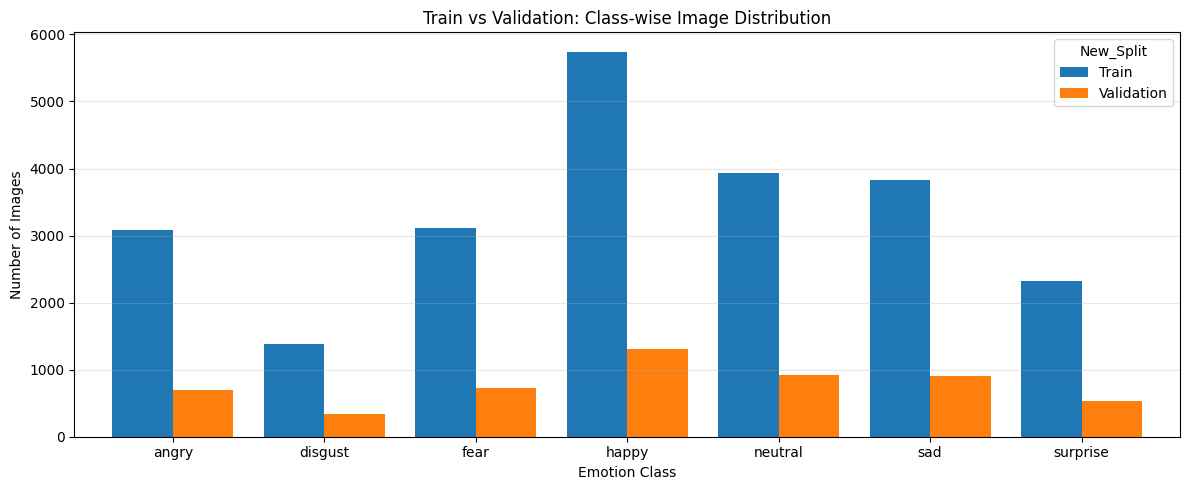

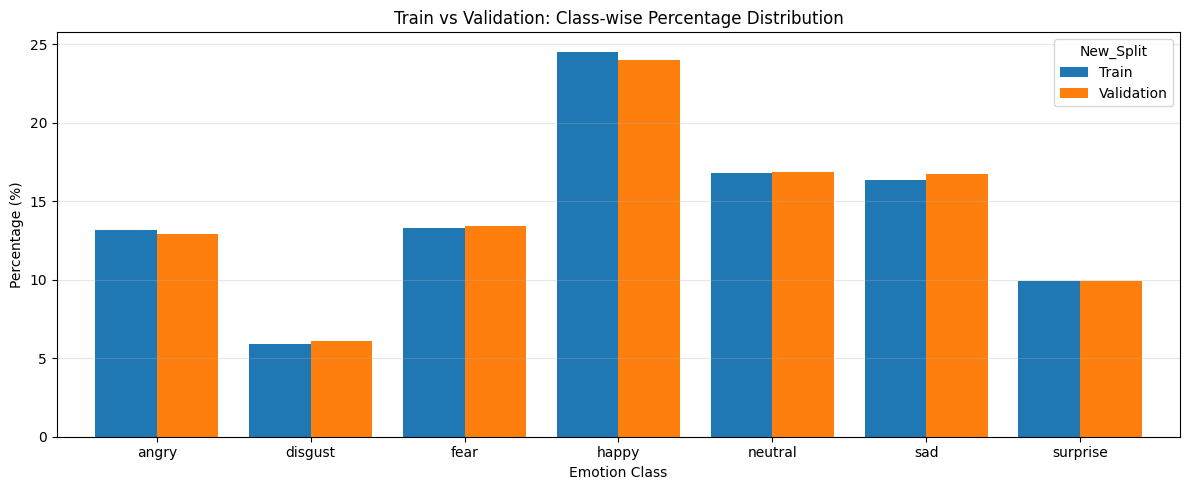


TOTAL TRAIN IMAGES: 23412
TOTAL VALIDATION IMAGES: 5433


In [39]:
# ============================================================
# STEP 3.17: TRAIN-VALIDATION SPLIT QUALITY AUDIT
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load group-aware split manifest
manifest_path = (
    r"E:\Deploy\Facial Expression Detection\FER_Final_Project"
    r"\Audit\FER_Leakage_Audit_Group_Manifest.csv"
)

manifest = pd.read_csv(manifest_path)

# Keep only Train and Validation
tv_data = manifest[
    manifest["New_Split"].isin(["Train", "Validation"])
].copy()

# Class-wise image count
class_counts = pd.crosstab(
    tv_data["Class"],
    tv_data["New_Split"]
)

print("CLASS-WISE IMAGE COUNTS")
display(class_counts)

# Class-wise percentage distribution
class_percentages = (
    class_counts.div(class_counts.sum(axis=0), axis=1) * 100
)

print("\nCLASS-WISE PERCENTAGE DISTRIBUTION")
display(class_percentages.round(2))

# Visualize image counts
class_counts.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("Train vs Validation: Class-wise Image Distribution")
plt.xlabel("Emotion Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Visualize percentage distribution
class_percentages.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("Train vs Validation: Class-wise Percentage Distribution")
plt.xlabel("Emotion Class")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTOTAL TRAIN IMAGES:", len(manifest[manifest["New_Split"] == "Train"]))
print("TOTAL VALIDATION IMAGES:", len(manifest[manifest["New_Split"] == "Validation"]))

In [40]:
# ============================================================
# STEP 3.18: TRAIN-VALIDATION IMAGE INTEGRITY AUDIT
# ============================================================

import os
import cv2
import pandas as pd
from tqdm.notebook import tqdm

PROJECT_ROOT = r"E:\Deploy\Facial Expression Detection"

# Train and Validation data
tv_data = manifest[
    manifest["New_Split"].isin(["Train", "Validation"])
].copy()

missing_files = []
corrupted_files = []
wrong_dimensions = []
non_grayscale = []

for _, row in tqdm(tv_data.iterrows(), total=len(tv_data)):

    image_path = os.path.join(
        PROJECT_ROOT,
        row["Image_Path"]
    )

    if not os.path.exists(image_path):
        missing_files.append(image_path)
        continue

    img = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)

    if img is None:
        corrupted_files.append(image_path)
        continue

    if img.shape[:2] != (48, 48):
        wrong_dimensions.append((image_path, img.shape))

    if len(img.shape) != 2:
        non_grayscale.append((image_path, img.shape))


# Summary
print("========== IMAGE INTEGRITY AUDIT ==========")

print("Total Images Checked:", len(tv_data))
print("Missing Files:", len(missing_files))
print("Corrupted Images:", len(corrupted_files))
print("Wrong Dimensions:", len(wrong_dimensions))
print("Non-Grayscale Images:", len(non_grayscale))


# Show sample issues if any
print("\nSample Missing Files:", missing_files[:5])
print("\nSample Corrupted Files:", corrupted_files[:5])
print("\nSample Wrong Dimensions:", wrong_dimensions[:5])
print("\nSample Non-Grayscale Images:", non_grayscale[:5])

  0%|          | 0/28845 [00:00<?, ?it/s]

========== IMAGE INTEGRITY AUDIT ==========
Total Images Checked: 28845
Missing Files: 0
Corrupted Images: 0
Wrong Dimensions: 0
Non-Grayscale Images: 0

Sample Missing Files: []

Sample Corrupted Files: []

Sample Wrong Dimensions: []

Sample Non-Grayscale Images: []


In [41]:
# ============================================================
# STEP 3.19: TRAIN-VALIDATION IMAGE HASH CONSISTENCY AUDIT
# ============================================================

import os
import hashlib
import pandas as pd
from tqdm.notebook import tqdm

PROJECT_ROOT = r"E:\Deploy\Facial Expression Detection"

tv_data = manifest[
    manifest["New_Split"].isin(["Train", "Validation"])
].copy()

actual_hashes = []

for _, row in tqdm(tv_data.iterrows(), total=len(tv_data)):

    image_path = os.path.join(
        PROJECT_ROOT,
        row["Image_Path"]
    )

    with open(image_path, "rb") as f:
        actual_hash = hashlib.sha256(f.read()).hexdigest()

    actual_hashes.append(actual_hash)

tv_data["Actual_SHA256"] = actual_hashes

# Compare calculated hashes with manifest hashes
hash_mismatch = (
    tv_data["Actual_SHA256"] != tv_data["SHA256"]
)

print("Total Images Checked:", len(tv_data))
print("Manifest Hash Mismatches:", hash_mismatch.sum())

# Exact duplicate check across Train and Validation
duplicate_hashes = tv_data.groupby("Actual_SHA256")[
    "New_Split"
].nunique()

cross_split_duplicates = duplicate_hashes[
    duplicate_hashes > 1
]

print("Exact Duplicate Hashes Across Train-Validation:",
      len(cross_split_duplicates))

print("\nAudit Completed.")

  0%|          | 0/28845 [00:00<?, ?it/s]

Total Images Checked: 28845
Manifest Hash Mismatches: 0
Exact Duplicate Hashes Across Train-Validation: 0

Audit Completed.


## Train–Validation Image Quality Analysis (Blur, Contrast & Brightness)

  0%|          | 0/28845 [00:00<?, ?it/s]

Total Images Analysed: 28845

OVERALL IMAGE QUALITY STATISTICS


Blur_Score                                    Contrast         \
                 mean      std   median    min       max     mean    std   
New_Split                                                                  
Train         2426.81  1642.07  2115.68   0.00  31771.74    54.11  13.67   
Validation    2437.72  1605.11  2153.08  80.83  26107.17    54.33  13.67   

                                 Brightness                                
           median    min     max       mean    std  median    min     max  
New_Split                                                                  
Train       53.68   0.00  112.52     128.84  33.45  128.75   0.00  245.42  
Validation  53.86  12.48  113.93     129.04  33.52  129.44  19.49  247.95


CLASS-WISE IMAGE QUALITY STATISTICS


Blur_Score  Contrast  Brightness
Class    New_Split                                   
angry    Train          2547.62     54.74      126.16
         Validation     2438.13     53.72      126.78
disgust  Train          3056.33     54.22      130.63
         Validation     3210.04     56.07      133.79
fear     Train          2609.64     54.95      134.90
         Validation     2606.02     55.08      135.61
happy    Train          2282.56     53.09      128.70
         Validation     2299.44     53.47      128.96
neutral  Train          2205.72     54.26      124.38
         Validation     2273.93     55.18      122.72
sad      Train          2153.41     53.50      120.45
         Validation     2171.13     53.40      120.85
surprise Train          2829.29     55.42      144.92
         Validation     2795.21     55.27      144.88

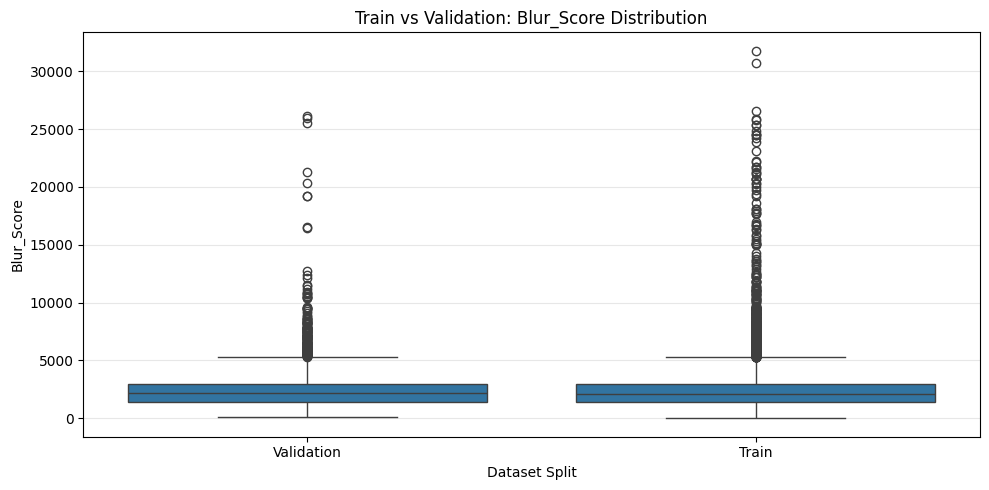

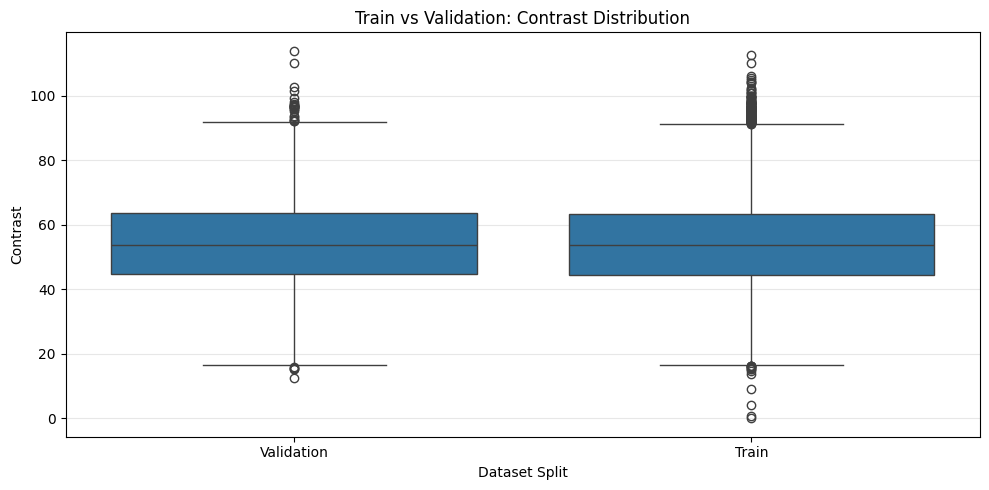

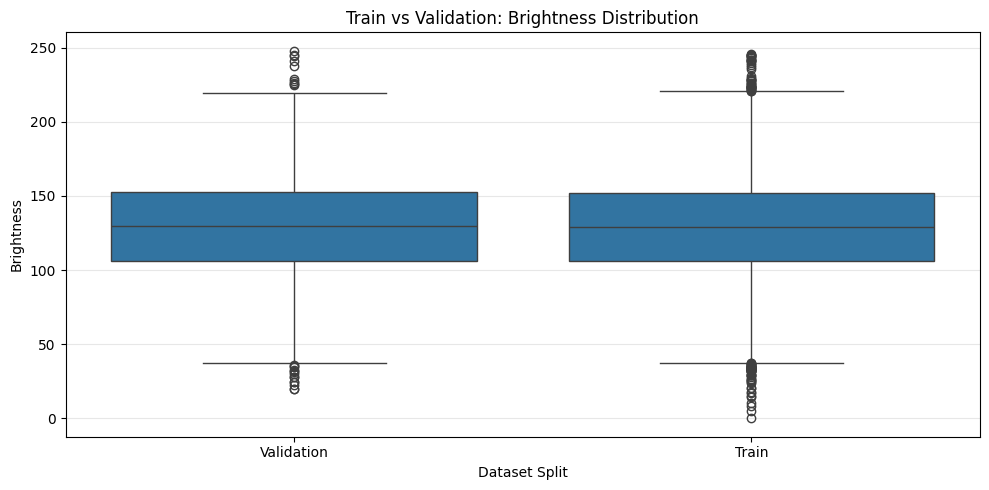

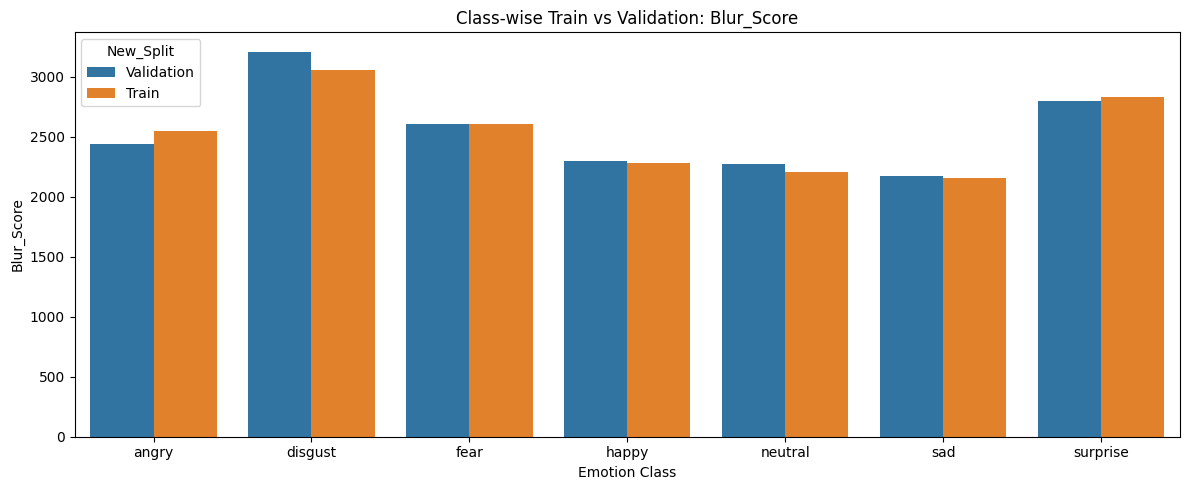

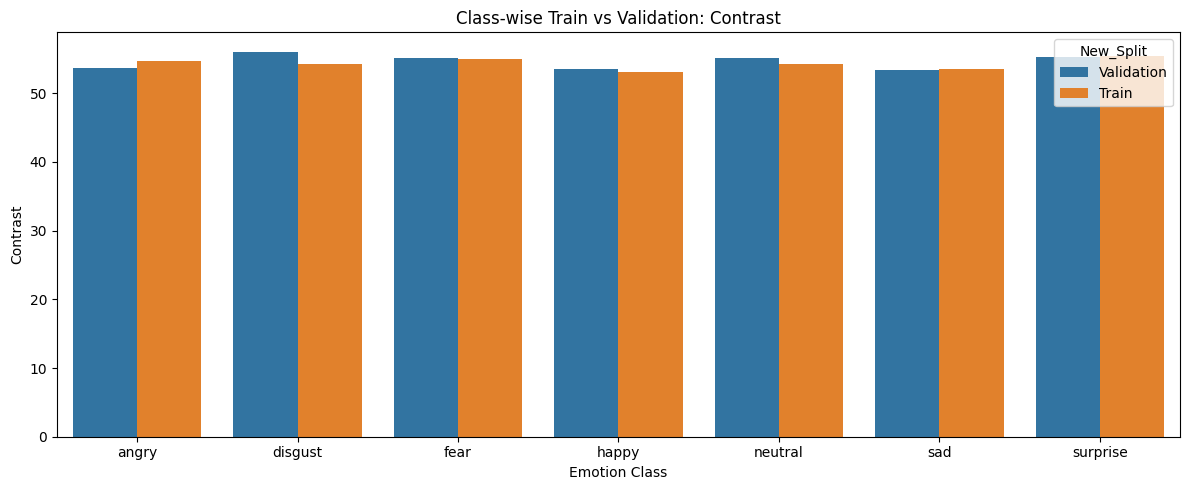

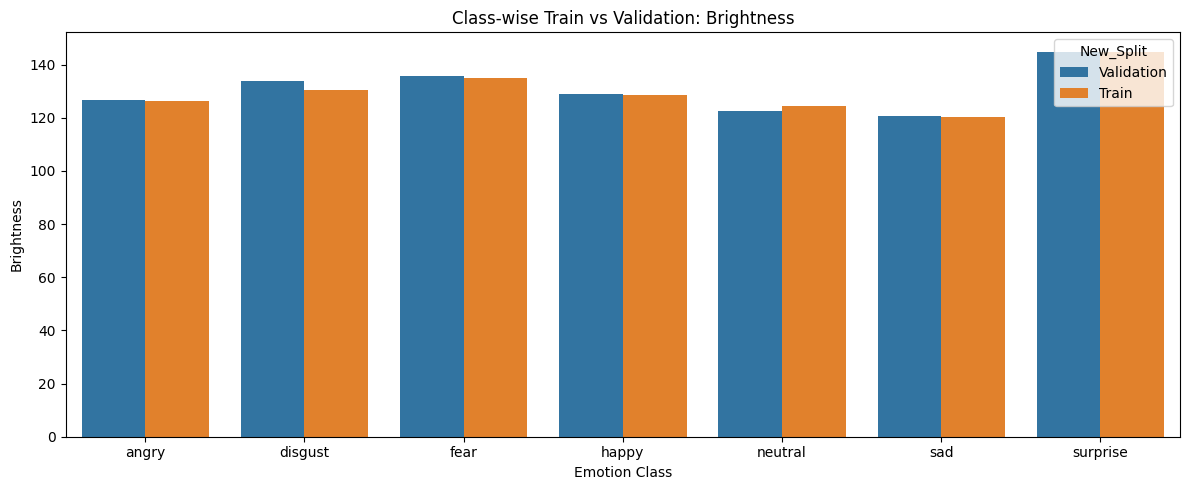


Audit results saved successfully.


In [42]:
# ============================================================
# STEP 3.20: TRAIN-VALIDATION IMAGE QUALITY ANALYSIS
# Blur, Contrast and Brightness
# ============================================================

import os
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

PROJECT_ROOT = r"E:\Deploy\Facial Expression Detection"

# Select Train and Validation images
tv_data = manifest[
    manifest["New_Split"].isin(["Train", "Validation"])
].copy()

quality_results = []

for _, row in tqdm(tv_data.iterrows(), total=len(tv_data)):

    image_path = os.path.join(
        PROJECT_ROOT,
        row["Image_Path"]
    )

    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

    if img is None:
        continue

    # Calculate image quality metrics
    blur_score = cv2.Laplacian(
        img, cv2.CV_64F
    ).var()

    contrast = img.std()
    brightness = img.mean()

    quality_results.append({
        "Class": row["Class"],
        "New_Split": row["New_Split"],
        "Blur_Score": blur_score,
        "Contrast": contrast,
        "Brightness": brightness
    })


# Create DataFrame
quality_df = pd.DataFrame(quality_results)

print("Total Images Analysed:", len(quality_df))


# ------------------------------------------------------------
# 1. Overall Train vs Validation Statistics
# ------------------------------------------------------------

print("\nOVERALL IMAGE QUALITY STATISTICS")

overall_stats = quality_df.groupby("New_Split")[
    ["Blur_Score", "Contrast", "Brightness"]
].agg(["mean", "std", "median", "min", "max"])

display(overall_stats.round(2))


# ------------------------------------------------------------
# 2. Class-wise Image Quality Statistics
# ------------------------------------------------------------

print("\nCLASS-WISE IMAGE QUALITY STATISTICS")

class_stats = quality_df.groupby(
    ["Class", "New_Split"]
)[
    ["Blur_Score", "Contrast", "Brightness"]
].mean().round(2)

display(class_stats)


# ------------------------------------------------------------
# 3. Train vs Validation Distribution Plots
# ------------------------------------------------------------

metrics = [
    "Blur_Score",
    "Contrast",
    "Brightness"
]

for metric in metrics:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=quality_df,
        x="New_Split",
        y=metric
    )

    plt.title(f"Train vs Validation: {metric} Distribution")
    plt.xlabel("Dataset Split")
    plt.ylabel(metric)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 4. Class-wise Comparison
# ------------------------------------------------------------

for metric in metrics:

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=quality_df,
        x="Class",
        y=metric,
        hue="New_Split",
        errorbar=None
    )

    plt.title(f"Class-wise Train vs Validation: {metric}")
    plt.xlabel("Emotion Class")
    plt.ylabel(metric)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 5. Save Results
# ------------------------------------------------------------

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

quality_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "train_validation_image_quality_audit.csv"
    ),
    index=False
)

overall_stats.to_csv(
    os.path.join(
        RESULTS_DIR,
        "train_validation_overall_quality_summary.csv"
    )
)

class_stats.to_csv(
    os.path.join(
        RESULTS_DIR,
        "train_validation_class_quality_summary.csv"
    )
)

print("\nAudit results saved successfully.")

## Statistical Comparison of Train–Validation Image Quality (Mann–Whitney U Test & Kolmogorov–Smirnov Test)

In [43]:
# ============================================================
# STEP 3.21: STATISTICAL COMPARISON OF TRAIN-VALIDATION
# Mann-Whitney U Test and Kolmogorov-Smirnov Test
# ============================================================

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, ks_2samp

# Use existing quality_df from Step 3.20

metrics = [
    "Blur_Score",
    "Contrast",
    "Brightness"
]

results = []

ALPHA = 0.05

for metric in metrics:

    train_values = quality_df.loc[
        quality_df["New_Split"] == "Train", metric
    ].dropna()

    val_values = quality_df.loc[
        quality_df["New_Split"] == "Validation", metric
    ].dropna()

    # Mann-Whitney U Test
    mw_stat, mw_p = mannwhitneyu(
        train_values,
        val_values,
        alternative="two-sided"
    )

    # Kolmogorov-Smirnov Test
    ks_stat, ks_p = ks_2samp(
        train_values,
        val_values,
        alternative="two-sided"
    )

    results.append({
        "Metric": metric,
        "Train_Median": train_values.median(),
        "Validation_Median": val_values.median(),
        "MW_U_Statistic": mw_stat,
        "MW_P_Value": mw_p,
        "MW_Result": (
            "Significant Difference"
            if mw_p < ALPHA
            else "No Significant Difference"
        ),
        "KS_Statistic": ks_stat,
        "KS_P_Value": ks_p,
        "KS_Result": (
            "Significant Distribution Difference"
            if ks_p < ALPHA
            else "No Significant Distribution Difference"
        )
    })


# Display results
statistical_results = pd.DataFrame(results)

print("========== STATISTICAL TEST RESULTS ==========")

display(
    statistical_results.round(6)
)


# ------------------------------------------------------------
# Overall interpretation
# ------------------------------------------------------------

print("\n========== INTERPRETATION ==========")

for _, row in statistical_results.iterrows():

    print(f"\nMetric: {row['Metric']}")

    print(
        "Mann-Whitney U:",
        row["MW_Result"],
        f"(p-value = {row['MW_P_Value']:.6f})"
    )

    print(
        "Kolmogorov-Smirnov:",
        row["KS_Result"],
        f"(p-value = {row['KS_P_Value']:.6f})"
    )


# ------------------------------------------------------------
# Save results
# ------------------------------------------------------------

import os

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

output_path = os.path.join(
    RESULTS_DIR,
    "train_validation_statistical_tests.csv"
)

statistical_results.to_csv(
    output_path,
    index=False
)

print("\nResults saved at:")
print(output_path)

========== STATISTICAL TEST RESULTS ==========


,Metric,Train_Median,Validation_Median,MW_U_Statistic,MW_P_Value,MW_Result,KS_Statistic,KS_P_Value,KS_Result
0,Blur_Score,2115.683926,2153.076764,63057644.0,0.327840,No Significant Difference,0.016881,0.160088,No Significant Distribution Difference
1,Contrast,53.683118,53.856190,62990566.0,0.271428,No Significant Difference,0.011161,0.637850,No Significant Distribution Difference
2,Brightness,128.746094,129.441406,63185596.0,0.455017,No Significant Difference,0.010676,0.692039,No Significant Distribution Difference



========== INTERPRETATION ==========

Metric: Blur_Score
Mann-Whitney U: No Significant Difference (p-value = 0.327840)
Kolmogorov-Smirnov: No Significant Distribution Difference (p-value = 0.160088)

Metric: Contrast
Mann-Whitney U: No Significant Difference (p-value = 0.271428)
Kolmogorov-Smirnov: No Significant Distribution Difference (p-value = 0.637850)

Metric: Brightness
Mann-Whitney U: No Significant Difference (p-value = 0.455017)
Kolmogorov-Smirnov: No Significant Distribution Difference (p-value = 0.692039)

Results saved at:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results\train_validation_statistical_tests.csv


### Class-wise Train–Validation Image Quality Statistical Analysis

In [44]:
# ============================================================
# STEP 3.22: CLASS-WISE TRAIN-VALIDATION STATISTICAL ANALYSIS
# Mann-Whitney U Test + KS Test + Holm Correction
# ============================================================

import numpy as np
import pandas as pd
import os

from scipy.stats import mannwhitneyu, ks_2samp

# Existing quality_df from Step 3.20
metrics = ["Blur_Score", "Contrast", "Brightness"]

classes = sorted(quality_df["Class"].unique())

ALPHA = 0.05
results = []

# ------------------------------------------------------------
# 1. Perform statistical tests class-wise
# ------------------------------------------------------------

for emotion in classes:

    class_data = quality_df[
        quality_df["Class"] == emotion
    ]

    for metric in metrics:

        train_values = class_data.loc[
            class_data["New_Split"] == "Train",
            metric
        ].dropna()

        val_values = class_data.loc[
            class_data["New_Split"] == "Validation",
            metric
        ].dropna()

        # Mann-Whitney U Test
        mw_stat, mw_p = mannwhitneyu(
            train_values,
            val_values,
            alternative="two-sided"
        )

        # Kolmogorov-Smirnov Test
        ks_stat, ks_p = ks_2samp(
            train_values,
            val_values,
            alternative="two-sided"
        )

        results.append({
            "Class": emotion,
            "Metric": metric,
            "Train_Count": len(train_values),
            "Validation_Count": len(val_values),
            "Train_Median": train_values.median(),
            "Validation_Median": val_values.median(),
            "MW_U_Statistic": mw_stat,
            "MW_P_Value": mw_p,
            "KS_Statistic": ks_stat,
            "KS_P_Value": ks_p
        })


classwise_results = pd.DataFrame(results)


# ------------------------------------------------------------
# 2. Apply Holm correction to all 42 p-values
# ------------------------------------------------------------

def holm_correction(p_values):

    p_values = np.asarray(p_values, dtype=float)

    n = len(p_values)
    order = np.argsort(p_values)

    sorted_p = p_values[order]

    adjusted_sorted = np.maximum.accumulate(
        (n - np.arange(n)) * sorted_p
    )

    adjusted_sorted = np.minimum(adjusted_sorted, 1.0)

    adjusted = np.empty(n)
    adjusted[order] = adjusted_sorted

    return adjusted


# Correct Mann-Whitney p-values
classwise_results["MW_Adjusted_P"] = holm_correction(
    classwise_results["MW_P_Value"]
)

# Correct KS p-values
classwise_results["KS_Adjusted_P"] = holm_correction(
    classwise_results["KS_P_Value"]
)


# ------------------------------------------------------------
# 3. Interpret adjusted p-values
# ------------------------------------------------------------

classwise_results["MW_Result"] = np.where(
    classwise_results["MW_Adjusted_P"] < ALPHA,
    "Significant Difference",
    "No Significant Difference"
)

classwise_results["KS_Result"] = np.where(
    classwise_results["KS_Adjusted_P"] < ALPHA,
    "Significant Distribution Difference",
    "No Significant Distribution Difference"
)


# ------------------------------------------------------------
# 4. Display complete results
# ------------------------------------------------------------

print("========== CLASS-WISE STATISTICAL TEST RESULTS ==========")

display(
    classwise_results.round(6)
)


# ------------------------------------------------------------
# 5. Display only significant findings
# ------------------------------------------------------------

significant_results = classwise_results[
    (classwise_results["MW_Adjusted_P"] < ALPHA) |
    (classwise_results["KS_Adjusted_P"] < ALPHA)
]

print("\n========== SIGNIFICANT DIFFERENCES ==========")

if len(significant_results) == 0:
    print("No statistically significant differences found.")
else:
    display(significant_results.round(6))


# ------------------------------------------------------------
# 6. Summary by emotion class
# ------------------------------------------------------------

summary = classwise_results.groupby("Class").agg(
    MW_Significant_Count=(
        "MW_Result",
        lambda x: (x == "Significant Difference").sum()
    ),
    KS_Significant_Count=(
        "KS_Result",
        lambda x: (
            x == "Significant Distribution Difference"
        ).sum()
    )
)

print("\n========== CLASS-WISE SUMMARY ==========")
display(summary)


# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

classwise_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classwise_train_validation_statistical_tests.csv"
    ),
    index=False
)

significant_results.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classwise_significant_differences.csv"
    ),
    index=False
)

summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "classwise_statistical_summary.csv"
    )
)

print("\nAll class-wise statistical results saved successfully.")

========== CLASS-WISE STATISTICAL TEST RESULTS ==========


,Class,Metric,Train_Count,Validation_Count,Train_Median,Validation_Median,MW_U_Statistic,MW_P_Value,KS_Statistic,KS_P_Value,MW_Adjusted_P,KS_Adjusted_P,MW_Result,KS_Result
0,angry,Blur_Score,3082,701,2228.796883,2091.606478,1146682.0,0.010912,0.060601,0.028726,0.229157,0.574511,No Significant Difference,No Significant Distribution Difference
1,angry,Contrast,3082,701,54.240357,53.114862,1131388.0,0.050049,0.052056,0.086916,0.900878,1.000000,No Significant Difference,No Significant Distribution Difference
2,angry,Brightness,3082,701,126.942274,127.139323,1069933.0,0.692913,0.024965,0.858213,1.000000,1.000000,No Significant Difference,No Significant Distribution Difference
3,disgust,Blur_Score,1380,332,2662.288720,3012.414365,217767.0,0.161867,0.083971,0.042937,1.000000,0.815802,No Significant Difference,No Significant Distribution Difference
4,disgust,Contrast,1380,332,53.466773,55.691494,212873.0,0.045073,0.091566,0.020879,0.856379,0.438449,No Significant Difference,No Significant Distribution Difference
5,disgust,Brightness,1380,332,128.579210,132.904514,212479.0,0.040102,0.076096,0.084903,0.802042,1.000000,No Significant Difference,No Significant Distribution Difference
6,fear,Blur_Score,3116,731,2198.343505,2293.737627,1104627.0,0.204780,0.053370,0.065742,1.000000,1.000000,No Significant Difference,No Significant Distribution Difference
7,fear,Contrast,3116,731,54.550645,54.243929,1136588.0,0.931900,0.034684,0.462499,1.000000,1.000000,No Significant Difference,No Significant Distribution Difference
8,fear,Brightness,3116,731,136.529948,137.565538,1118503.0,0.450477,0.040211,0.284873,1.000000,1.000000,No Significant Difference,No Significant Distribution Difference
9,happy,Blur_Score,5744,1304,2039.208758,2089.057484,3666558.0,0.236454,0.037736,0.094139,1.000000,1.000000,No Significant Difference,No Significant Distribution Difference



========== SIGNIFICANT DIFFERENCES ==========
No statistically significant differences found.

========== CLASS-WISE SUMMARY ==========


,MW_Significant_Count,KS_Significant_Count
Class,,
angry,0,0
disgust,0,0
fear,0,0
happy,0,0
neutral,0,0
sad,0,0
surprise,0,0



All class-wise statistical results saved successfully.


# Dataset Finalization & Model Validation

In [45]:
# ============================================================
# STEP 3.23: DATASET AUDIT FINAL SUMMARY
# ============================================================

import os
import pandas as pd
import json
from datetime import datetime

RESULTS_DIR = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Dataset Split Summary
# ------------------------------------------------------------

split_counts = manifest["New_Split"].value_counts()

# ------------------------------------------------------------
# 2. Leakage Audit
# ------------------------------------------------------------

group_leakage = (
    manifest.groupby("Group_ID")["New_Split"].nunique() > 1
).sum()

sha_leakage = (
    manifest.groupby("SHA256")["New_Split"].nunique() > 1
).sum()

# ------------------------------------------------------------
# 3. Train-Validation Image Integrity
# ------------------------------------------------------------

integrity_summary = {
    "Total_Images_Checked": len(tv_data),
    "Missing_Files": len(missing_files),
    "Corrupted_Images": len(corrupted_files),
    "Wrong_Dimensions": len(wrong_dimensions),
    "Non_Grayscale_Images": len(non_grayscale)
}

# ------------------------------------------------------------
# 4. Hash Consistency
# ------------------------------------------------------------

hash_summary = {
    "Total_Images_Checked": len(tv_data),
    "Manifest_Hash_Mismatches": int(hash_mismatch.sum()),
    "Cross_Split_Exact_Duplicates": len(cross_split_duplicates)
}

# ------------------------------------------------------------
# 5. Statistical Test Summary
# ------------------------------------------------------------

overall_statistical_summary = statistical_results[
    [
        "Metric",
        "MW_P_Value",
        "MW_Result",
        "KS_P_Value",
        "KS_Result"
    ]
].copy()

classwise_significant_count = len(significant_results)

# ------------------------------------------------------------
# 6. Prepare Final Audit Report
# ------------------------------------------------------------

audit_report = {
    "Audit_Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),

    "Dataset_Split": {
        "Train": int(split_counts.get("Train", 0)),
        "Validation": int(split_counts.get("Validation", 0)),
        "Test": int(split_counts.get("Test", 0)),
        "Total": int(len(manifest))
    },

    "Leakage_Audit": {
        "Groups_Crossing_Splits": int(group_leakage),
        "SHA256_Duplicates_Across_Splits": int(sha_leakage)
    },

    "Image_Integrity_Audit": integrity_summary,

    "Hash_Consistency_Audit": hash_summary,

    "Overall_Statistical_Tests": (
        overall_statistical_summary.to_dict(orient="records")
    ),

    "Classwise_Significant_Differences": (
        int(classwise_significant_count)
    )
}

# ------------------------------------------------------------
# 7. Save JSON Report
# ------------------------------------------------------------

json_path = os.path.join(
    RESULTS_DIR,
    "FER_Final_Dataset_Audit_Report.json"
)

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(audit_report, f, indent=4)

# ------------------------------------------------------------
# 8. Save Text Summary
# ------------------------------------------------------------

txt_path = os.path.join(
    RESULTS_DIR,
    "FER_Final_Dataset_Audit_Summary.txt"
)

with open(txt_path, "w", encoding="utf-8") as f:

    f.write("FACIAL EMOTION RECOGNITION - DATASET AUDIT REPORT\n")
    f.write("=" * 60 + "\n\n")

    f.write(f"Audit Date: {audit_report['Audit_Date']}\n\n")

    f.write("DATASET SPLIT\n")
    f.write("-" * 40 + "\n")

    for key, value in audit_report["Dataset_Split"].items():
        f.write(f"{key}: {value}\n")

    f.write("\nLEAKAGE AUDIT\n")
    f.write("-" * 40 + "\n")

    for key, value in audit_report["Leakage_Audit"].items():
        f.write(f"{key}: {value}\n")

    f.write("\nIMAGE INTEGRITY AUDIT\n")
    f.write("-" * 40 + "\n")

    for key, value in integrity_summary.items():
        f.write(f"{key}: {value}\n")

    f.write("\nHASH CONSISTENCY AUDIT\n")
    f.write("-" * 40 + "\n")

    for key, value in hash_summary.items():
        f.write(f"{key}: {value}\n")

    f.write("\nCLASS-WISE SIGNIFICANT DIFFERENCES\n")
    f.write("-" * 40 + "\n")

    f.write(f"Significant Comparisons: {classwise_significant_count}\n")

    f.write("\nOVERALL STATISTICAL TESTS\n")
    f.write("-" * 40 + "\n")

    f.write(overall_statistical_summary.to_string(index=False))

# ------------------------------------------------------------
# 9. Display Final Summary
# ------------------------------------------------------------

print("=" * 60)
print("FINAL DATASET AUDIT SUMMARY")
print("=" * 60)

print("\nDataset Split:")
print(audit_report["Dataset_Split"])

print("\nLeakage Audit:")
print(audit_report["Leakage_Audit"])

print("\nImage Integrity:")
print(integrity_summary)

print("\nHash Consistency:")
print(hash_summary)

print("\nClass-wise Significant Differences:",
      classwise_significant_count)

print("\nJSON Report Saved:", json_path)
print("Text Summary Saved:", txt_path)

print("\nDATASET AUDIT REPORT GENERATED SUCCESSFULLY.")

FINAL DATASET AUDIT SUMMARY

Dataset Split:
{'Train': 23412, 'Validation': 5433, 'Test': 7139, 'Total': 35984}

Leakage Audit:
{'Groups_Crossing_Splits': 0, 'SHA256_Duplicates_Across_Splits': 0}

Image Integrity:
{'Total_Images_Checked': 28845, 'Missing_Files': 0, 'Corrupted_Images': 0, 'Wrong_Dimensions': 0, 'Non_Grayscale_Images': 0}

Hash Consistency:
{'Total_Images_Checked': 28845, 'Manifest_Hash_Mismatches': 0, 'Cross_Split_Exact_Duplicates': 0}

Class-wise Significant Differences: 0

JSON Report Saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results\FER_Final_Dataset_Audit_Report.json
Text Summary Saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Results\FER_Final_Dataset_Audit_Summary.txt

DATASET AUDIT REPORT GENERATED SUCCESSFULLY.


In [46]:
# ============================================================
# STEP 3.24: DATASET FREEZE & SPLIT MANIFEST PRESERVATION
# ============================================================

import os
import json
import hashlib
import pandas as pd
from datetime import datetime

# Output directory
FREEZE_DIR = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Dataset_Freeze"
)

os.makedirs(FREEZE_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Validate final manifest
# ------------------------------------------------------------

required_columns = [
    "Image_Path",
    "Class",
    "SHA256",
    "pHash",
    "Group_ID",
    "Old_Partitions",
    "New_Split"
]

assert all(col in manifest.columns for col in required_columns), \
    "Required manifest columns are missing!"

assert manifest["Image_Path"].is_unique, \
    "Duplicate image paths found!"

assert manifest["New_Split"].notna().all(), \
    "Missing split labels found!"

# Verify group leakage
group_leakage = (
    manifest.groupby("Group_ID")["New_Split"].nunique() > 1
).sum()

# Verify exact hash leakage
hash_leakage = (
    manifest.groupby("SHA256")["New_Split"].nunique() > 1
).sum()

assert group_leakage == 0, "Group leakage detected!"
assert hash_leakage == 0, "SHA256 leakage detected!"

# ------------------------------------------------------------
# 2. Save frozen manifest snapshot
# ------------------------------------------------------------

frozen_manifest_path = os.path.join(
    FREEZE_DIR,
    "FER_Final_Frozen_Split_Manifest.csv"
)

manifest.to_csv(
    frozen_manifest_path,
    index=False
)

# ------------------------------------------------------------
# 3. Calculate manifest file checksum
# ------------------------------------------------------------

sha256 = hashlib.sha256()

with open(frozen_manifest_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

manifest_checksum = sha256.hexdigest()

# ------------------------------------------------------------
# 4. Save split counts
# ------------------------------------------------------------

split_counts = (
    manifest["New_Split"]
    .value_counts()
    .reindex(["Train", "Validation", "Test"], fill_value=0)
)

split_summary = split_counts.rename_axis(
    "Split"
).reset_index(name="Image_Count")

split_summary_path = os.path.join(
    FREEZE_DIR,
    "FER_Final_Split_Counts.csv"
)

split_summary.to_csv(
    split_summary_path,
    index=False
)

# ------------------------------------------------------------
# 5. Create freeze metadata
# ------------------------------------------------------------

freeze_metadata = {
    "Freeze_Date": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "Dataset_Total_Images": int(len(manifest)),
    "Train_Images": int(split_counts["Train"]),
    "Validation_Images": int(split_counts["Validation"]),
    "Test_Images": int(split_counts["Test"]),
    "Number_of_Classes": int(manifest["Class"].nunique()),
    "Classes": sorted(manifest["Class"].unique().tolist()),
    "Group_Leakage": int(group_leakage),
    "SHA256_Cross_Split_Leakage": int(hash_leakage),
    "Frozen_Manifest_SHA256": manifest_checksum,
    "Manifest_File": os.path.basename(frozen_manifest_path),
    "Dataset_Modified": False
}

metadata_path = os.path.join(
    FREEZE_DIR,
    "FER_Dataset_Freeze_Metadata.json"
)

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(freeze_metadata, f, indent=4)

# ------------------------------------------------------------
# 6. Final verification
# ------------------------------------------------------------

saved_manifest = pd.read_csv(frozen_manifest_path)

assert len(saved_manifest) == len(manifest)
assert saved_manifest["SHA256"].equals(manifest["SHA256"])
assert saved_manifest["New_Split"].equals(manifest["New_Split"])

print("=" * 60)
print("DATASET FREEZE COMPLETED")
print("=" * 60)

print("\nSplit Counts:")
display(split_summary)

print("\nTotal Images:", len(saved_manifest))
print("Group Leakage:", group_leakage)
print("SHA256 Leakage:", hash_leakage)

print("\nManifest SHA256:")
print(manifest_checksum)

print("\nFrozen Manifest:", frozen_manifest_path)
print("Split Summary:", split_summary_path)
print("Freeze Metadata:", metadata_path)

print("\nDATASET SNAPSHOT VERIFIED SUCCESSFULLY.")

DATASET FREEZE COMPLETED

Split Counts:


,Split,Image_Count
0,Train,23412
1,Validation,5433
2,Test,7139



Total Images: 35984
Group Leakage: 0
SHA256 Leakage: 0

Manifest SHA256:
d18b673a5fcd49858a40f465a7ec6fc2905b25d808993544082b442900a11c61

Frozen Manifest: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Dataset_Freeze\FER_Final_Frozen_Split_Manifest.csv
Split Summary: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Dataset_Freeze\FER_Final_Split_Counts.csv
Freeze Metadata: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Dataset_Freeze\FER_Dataset_Freeze_Metadata.json

DATASET SNAPSHOT VERIFIED SUCCESSFULLY.


## Existing SE-ResNet Model Performance Review & Error Analysis

In [49]:
# ============================================================
# DEBUG: CLASSIFICATION REPORT FORMAT
# ============================================================

print("Classification Report Columns:")
print(classification_report.columns.tolist())

print("\nClassification Report Shape:")
print(classification_report.shape)

print("\nClassification Report First 15 Rows:")
display(classification_report.head(15))

print("\nClass Names:")
print(class_names)

Classification Report Columns:
['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']

Classification Report Shape:
(10, 5)

Classification Report First 15 Rows:


,Unnamed: 0,precision,recall,f1-score,support
0,Angry,0.518061,0.571279,0.543370,954.000000
1,Disgust,0.922449,0.615804,0.738562,367.000000
2,Fear,0.474293,0.376915,0.420034,979.000000
3,Happy,0.847603,0.849057,0.848329,1749.000000
4,Neutral,0.587097,0.680233,0.630242,1204.000000
5,Sad,0.474411,0.499572,0.486667,1169.000000
6,Surprise,0.727405,0.695955,0.711333,717.000000
7,accuracy,0.634122,0.634122,0.634122,0.634122
8,macro avg,0.650188,0.612688,0.625505,7139.000000
9,weighted avg,0.639103,0.634122,0.633439,7139.000000



Class Names:
['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']


CLASS-WISE PERFORMANCE


,precision,recall,f1-score,support
Class,,,,
Angry,0.5181,0.5713,0.5434,954.0
Disgust,0.9224,0.6158,0.7386,367.0
Fear,0.4743,0.3769,0.4200,979.0
Happy,0.8476,0.8491,0.8483,1749.0
Neutral,0.5871,0.6802,0.6302,1204.0
Sad,0.4744,0.4996,0.4867,1169.0
Surprise,0.7274,0.6960,0.7113,717.0


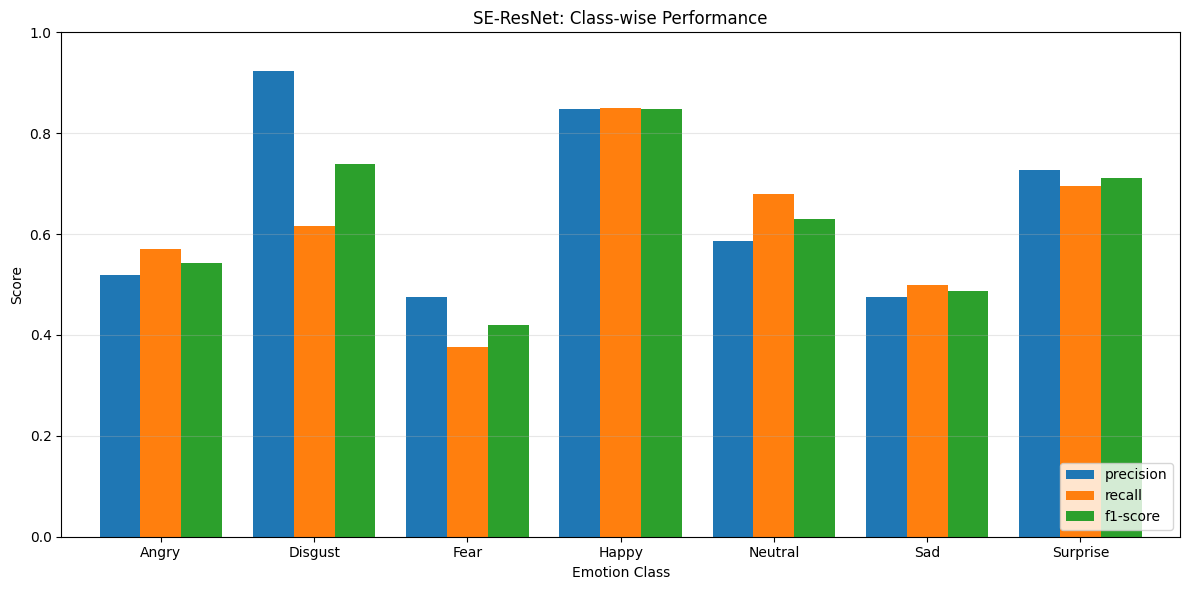


CLASS-WISE RECALL RANKING


,recall,f1-score
Class,,
Fear,0.3769,0.4200
Sad,0.4996,0.4867
Angry,0.5713,0.5434
Disgust,0.6158,0.7386
Neutral,0.6802,0.6302
Surprise,0.6960,0.7113
Happy,0.8491,0.8483



PREDICTION SUMMARY
Total: 7139
Correct: 4527
Wrong: 2612

TOP 15 MISCLASSIFICATION PAIRS


,Actual_Label,Predicted_Label,Count
33,Sad,Neutral,243
16,Fear,Sad,230
27,Neutral,Sad,169
4,Angry,Sad,145
12,Fear,Angry,143
31,Sad,Fear,140
29,Sad,Angry,129
3,Angry,Neutral,108
15,Fear,Neutral,106
21,Happy,Neutral,92



CONFIDENCE ANALYSIS


,count,mean,median,min,max
Prediction_Status,,,,,
Correct,4527,0.8016,0.8739,0.2657,0.9804
Wrong,2612,0.6278,0.6138,0.2371,0.9740


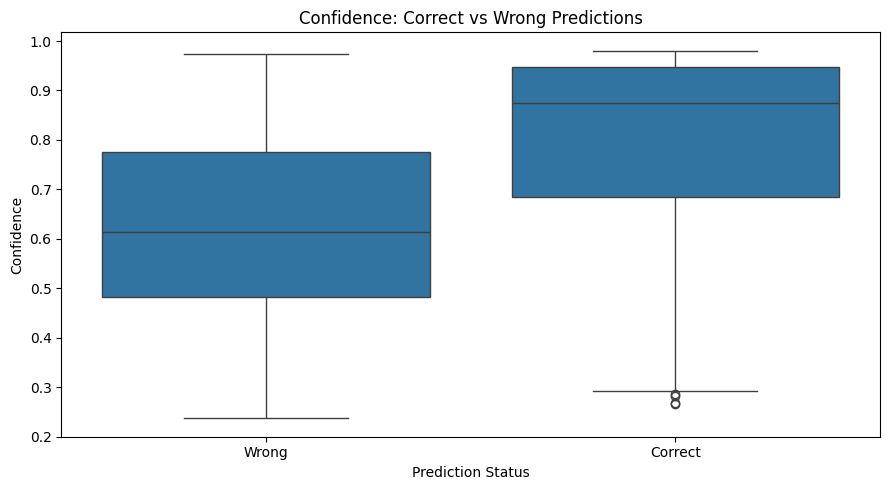


HIGH-CONFIDENCE WRONG PREDICTIONS
Total: 565


,Image_Path,Actual_Label,Predicted_Label,Confidence
5,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,0.845904
14,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Neutral,0.839722
20,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,0.839988
33,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Disgust,0.928325
37,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,0.934466
65,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Sad,0.825832
99,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Happy,0.804568
102,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Happy,0.865867
105,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Surprise,0.814811
133,E:\Deploy\Facial Expression Detection\Data Set...,Angry,Surprise,0.814236



STEP 3.25 ANALYSIS COMPLETED.


In [48]:
# ============================================================
# STEP 3.25: FIXED CLASS-WISE PERFORMANCE & ERROR ANALYSIS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. Fix Classification Report
# ------------------------------------------------------------

report = classification_report.copy()

report = report.rename(
    columns={"Unnamed: 0": "Class"}
)

report["Class"] = report["Class"].astype(str).str.strip()

class_names = [
    "Angry", "Disgust", "Fear",
    "Happy", "Neutral", "Sad", "Surprise"
]

class_report = report[
    report["Class"].isin(class_names)
].copy()

class_report = class_report.set_index("Class")

print("CLASS-WISE PERFORMANCE")
display(class_report.round(4))


# ------------------------------------------------------------
# 2. Class-wise Precision, Recall and F1-score
# ------------------------------------------------------------

metrics = ["precision", "recall", "f1-score"]

class_report[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("SE-ResNet: Class-wise Performance")
plt.xlabel("Emotion Class")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Class-wise Recall Ranking
# ------------------------------------------------------------

print("\nCLASS-WISE RECALL RANKING")

recall_ranking = class_report[
    ["recall", "f1-score"]
].sort_values("recall", ascending=True)

display(recall_ranking.round(4))


# ------------------------------------------------------------
# 4. Misclassification Analysis
# ------------------------------------------------------------

wrong_predictions = test_predictions[
    test_predictions["Actual_Label"] !=
    test_predictions["Predicted_Label"]
].copy()

correct_predictions = test_predictions[
    test_predictions["Actual_Label"] ==
    test_predictions["Predicted_Label"]
].copy()

print("\nPREDICTION SUMMARY")

print("Total:", len(test_predictions))
print("Correct:", len(correct_predictions))
print("Wrong:", len(wrong_predictions))

# Top 15 error pairs
top_errors = (
    wrong_predictions.groupby(
        ["Actual_Label", "Predicted_Label"]
    )
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .head(15)
)

print("\nTOP 15 MISCLASSIFICATION PAIRS")
display(top_errors)


# ------------------------------------------------------------
# 5. Confidence Analysis
# ------------------------------------------------------------

print("\nCONFIDENCE ANALYSIS")

test_predictions["Prediction_Status"] = np.where(
    test_predictions["Actual_Label"] ==
    test_predictions["Predicted_Label"],
    "Correct",
    "Wrong"
)

confidence_summary = test_predictions.groupby(
    "Prediction_Status"
)["Confidence"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(confidence_summary.round(4))

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=test_predictions,
    x="Prediction_Status",
    y="Confidence"
)

plt.title("Confidence: Correct vs Wrong Predictions")
plt.xlabel("Prediction Status")
plt.ylabel("Confidence")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. High-confidence Wrong Predictions
# ------------------------------------------------------------

high_confidence_errors = wrong_predictions[
    wrong_predictions["Confidence"] >= 0.80
].copy()

print("\nHIGH-CONFIDENCE WRONG PREDICTIONS")
print("Total:", len(high_confidence_errors))

display(
    high_confidence_errors.head(20)
)


# ------------------------------------------------------------
# 7. Save Analysis Results
# ------------------------------------------------------------

RESULTS_DIR = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Results"
)

class_report.to_csv(
    os.path.join(
        RESULTS_DIR,
        "step_3_25_fixed_class_performance.csv"
    )
)

top_errors.to_csv(
    os.path.join(
        RESULTS_DIR,
        "step_3_25_top_misclassification_pairs.csv"
    ),
    index=False
)

confidence_summary.to_csv(
    os.path.join(
        RESULTS_DIR,
        "step_3_25_confidence_summary.csv"
    )
)

high_confidence_errors.to_csv(
    os.path.join(
        RESULTS_DIR,
        "step_3_25_high_confidence_errors.csv"
    ),
    index=False
)

print("\nSTEP 3.25 ANALYSIS COMPLETED.")

In [50]:
# ============================================================
# STEP 3.26: MODEL IMPROVEMENT STRATEGY & EXPERIMENT PLANNING
# ============================================================

import os
import json
import pandas as pd
from datetime import datetime

RESULTS_DIR = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Results"
)

EXPERIMENT_DIR = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Model_Improvement"
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load Baseline Performance
# ------------------------------------------------------------

baseline_path = os.path.join(
    RESULTS_DIR,
    "final_test_metrics.csv"
)

baseline_df = pd.read_csv(baseline_path)

baseline = baseline_df.iloc[0].to_dict()

print("BASELINE MODEL PERFORMANCE")

display(baseline_df)

# ------------------------------------------------------------
# 2. Define Experiments
# ------------------------------------------------------------

experiments = [
    {
        "Experiment_ID": "EXP-01",
        "Experiment": "Class Weight Tuning",
        "Objective": "Improve weak-class performance",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "EXP-02",
        "Experiment": "Focal Loss",
        "Objective": "Focus on difficult samples",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "EXP-03",
        "Experiment": "Targeted Data Augmentation",
        "Objective": "Improve Fear and Sad recognition",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "EXP-04",
        "Experiment": "Label Smoothing Comparison",
        "Objective": "Study overconfidence and generalization",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "EXP-05",
        "Experiment": "Learning Rate Scheduler Tuning",
        "Objective": "Improve training convergence",
        "Status": "Planned"
    },
    {
        "Experiment_ID": "EXP-06",
        "Experiment": "Architecture Comparison",
        "Objective": "Improve overall validation performance",
        "Status": "Planned"
    }
]

experiment_df = pd.DataFrame(experiments)

print("\nEXPERIMENT PLAN")

display(experiment_df)

# ------------------------------------------------------------
# 3. Define Evaluation Criteria
# ------------------------------------------------------------

evaluation_criteria = {
    "Primary_Metric": "Validation Macro F1",
    "Secondary_Metrics": [
        "Validation Accuracy",
        "Validation Balanced Accuracy",
        "Class-wise Recall",
        "Class-wise F1-score"
    ],
    "Model_Selection": "Highest Validation Macro F1",
    "Test_Set_Usage": "Final evaluation only",
    "Baseline_Test_Accuracy": float(baseline["Test_Accuracy"]),
    "Baseline_Test_Macro_F1": float(baseline["Test_Macro_F1"])
}

# ------------------------------------------------------------
# 4. Save Baseline
# ------------------------------------------------------------

baseline_output = os.path.join(
    EXPERIMENT_DIR,
    "baseline_performance.json"
)

with open(baseline_output, "w", encoding="utf-8") as f:
    json.dump(baseline, f, indent=4, default=str)

# ------------------------------------------------------------
# 5. Save Experiment Plan
# ------------------------------------------------------------

experiment_output = os.path.join(
    EXPERIMENT_DIR,
    "experiment_plan.csv"
)

experiment_df.to_csv(
    experiment_output,
    index=False
)

criteria_output = os.path.join(
    EXPERIMENT_DIR,
    "evaluation_criteria.json"
)

with open(criteria_output, "w", encoding="utf-8") as f:
    json.dump(evaluation_criteria, f, indent=4)

# ------------------------------------------------------------
# 6. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("MODEL IMPROVEMENT PLAN SAVED")
print("=" * 60)

print("Baseline Test Accuracy:",
      round(baseline["Test_Accuracy"] * 100, 2), "%")

print("Baseline Test Macro F1:",
      round(baseline["Test_Macro_F1"] * 100, 2), "%")

print("Total Planned Experiments:", len(experiment_df))

print("\nSaved Files:")
print(baseline_output)
print(experiment_output)
print(criteria_output)

print("\nTest set and original checkpoint remain unchanged.")

BASELINE MODEL PERFORMANCE


,Architecture,Best_Epoch,Validation_Accuracy,Validation_Macro_F1,Test_Accuracy,Test_Balanced_Accuracy,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_F1,Test_Weighted_F1,Test_Images,Train_Images,Validation_Images
0,FER_SEResNetScratch,70,0.636113,0.630674,0.634122,0.612688,0.650188,0.612688,0.625505,0.633439,7139,23412,5433



EXPERIMENT PLAN


,Experiment_ID,Experiment,Objective,Status
0,EXP-01,Class Weight Tuning,Improve weak-class performance,Planned
1,EXP-02,Focal Loss,Focus on difficult samples,Planned
2,EXP-03,Targeted Data Augmentation,Improve Fear and Sad recognition,Planned
3,EXP-04,Label Smoothing Comparison,Study overconfidence and generalization,Planned
4,EXP-05,Learning Rate Scheduler Tuning,Improve training convergence,Planned
5,EXP-06,Architecture Comparison,Improve overall validation performance,Planned



MODEL IMPROVEMENT PLAN SAVED
Baseline Test Accuracy: 63.41 %
Baseline Test Macro F1: 62.55 %
Total Planned Experiments: 6

Saved Files:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\baseline_performance.json
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\experiment_plan.csv
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\evaluation_criteria.json

Test set and original checkpoint remain unchanged.


In [51]:
# ============================================================
# STEP 3.27: EXP-01 - CLASS WEIGHT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import os

# ------------------------------------------------------------
# 1. Load Frozen Dataset Manifest
# ------------------------------------------------------------

manifest_path = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Dataset_Freeze"
    r"\FER_Final_Frozen_Split_Manifest.csv"
)

frozen_manifest = pd.read_csv(manifest_path)

# Only training data
train_data = frozen_manifest[
    frozen_manifest["New_Split"] == "Train"
].copy()

class_names = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

# ------------------------------------------------------------
# 2. Calculate Training Class Counts
# ------------------------------------------------------------

class_counts = (
    train_data["Class"]
    .value_counts()
    .reindex(class_names)
)

print("TRAINING CLASS COUNTS")
display(class_counts.to_frame("Image_Count"))

# ------------------------------------------------------------
# 3. Calculate Inverse Square Root Weights
# ------------------------------------------------------------

counts = class_counts.values.astype(float)

inverse_sqrt_weights = 1.0 / np.sqrt(counts)

# Normalize weights to mean = 1
inverse_sqrt_weights /= inverse_sqrt_weights.mean()

# ------------------------------------------------------------
# 4. Calculate Inverse Frequency Weights
# ------------------------------------------------------------

inverse_frequency_weights = 1.0 / counts

inverse_frequency_weights /= inverse_frequency_weights.mean()

# ------------------------------------------------------------
# 5. Compare Candidate Weights
# ------------------------------------------------------------

weight_comparison = pd.DataFrame({
    "Class": class_names,
    "Image_Count": counts.astype(int),
    "Inverse_Sqrt_Weight": inverse_sqrt_weights,
    "Inverse_Frequency_Weight": inverse_frequency_weights
})

print("\nCLASS WEIGHT COMPARISON")
display(weight_comparison.round(4))

# ------------------------------------------------------------
# 6. Save Weight Analysis
# ------------------------------------------------------------

EXPERIMENT_DIR = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Model_Improvement"
)

os.makedirs(EXPERIMENT_DIR, exist_ok=True)

weight_path = os.path.join(
    EXPERIMENT_DIR,
    "EXP01_class_weight_analysis.csv"
)

weight_comparison.to_csv(
    weight_path,
    index=False
)

print("\nWeight analysis saved:")
print(weight_path)

print("\nNo training performed.")
print("Original model checkpoint remains unchanged.")

TRAINING CLASS COUNTS


,Image_Count
Class,
angry,3082
disgust,1380
fear,3116
happy,5744
neutral,3931
sad,3835
surprise,2324



CLASS WEIGHT COMPARISON


,Class,Image_Count,Inverse_Sqrt_Weight,Inverse_Frequency_Weight
0,angry,3082,0.9783,0.9123
1,disgust,1380,1.4621,2.0375
2,fear,3116,0.9730,0.9024
3,happy,5744,0.7166,0.4895
4,neutral,3931,0.8663,0.7153
5,sad,3835,0.8770,0.7332
6,surprise,2324,1.1266,1.2099



Weight analysis saved:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP01_class_weight_analysis.csv

No training performed.
Original model checkpoint remains unchanged.


In [52]:
# ============================================================
# STEP 3.27.1: INSPECT EXISTING TRAINING CONFIGURATION
# ============================================================

print("========== TRAINING CONFIGURATION INSPECTION ==========")

# Check important variables
variables_to_check = [
    "train_loader",
    "train_dataset",
    "train_sampler",
    "criterion",
    "optimizer",
    "scheduler",
    "model",
    "device",
    "class_names"
]

for var_name in variables_to_check:

    if var_name in globals():

        value = globals()[var_name]

        print(f"\n{var_name}:")
        print("Type:", type(value))

        if var_name == "train_loader":
            print("Batch Size:", value.batch_size)
            print("Sampler:", type(value.sampler).__name__)
            print("Shuffle:", getattr(value, "shuffle", "Not exposed"))

        elif var_name == "criterion":
            print(value)

        elif var_name == "optimizer":
            print(value)

        elif var_name == "scheduler":
            print(value)

        elif var_name == "device":
            print(value)

    else:
        print(f"\n{var_name}: Not found")

print("\nInspection completed. No training performed.")

========== TRAINING CONFIGURATION INSPECTION ==========

train_loader:
Type: <class 'torch.utils.data.dataloader.DataLoader'>
Batch Size: 128
Sampler: WeightedRandomSampler
Shuffle: Not exposed

train_dataset:
Type: <class '__main__.FERManifestDataset'>

train_sampler:
Type: <class 'torch.utils.data.sampler.WeightedRandomSampler'>

criterion:
Type: <class 'torch.nn.modules.loss.CrossEntropyLoss'>
CrossEntropyLoss()

optimizer:
Type: <class 'torch.optim.adamw.AdamW'>
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 7.8125e-06
    maximize: False
    weight_decay: 0.0002
)

scheduler:
Type: <class 'torch.optim.lr_scheduler.ReduceLROnPlateau'>

model:
Type: <class '__main__.FER_SEResNetScratch'>

device:
Type: <class 'torch.device'>
cuda

class_names:
Type: <class 'list'>

Inspection completed. No training performed.


In [53]:
# ============================================================
# STEP 3.27.2: CONFIGURATION & LABEL MAPPING VERIFICATION
# ============================================================

print("========== CLASS MAPPING ==========")

print("Class Names:", class_names)

print("\nDataset Sample:")
sample_image, sample_label = train_dataset[0]

print("Image Shape:", sample_image.shape)
print("Sample Label:", sample_label)
print("Label Type:", type(sample_label))

print("\n========== LOSS CONFIGURATION ==========")

print("Loss Function:", criterion)
print("Label Smoothing:", criterion.label_smoothing)
print("Reduction:", criterion.reduction)

print("\n========== DATALOADER CONFIGURATION ==========")

print("Batch Size:", train_loader.batch_size)
print("Num Workers:", train_loader.num_workers)
print("Pin Memory:", train_loader.pin_memory)
print("Drop Last:", train_loader.drop_last)

print("\n========== SAMPLER CONFIGURATION ==========")

print("Sampler:", type(train_loader.sampler).__name__)

print("Number of Samples:",
      train_loader.sampler.num_samples)

print("\n========== MODEL CONFIGURATION ==========")

print("Model:", type(model).__name__)
print("Device:", device)

print("\nConfiguration verification completed.")

========== CLASS MAPPING ==========
Class Names: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Dataset Sample:
Image Shape: torch.Size([1, 48, 48])
Sample Label: 0
Label Type: <class 'int'>

========== LOSS CONFIGURATION ==========
Loss Function: CrossEntropyLoss()
Label Smoothing: 0.05
Reduction: mean

========== DATALOADER CONFIGURATION ==========
Batch Size: 128
Num Workers: 0
Pin Memory: True
Drop Last: False

========== SAMPLER CONFIGURATION ==========
Sampler: WeightedRandomSampler
Number of Samples: 23412

========== MODEL CONFIGURATION ==========
Model: FER_SEResNetScratch
Device: cuda

Configuration verification completed.


In [55]:
# ============================================================
# STEP 3.27.3: MODEL ARCHITECTURE & CHECKPOINT INSPECTION
# ============================================================

import os
import torch
import pandas as pd

# ------------------------------------------------------------
# 1. Model Architecture Information
# ------------------------------------------------------------

print("========== MODEL INFORMATION ==========")

print("Model Name:", type(model).__name__)
print("Constructor:", inspect.signature(FER_SEResNetScratch))

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total Parameters:", f"{total_params:,}")
print("Trainable Parameters:", f"{trainable_params:,}")

print("\nModel Layers:")

for name, module in model.named_children():
    print(name, ":", type(module).__name__)


# ------------------------------------------------------------
# 2. Checkpoint Information
# ------------------------------------------------------------

checkpoint_path = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Models"
    r"\FER_SEResNet_Scratch_Best.pth"
)

print("\n========== CHECKPOINT INFORMATION ==========")

if not os.path.exists(checkpoint_path):
    raise FileNotFoundError(checkpoint_path)

print("Checkpoint Exists: True")

print(
    "Checkpoint Size (MB):",
    round(os.path.getsize(checkpoint_path) / (1024 ** 2), 2)
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint Type:", type(checkpoint))

if isinstance(checkpoint, dict):

    print("Checkpoint Keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():

        if isinstance(value, dict):
            print(f"\n{key}: {len(value)} entries")

        elif isinstance(value, (int, float, str)):
            print(f"{key}: {value}")

        else:
            print(f"{key}: {type(value)}")


# ------------------------------------------------------------
# 3. Inspect Model State Dictionary
# ------------------------------------------------------------

print("\n========== MODEL STATE DICTIONARY ==========")

state_dict = (
    checkpoint.get("model_state_dict", checkpoint)
    if isinstance(checkpoint, dict)
    else checkpoint
)

if isinstance(state_dict, dict):

    for key, value in list(state_dict.items())[:15]:
        if torch.is_tensor(value):
            print(key, ":", tuple(value.shape))

print("\nInspection completed.")
print("No training performed.")
print("Original checkpoint unchanged.")

========== MODEL INFORMATION ==========
Model Name: FER_SEResNetScratch
Constructor: (num_classes=7)
Total Parameters: 1,994,263
Trainable Parameters: 1,994,263

Model Layers:
stem : Sequential
stage1 : Sequential
stage2 : Sequential
stage3 : Sequential
stage4 : Sequential
pool : AdaptiveAvgPool2d
head : Sequential

========== CHECKPOINT INFORMATION ==========
Checkpoint Exists: True
Checkpoint Size (MB): 22.97

Checkpoint Type: <class 'dict'>
Checkpoint Keys: ['epoch', 'architecture', 'model_state_dict', 'class_names', 'img_size', 'normalization_mean', 'normalization_std', 'best_val_accuracy', 'best_val_macro_f1', 'optimizer_state_dict']
epoch: 70
architecture: FER_SEResNetScratch

model_state_dict: 158 entries
class_names: <class 'list'>
img_size: 48
normalization_mean: <class 'list'>
normalization_std: <class 'list'>
best_val_accuracy: 0.6361126449475428
best_val_macro_f1: 0.6306738795549987

optimizer_state_dict: 2 entries

========== MODEL STATE DICTIONARY ==========
stem.0.weight

In [56]:
# ============================================================
# STEP 3.27.4: EXP-01 PRE-TRAINING VERIFICATION
# ============================================================

import torch
import inspect

print("========== DATASET INFORMATION ==========")

print("Train Dataset:", type(train_dataset).__name__)
print("Train Dataset Size:", len(train_dataset))

print("\nTrain Dataset Attributes:")

for attr in ["labels", "targets", "samples", "image_paths",
             "transform", "class_names"]:
    if hasattr(train_dataset, attr):
        value = getattr(train_dataset, attr)

        if isinstance(value, (list, tuple)):
            print(attr, ": Available | Length:", len(value))
        else:
            print(attr, ":", type(value).__name__)


# ------------------------------------------------------------
# Validation Loader
# ------------------------------------------------------------

print("\n========== VALIDATION INFORMATION ==========")

if "val_loader" in globals():
    print("Validation Loader: Available")
    print("Validation Dataset Size:", len(val_loader.dataset))
    print("Validation Batch Size:", val_loader.batch_size)
else:
    print("Validation Loader: NOT FOUND")

if "val_dataset" in globals():
    print("Validation Dataset:", type(val_dataset).__name__)
    print("Validation Dataset Size:", len(val_dataset))


# ------------------------------------------------------------
# Fresh Model Compatibility Check
# ------------------------------------------------------------

print("\n========== FRESH MODEL CHECK ==========")

fresh_model = FER_SEResNetScratch(num_classes=7)

old_state = checkpoint["model_state_dict"]
new_state = fresh_model.state_dict()

print("Fresh Model:", type(fresh_model).__name__)
print("Fresh Parameters:",
      f"{sum(p.numel() for p in fresh_model.parameters()):,}")

print("Same State Dictionary Keys:",
      old_state.keys() == new_state.keys())

print("Same Tensor Shapes:",
      all(
          key in new_state and
          old_state[key].shape == new_state[key].shape
          for key in old_state
      ))

print("\nEXP-01 pre-training verification completed.")
print("No training performed.")
print("Original model and checkpoint unchanged.")

========== DATASET INFORMATION ==========
Train Dataset: FERManifestDataset
Train Dataset Size: 23412

Train Dataset Attributes:
labels : Available | Length: 23412
transform : Compose

========== VALIDATION INFORMATION ==========
Validation Loader: Available
Validation Dataset Size: 5433
Validation Batch Size: 128
Validation Dataset: FERManifestDataset
Validation Dataset Size: 5433

========== FRESH MODEL CHECK ==========
Fresh Model: FER_SEResNetScratch
Fresh Parameters: 1,994,263
Same State Dictionary Keys: True
Same Tensor Shapes: True

EXP-01 pre-training verification completed.
No training performed.
Original model and checkpoint unchanged.


In [57]:
# ============================================================
# STEP 3.27.5: EXP-01 CLASS WEIGHT CALCULATION
# ============================================================

import numpy as np
import pandas as pd
import torch

# ------------------------------------------------------------
# 1. Class names and labels
# ------------------------------------------------------------

class_names = [
    'angry', 'disgust', 'fear',
    'happy', 'neutral', 'sad', 'surprise'
]

labels = np.asarray(train_dataset.labels)

print("Label Data Type:", labels.dtype)
print("Unique Labels:", np.unique(labels))

# ------------------------------------------------------------
# 2. Calculate class counts
# ------------------------------------------------------------

class_counts = np.bincount(
    labels.astype(int),
    minlength=len(class_names)
)

# ------------------------------------------------------------
# 3. Inverse Square Root Weights
# ------------------------------------------------------------

weights = 1.0 / np.sqrt(class_counts)

# Normalize weights so mean = 1
weights = weights / weights.mean()

# ------------------------------------------------------------
# 4. Display Results
# ------------------------------------------------------------

weight_df = pd.DataFrame({
    "Class": class_names,
    "Class_ID": range(len(class_names)),
    "Train_Count": class_counts,
    "EXP01_Weight": weights
})

print("\n========== EXP-01 CLASS WEIGHTS ==========")
display(weight_df.round(4))

print("\nMean Weight:", round(weights.mean(), 4))
print("Minimum Weight:", round(weights.min(), 4))
print("Maximum Weight:", round(weights.max(), 4))

# ------------------------------------------------------------
# 5. Create PyTorch Weight Tensor
# ------------------------------------------------------------

exp01_class_weights = torch.tensor(
    weights,
    dtype=torch.float32,
    device=device
)

print("\nWeight Tensor:", exp01_class_weights)
print("Device:", exp01_class_weights.device)

print("\nEXP-01 class weight calculation completed.")
print("No training performed.")

Label Data Type: int32
Unique Labels: [0 1 2 3 4 5 6]

========== EXP-01 CLASS WEIGHTS ==========


,Class,Class_ID,Train_Count,EXP01_Weight
0,angry,0,3082,0.9783
1,disgust,1,1380,1.4621
2,fear,2,3116,0.9730
3,happy,3,5744,0.7166
4,neutral,4,3931,0.8663
5,sad,5,3835,0.8770
6,surprise,6,2324,1.1266



Mean Weight: 1.0
Minimum Weight: 0.7166
Maximum Weight: 1.4621

Weight Tensor: tensor([0.9783, 1.4621, 0.9730, 0.7166, 0.8663, 0.8770, 1.1266],
       device='cuda:0')
Device: cuda:0

EXP-01 class weight calculation completed.
No training performed.


In [58]:
# ============================================================
# STEP 3.27.6: EXP-01 TRAINING COMPONENTS
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

EXP01_SEED = 42

torch.manual_seed(EXP01_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(EXP01_SEED)

# Fresh model initialization with controlled seed
exp01_model = FER_SEResNetScratch(num_classes=7).to(device)

print("Fresh EXP-01 Model Created.")
print("Architecture:", type(exp01_model).__name__)


# ------------------------------------------------------------
# 2. EXP-01 Training DataLoader
# ------------------------------------------------------------

exp01_train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

print("\n========== TRAIN LOADER ==========")
print("Batch Size:", exp01_train_loader.batch_size)
print("Shuffle: True")
print("Sampler:", type(exp01_train_loader.sampler).__name__)
print("Number of Batches:", len(exp01_train_loader))


# ------------------------------------------------------------
# 3. Weighted CrossEntropyLoss
# ------------------------------------------------------------

exp01_criterion = nn.CrossEntropyLoss(
    weight=exp01_class_weights,
    label_smoothing=0.05
)

print("\n========== LOSS FUNCTION ==========")
print(exp01_criterion)
print("Label Smoothing:", exp01_criterion.label_smoothing)


# ------------------------------------------------------------
# 4. Fresh AdamW Optimizer
# ------------------------------------------------------------

exp01_optimizer = optim.AdamW(
    exp01_model.parameters(),
    lr=5e-4,
    weight_decay=2e-4
)

print("\n========== OPTIMIZER ==========")
print("Optimizer:", type(exp01_optimizer).__name__)
print("Learning Rate:", exp01_optimizer.param_groups[0]["lr"])
print("Weight Decay:", exp01_optimizer.param_groups[0]["weight_decay"])


# ------------------------------------------------------------
# 5. Final Verification
# ------------------------------------------------------------

print("\n========== EXP-01 VERIFICATION ==========")

print("Model Parameters:",
      f"{sum(p.numel() for p in exp01_model.parameters()):,}")

print("Class Weights Device:", exp01_class_weights.device)
print("Model Device:", next(exp01_model.parameters()).device)

print("Original Model Unchanged:",
      type(model).__name__ == "FER_SEResNetScratch")

print("\nEXP-01 components created successfully.")
print("No training performed.")
print("Original checkpoint unchanged.")

Fresh EXP-01 Model Created.
Architecture: FER_SEResNetScratch

========== TRAIN LOADER ==========
Batch Size: 128
Shuffle: True
Sampler: RandomSampler
Number of Batches: 183

========== LOSS FUNCTION ==========
CrossEntropyLoss()
Label Smoothing: 0.05

========== OPTIMIZER ==========
Optimizer: AdamW
Learning Rate: 0.0005
Weight Decay: 0.0002

========== EXP-01 VERIFICATION ==========
Model Parameters: 1,994,263
Class Weights Device: cuda:0
Model Device: cuda:0
Original Model Unchanged: True

EXP-01 components created successfully.
No training performed.
Original checkpoint unchanged.


In [59]:
# ============================================================
# STEP 3.27.7: EXP-01 SCHEDULER & TRAINING CONFIGURATION
# ============================================================

import os
import torch
import pandas as pd

# ------------------------------------------------------------
# 1. Learning Rate Scheduler
# ------------------------------------------------------------

exp01_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    exp01_optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    threshold=0.0001,
    min_lr=1e-7
)

# ------------------------------------------------------------
# 2. Training Configuration
# ------------------------------------------------------------

EXP01_CONFIG = {
    "experiment": "EXP-01 Class Weight Tuning",
    "seed": 42,
    "epochs": 90,
    "early_stopping_patience": 14,
    "batch_size": 128,
    "initial_learning_rate": 0.0005,
    "weight_decay": 0.0002,
    "label_smoothing": 0.05,
    "scheduler": "ReduceLROnPlateau",
    "scheduler_mode": "max",
    "scheduler_factor": 0.5,
    "scheduler_patience": 4,
    "minimum_learning_rate": 1e-7,
    "selection_metric": "Validation Macro-F1"
}

# ------------------------------------------------------------
# 3. Experiment Output Directories
# ------------------------------------------------------------

experiment_dir = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Model_Improvement\EXP01"
)

exp01_model_dir = os.path.join(experiment_dir, "Models")
exp01_results_dir = os.path.join(experiment_dir, "Results")

os.makedirs(exp01_model_dir, exist_ok=True)
os.makedirs(exp01_results_dir, exist_ok=True)

# Separate checkpoint: original checkpoint untouched
exp01_checkpoint_path = os.path.join(
    exp01_model_dir,
    "EXP01_ClassWeight_Best.pth"
)

# ------------------------------------------------------------
# 4. Training State Variables
# ------------------------------------------------------------

exp01_best_val_f1 = 0.0
exp01_best_epoch = 0
exp01_epochs_without_improvement = 0

exp01_history = []

# ------------------------------------------------------------
# 5. Verification
# ------------------------------------------------------------

print("========== EXP-01 SCHEDULER ==========")
print("Scheduler:", type(exp01_scheduler).__name__)
print("Mode: Max")
print("Factor:", 0.5)
print("Patience:", 4)
print("Minimum LR:", 1e-7)

print("\n========== EXP-01 TRAINING CONFIG ==========")
display(pd.DataFrame(
    list(EXP01_CONFIG.items()),
    columns=["Parameter", "Value"]
))

print("\n========== OUTPUT PATHS ==========")
print("Experiment Directory:", experiment_dir)
print("Checkpoint Path:", exp01_checkpoint_path)
print("Checkpoint Already Exists:", os.path.exists(exp01_checkpoint_path))

print("\n========== INITIAL TRAINING STATE ==========")
print("Best Validation Macro-F1:", exp01_best_val_f1)
print("Best Epoch:", exp01_best_epoch)
print("Early Stopping Counter:", exp01_epochs_without_improvement)

print("\nEXP-01 configuration completed.")
print("No training performed.")
print("Original checkpoint unchanged.")

========== EXP-01 SCHEDULER ==========
Scheduler: ReduceLROnPlateau
Mode: Max
Factor: 0.5
Patience: 4
Minimum LR: 1e-07

========== EXP-01 TRAINING CONFIG ==========


,Parameter,Value
0,experiment,EXP-01 Class Weight Tuning
1,seed,42
2,epochs,90
3,early_stopping_patience,14
4,batch_size,128
5,initial_learning_rate,0.0005
6,weight_decay,0.0002
7,label_smoothing,0.05
8,scheduler,ReduceLROnPlateau
9,scheduler_mode,max



========== OUTPUT PATHS ==========
Experiment Directory: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP01
Checkpoint Path: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP01\Models\EXP01_ClassWeight_Best.pth
Checkpoint Already Exists: False

========== INITIAL TRAINING STATE ==========
Best Validation Macro-F1: 0.0
Best Epoch: 0
Early Stopping Counter: 0

EXP-01 configuration completed.
No training performed.
Original checkpoint unchanged.


In [60]:
# ============================================================
# STEP 3.27.8: FINAL TRAINING READINESS CHECK
# ============================================================

import torch
import inspect

# ------------------------------------------------------------
# 1. Scheduler Verification
# ------------------------------------------------------------

print("========== SCHEDULER VERIFICATION ==========")

print("Minimum LR:", exp01_scheduler.min_lrs)
print("Current LR:", exp01_optimizer.param_groups[0]["lr"])

# ------------------------------------------------------------
# 2. AMP Compatibility
# ------------------------------------------------------------

print("\n========== AMP VERIFICATION ==========")

print("CUDA Available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("AMP Available:", hasattr(torch.cuda, "amp"))

# ------------------------------------------------------------
# 3. Validation Batch Verification
# ------------------------------------------------------------

print("\n========== VALIDATION BATCH ==========")

val_images, val_labels = next(iter(val_loader))

print("Image Shape:", tuple(val_images.shape))
print("Label Shape:", tuple(val_labels.shape))
print("Image Data Type:", val_images.dtype)
print("Label Data Type:", val_labels.dtype)
print("Image Device:", val_images.device)

# ------------------------------------------------------------
# 4. Fresh Model Forward Pass
# ------------------------------------------------------------

print("\n========== FRESH MODEL FORWARD TEST ==========")

exp01_model.eval()

with torch.no_grad():
    sample_images = val_images[:4].to(device)
    sample_outputs = exp01_model(sample_images)

print("Input Shape:", tuple(sample_images.shape))
print("Output Shape:", tuple(sample_outputs.shape))
print("Expected Output Shape: (4, 7)")

assert sample_outputs.shape == (4, 7), "Unexpected model output shape!"

# ------------------------------------------------------------
# 5. Original Checkpoint Protection
# ------------------------------------------------------------

print("\n========== CHECKPOINT PROTECTION ==========")

print("Original Checkpoint Exists:",
      os.path.exists(checkpoint_path))

print("EXP-01 Checkpoint Exists:",
      os.path.exists(exp01_checkpoint_path))

print("\nReadiness check completed.")
print("No training performed.")

========== SCHEDULER VERIFICATION ==========
Minimum LR: [1e-07]
Current LR: 0.0005

========== AMP VERIFICATION ==========
CUDA Available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
AMP Available: True

========== VALIDATION BATCH ==========
Image Shape: (128, 1, 48, 48)
Label Shape: (128,)
Image Data Type: torch.float32
Label Data Type: torch.int64
Image Device: cpu

========== FRESH MODEL FORWARD TEST ==========
Input Shape: (4, 1, 48, 48)
Output Shape: (4, 7)
Expected Output Shape: (4, 7)

========== CHECKPOINT PROTECTION ==========
Original Checkpoint Exists: True
EXP-01 Checkpoint Exists: False

Readiness check completed.
No training performed.


In [61]:
# ============================================================
# STEP 3.27.9: EXP-01 COMPLETE TRAINING LOOP
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.metrics import accuracy_score, f1_score
from torch.cuda.amp import autocast, GradScaler

# ------------------------------------------------------------
# 1. Safety Checks
# ------------------------------------------------------------

assert not os.path.exists(exp01_checkpoint_path), (
    "EXP-01 checkpoint already exists. "
    "Do not overwrite an existing experiment."
)

assert next(exp01_model.parameters()).device.type == "cuda"
assert len(train_loader.dataset) > 0
assert len(val_loader.dataset) > 0

# Ensure fresh model is in training mode
exp01_model.train()

# AMP scaler
exp01_scaler = GradScaler()

# Training history
exp01_history = []

# Early stopping variables
exp01_best_val_f1 = -1.0
exp01_best_epoch = 0
exp01_epochs_without_improvement = 0

EXP01_EPOCHS = 90
EXP01_PATIENCE = 14

print("EXP-01 training started.")
print("GPU:", torch.cuda.get_device_name(0))
print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_loader.dataset))


# ------------------------------------------------------------
# 2. Training Loop
# ------------------------------------------------------------

start_time = time.time()

for epoch in range(1, EXP01_EPOCHS + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    exp01_model.train()

    train_loss_total = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in exp01_train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        exp01_optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = exp01_model(images)
            loss = exp01_criterion(outputs, labels)

        exp01_scaler.scale(loss).backward()

        exp01_scaler.step(exp01_optimizer)
        exp01_scaler.update()

        train_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(predictions.detach().cpu().numpy())
        train_targets.extend(labels.detach().cpu().numpy())

    train_loss = train_loss_total / len(train_dataset)

    train_accuracy = accuracy_score(
        train_targets, train_predictions
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        average="macro",
        zero_division=0
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    exp01_model.eval()

    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = exp01_model(images)
                loss = exp01_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_predictions.extend(
                predictions.cpu().numpy()
            )

            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss = val_loss_total / len(val_loader.dataset)

    val_accuracy = accuracy_score(
        val_targets, val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # ========================================================
    # SCHEDULER
    # ========================================================

    exp01_scheduler.step(val_macro_f1)

    current_lr = exp01_optimizer.param_groups[0]["lr"]

    # ========================================================
    # SAVE BEST CHECKPOINT
    # ========================================================

    improved = val_macro_f1 > exp01_best_val_f1

    if improved:

        exp01_best_val_f1 = val_macro_f1
        exp01_best_epoch = epoch
        exp01_epochs_without_improvement = 0

        checkpoint_data = {
            "epoch": epoch,
            "architecture": "FER_SEResNetScratch",
            "model_state_dict": exp01_model.state_dict(),
            "class_names": class_names,
            "img_size": 48,
            "normalization_mean": [0.5],
            "normalization_std": [0.5],
            "best_val_accuracy": val_accuracy,
            "best_val_macro_f1": val_macro_f1,
            "optimizer_state_dict": exp01_optimizer.state_dict(),
            "experiment_config": EXP01_CONFIG
        }

        torch.save(
            checkpoint_data,
            exp01_checkpoint_path
        )

    else:
        exp01_epochs_without_improvement += 1

    # ========================================================
    # HISTORY
    # ========================================================

    epoch_time = time.time() - epoch_start

    exp01_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    })

    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Epoch [{epoch:02d}/{EXP01_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f} | "
        f"LR: {current_lr:.7f} | "
        f"Time: {epoch_time:.1f}s"
    )

    if improved:
        print("   New best validation Macro-F1 checkpoint saved.")

    # ========================================================
    # EARLY STOPPING
    # ========================================================

    if exp01_epochs_without_improvement >= EXP01_PATIENCE:

        print(
            f"\nEarly stopping triggered at epoch {epoch}."
        )
        break


# ------------------------------------------------------------
# 3. Save Training History
# ------------------------------------------------------------

total_training_time = time.time() - start_time

history_df = pd.DataFrame(exp01_history)

history_path = os.path.join(
    exp01_results_dir,
    "EXP01_training_history.csv"
)

history_df.to_csv(history_path, index=False)


# ------------------------------------------------------------
# 4. Final Training Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXP-01 TRAINING COMPLETED")
print("=" * 65)

print("Total Epochs:", len(exp01_history))
print("Best Epoch:", exp01_best_epoch)

print(
    "Best Validation Macro-F1:",
    round(exp01_best_val_f1, 4)
)

print(
    "Total Training Time (minutes):",
    round(total_training_time / 60, 2)
)

print("Best Checkpoint:", exp01_checkpoint_path)
print("History CSV:", history_path)

print("\nOriginal checkpoint remains unchanged.")

EXP-01 training started.
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Training Images: 23412
Validation Images: 5433
Epoch [01/90] | Train Loss: 1.9422 | Train Acc: 0.2059 | Val Loss: 1.8806 | Val Acc: 0.2358 | Val Macro-F1: 0.1409 | LR: 0.0005000 | Time: 48.3s
   New best validation Macro-F1 checkpoint saved.
Epoch [02/90] | Train Loss: 1.9119 | Train Acc: 0.2298 | Val Loss: 1.8700 | Val Acc: 0.2266 | Val Macro-F1: 0.1691 | LR: 0.0005000 | Time: 48.2s
   New best validation Macro-F1 checkpoint saved.
Epoch [03/90] | Train Loss: 1.8871 | Train Acc: 0.2502 | Val Loss: 1.9336 | Val Acc: 0.2205 | Val Macro-F1: 0.1564 | LR: 0.0005000 | Time: 48.0s
Epoch [04/90] | Train Loss: 1.8424 | Train Acc: 0.2720 | Val Loss: 1.8018 | Val Acc: 0.2812 | Val Macro-F1: 0.2487 | LR: 0.0005000 | Time: 48.0s
   New best validation Macro-F1 checkpoint saved.
Epoch [05/90] | Train Loss: 1.7555 | Train Acc: 0.3263 | Val Loss: 1.7243 | Val Acc: 0.3389 | Val Macro-F1: 0.2850 | LR: 0.0005000 | Time: 48.5s
   New best v

In [62]:
# ============================================================
# STEP 3.27.10: EXP-01 RESULT VERIFICATION
# ============================================================

import torch
import pandas as pd
import os

# Load best EXP-01 checkpoint
exp01_checkpoint = torch.load(
    exp01_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Load training history
exp01_history_df = pd.read_csv(history_path)

# Baseline metrics
baseline_val_f1 = 0.6306738795549987
baseline_val_accuracy = 0.6361126449475428

# EXP-01 exact metrics
exp01_val_f1 = exp01_checkpoint["best_val_macro_f1"]
exp01_val_accuracy = exp01_checkpoint["best_val_accuracy"]

print("========== EXP-01 EXACT RESULTS ==========")

print("Best Epoch:", exp01_checkpoint["epoch"])
print("Validation Accuracy:", round(exp01_val_accuracy, 6))
print("Validation Macro-F1:", round(exp01_val_f1, 6))

print("\n========== BASELINE VS EXP-01 ==========")

comparison = pd.DataFrame({
    "Metric": ["Validation Accuracy", "Validation Macro-F1"],
    "Baseline": [
        baseline_val_accuracy,
        baseline_val_f1
    ],
    "EXP-01": [
        exp01_val_accuracy,
        exp01_val_f1
    ]
})

comparison["Difference"] = (
    comparison["EXP-01"] - comparison["Baseline"]
)

display(comparison.round(6))

print("\n========== TRAINING HISTORY ==========")

best_row = exp01_history_df.loc[
    exp01_history_df["val_macro_f1"].idxmax()
]

print("Best Epoch:", int(best_row["epoch"]))
print("Best Train Macro-F1:", round(best_row["train_macro_f1"], 6))
print("Best Validation Macro-F1:", round(best_row["val_macro_f1"], 6))

print("\nHistory Rows:", len(exp01_history_df))
print("Checkpoint Exists:", os.path.exists(exp01_checkpoint_path))

print("\nEXP-01 verification completed.")
print("Test dataset was not used.")

========== EXP-01 EXACT RESULTS ==========
Best Epoch: 53
Validation Accuracy: 0.636297
Validation Macro-F1: 0.629985

========== BASELINE VS EXP-01 ==========


,Metric,Baseline,EXP-01,Difference
0,Validation Accuracy,0.636113,0.636297,0.000184
1,Validation Macro-F1,0.630674,0.629985,-0.000689



========== TRAINING HISTORY ==========
Best Epoch: 53
Best Train Macro-F1: 0.758783
Best Validation Macro-F1: 0.629985

History Rows: 67
Checkpoint Exists: True

EXP-01 verification completed.
Test dataset was not used.


In [64]:
# ============================================================
# EXP-02: AMP GRADSCALER FIX
# ============================================================

from torch.cuda.amp import GradScaler, autocast

exp02_scaler = GradScaler()

print("AMP GradScaler initialized successfully.")
print("Scaler:", type(exp02_scaler).__name__)
print("CUDA Available:", torch.cuda.is_available())

print("\nEXP-02 setup variables:")
print("Model:", type(exp02_model).__name__)
print("Loss:", type(exp02_criterion).__name__)
print("Optimizer:", type(exp02_optimizer).__name__)

print("\nNo training performed.")

AMP GradScaler initialized successfully.
Scaler: GradScaler
CUDA Available: True

EXP-02 setup variables:
Model: FER_SEResNetScratch
Loss: FERFocalLoss
Optimizer: AdamW

No training performed.


In [65]:
# ============================================================
# STEP 3.28.2: EXP-02 FORWARD PASS VERIFICATION
# ============================================================

import torch
import torch.nn.functional as F

# ------------------------------------------------------------
# 1. Get Sample Batch
# ------------------------------------------------------------

images, labels = next(iter(exp02_train_loader))

images = images[:4].to(device)
labels = labels[:4].to(device)

# ------------------------------------------------------------
# 2. Model Forward Pass with AMP
# ------------------------------------------------------------

exp02_model.train()
exp02_optimizer.zero_grad(set_to_none=True)

with autocast():
    outputs = exp02_model(images)
    loss = exp02_criterion(outputs, labels)

# ------------------------------------------------------------
# 3. Backpropagation Test
# ------------------------------------------------------------

exp02_scaler.scale(loss).backward()

gradient_exists = any(
    p.grad is not None
    for p in exp02_model.parameters()
    if p.requires_grad
)

# Clear test gradients; no optimizer step
exp02_optimizer.zero_grad(set_to_none=True)

# ------------------------------------------------------------
# 4. Verification
# ------------------------------------------------------------

print("========== EXP-02 FORWARD PASS ==========")

print("Input Shape:", tuple(images.shape))
print("Output Shape:", tuple(outputs.shape))
print("Expected Shape:", (4, 7))

print("\n========== FOCAL LOSS ==========")

print("Loss Value:", loss.item())
print("Loss Finite:", torch.isfinite(loss).item())
print("Gamma:", exp02_criterion.gamma)

print("\n========== BACKPROPAGATION ==========")

print("Gradient Exists:", gradient_exists)

print("\n========== GPU ==========")

print("Device:", images.device)
print("GPU:", torch.cuda.get_device_name(0))

assert outputs.shape == (4, 7)
assert torch.isfinite(loss).item()
assert gradient_exists

print("\nEXP-02 verification PASSED.")
print("No optimizer step performed.")
print("No training performed.")

========== EXP-02 FORWARD PASS ==========
Input Shape: (4, 1, 48, 48)
Output Shape: (4, 7)
Expected Shape: (4, 7)

========== FOCAL LOSS ==========
Loss Value: 1.6000982522964478
Loss Finite: True
Gamma: 2.0

========== BACKPROPAGATION ==========
Gradient Exists: True

========== GPU ==========
Device: cuda:0
GPU: NVIDIA GeForce RTX 4060 Laptop GPU

EXP-02 verification PASSED.
No optimizer step performed.
No training performed.


In [66]:
# ============================================================
# STEP 3.28.3: EXP-02 COMPLETE TRAINING LOOP
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import accuracy_score, f1_score
from torch.cuda.amp import autocast

# ------------------------------------------------------------
# 1. Safety Checks
# ------------------------------------------------------------

assert not os.path.exists(exp02_checkpoint_path), (
    "EXP-02 checkpoint already exists. Do not overwrite."
)

assert len(train_dataset) == 23412
assert len(val_loader.dataset) == 5433

EXP02_EPOCHS = 90
EXP02_PATIENCE = 14

exp02_best_val_f1 = -1.0
exp02_best_epoch = 0
exp02_epochs_without_improvement = 0
exp02_history = []

print("EXP-02 training started.")
print("GPU:", torch.cuda.get_device_name(0))
print("Training Images:", len(train_dataset))
print("Validation Images:", len(val_loader.dataset))


# ------------------------------------------------------------
# 2. Training
# ------------------------------------------------------------

start_time = time.time()

for epoch in range(1, EXP02_EPOCHS + 1):

    epoch_start = time.time()

    exp02_model.train()

    train_loss_total = 0.0
    train_predictions = []
    train_targets = []

    for images, labels in exp02_train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        exp02_optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = exp02_model(images)
            loss = exp02_criterion(outputs, labels)

        exp02_scaler.scale(loss).backward()
        exp02_scaler.step(exp02_optimizer)
        exp02_scaler.update()

        train_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(
            predictions.detach().cpu().numpy()
        )
        train_targets.extend(labels.detach().cpu().numpy())

    train_loss = train_loss_total / len(train_dataset)

    train_accuracy = accuracy_score(
        train_targets, train_predictions
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # 3. Validation
    # --------------------------------------------------------

    exp02_model.eval()

    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = exp02_model(images)
                loss = exp02_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_predictions.extend(predictions.cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_loader.dataset)

    val_accuracy = accuracy_score(
        val_targets, val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        average="macro",
        zero_division=0
    )

    # --------------------------------------------------------
    # 4. Scheduler
    # --------------------------------------------------------

    exp02_scheduler.step(val_macro_f1)

    current_lr = exp02_optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # 5. Best Checkpoint
    # --------------------------------------------------------

    improved = val_macro_f1 > exp02_best_val_f1

    if improved:

        exp02_best_val_f1 = val_macro_f1
        exp02_best_epoch = epoch
        exp02_epochs_without_improvement = 0

        checkpoint_data = {
            "epoch": epoch,
            "architecture": "FER_SEResNetScratch",
            "model_state_dict": exp02_model.state_dict(),
            "class_names": class_names,
            "img_size": 48,
            "normalization_mean": [0.5],
            "normalization_std": [0.5],
            "best_val_accuracy": val_accuracy,
            "best_val_macro_f1": val_macro_f1,
            "optimizer_state_dict": exp02_optimizer.state_dict(),
            "experiment_config": EXP02_CONFIG
        }

        torch.save(
            checkpoint_data,
            exp02_checkpoint_path
        )

    else:
        exp02_epochs_without_improvement += 1

    # --------------------------------------------------------
    # 6. History
    # --------------------------------------------------------

    epoch_time = time.time() - epoch_start

    exp02_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "learning_rate": current_lr,
        "epoch_time_seconds": epoch_time
    })

    print(
        f"Epoch [{epoch:02d}/{EXP02_EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.4f} | "
        f"Val Macro-F1: {val_macro_f1:.4f} | "
        f"LR: {current_lr:.7f} | "
        f"Time: {epoch_time:.1f}s"
    )

    if improved:
        print("   New best validation Macro-F1 checkpoint saved.")

    # --------------------------------------------------------
    # 7. Early Stopping
    # --------------------------------------------------------

    if exp02_epochs_without_improvement >= EXP02_PATIENCE:

        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break


# ------------------------------------------------------------
# 8. Save History
# ------------------------------------------------------------

total_training_time = time.time() - start_time

exp02_history_df = pd.DataFrame(exp02_history)

exp02_history_df.to_csv(
    exp02_history_path,
    index=False
)


# ------------------------------------------------------------
# 9. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("EXP-02 TRAINING COMPLETED")
print("=" * 65)

print("Total Epochs:", len(exp02_history))
print("Best Epoch:", exp02_best_epoch)

print(
    "Best Validation Macro-F1:",
    round(exp02_best_val_f1, 6)
)

print(
    "Training Time (minutes):",
    round(total_training_time / 60, 2)
)

print("Best Checkpoint:", exp02_checkpoint_path)
print("History CSV:", exp02_history_path)

print("\nPrevious checkpoints remain unchanged.")

EXP-02 training started.
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Training Images: 23412
Validation Images: 5433
Epoch [01/90] | Train Loss: 1.3546 | Train Acc: 0.2300 | Val Loss: 1.3126 | Val Acc: 0.2426 | Val Macro-F1: 0.1337 | LR: 0.0005000 | Time: 47.5s
   New best validation Macro-F1 checkpoint saved.
Epoch [02/90] | Train Loss: 1.3215 | Train Acc: 0.2459 | Val Loss: 1.3067 | Val Acc: 0.2509 | Val Macro-F1: 0.1343 | LR: 0.0005000 | Time: 47.5s
   New best validation Macro-F1 checkpoint saved.
Epoch [03/90] | Train Loss: 1.2960 | Train Acc: 0.2613 | Val Loss: 1.2769 | Val Acc: 0.2577 | Val Macro-F1: 0.1893 | LR: 0.0005000 | Time: 47.9s
   New best validation Macro-F1 checkpoint saved.
Epoch [04/90] | Train Loss: 1.2449 | Train Acc: 0.2822 | Val Loss: 1.2076 | Val Acc: 0.2916 | Val Macro-F1: 0.1705 | LR: 0.0005000 | Time: 46.1s
Epoch [05/90] | Train Loss: 1.1545 | Train Acc: 0.3404 | Val Loss: 1.1227 | Val Acc: 0.3574 | Val Macro-F1: 0.2697 | LR: 0.0005000 | Time: 47.8s
   New best v

In [67]:
# ============================================================
# STEP 3.28.4: EXP-02 EXACT RESULT VERIFICATION
# ============================================================

import torch
import pandas as pd
import os

# Load best checkpoint
exp02_checkpoint = torch.load(
    exp02_checkpoint_path,
    map_location="cpu",
    weights_only=False
)

# Load training history
exp02_history_df = pd.read_csv(exp02_history_path)

# Baseline and EXP-01 metrics
baseline_val_f1 = 0.6306738795549987
exp01_val_f1 = 0.629985

# EXP-02 exact metrics
exp02_val_f1 = exp02_checkpoint["best_val_macro_f1"]
exp02_val_accuracy = exp02_checkpoint["best_val_accuracy"]

print("========== EXP-02 EXACT RESULTS ==========")

print("Best Epoch:", exp02_checkpoint["epoch"])
print("Validation Accuracy:", round(exp02_val_accuracy, 6))
print("Validation Macro-F1:", round(exp02_val_f1, 6))

# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

comparison = pd.DataFrame({
    "Model": [
        "Baseline SE-ResNet",
        "EXP-01 Class Weights",
        "EXP-02 Focal Loss"
    ],
    "Validation Macro-F1": [
        baseline_val_f1,
        exp01_val_f1,
        exp02_val_f1
    ]
})

comparison["Macro-F1 (%)"] = (
    comparison["Validation Macro-F1"] * 100
)

print("\n========== MODEL COMPARISON ==========")
display(comparison.round(6))

# ------------------------------------------------------------
# Best History Row
# ------------------------------------------------------------

best_row = exp02_history_df.loc[
    exp02_history_df["val_macro_f1"].idxmax()
]

print("\n========== TRAINING HISTORY ==========")

print("Best Epoch:", int(best_row["epoch"]))
print("Best Train Macro-F1:", round(best_row["train_macro_f1"], 6))
print("Best Validation Macro-F1:", round(best_row["val_macro_f1"], 6))

print("\nHistory Rows:", len(exp02_history_df))
print("Checkpoint Exists:", os.path.exists(exp02_checkpoint_path))

print("\nEXP-02 verification completed.")
print("Test dataset was not used.")

========== EXP-02 EXACT RESULTS ==========
Best Epoch: 53
Validation Accuracy: 0.630959
Validation Macro-F1: 0.61836

========== MODEL COMPARISON ==========


,Model,Validation Macro-F1,Macro-F1 (%)
0,Baseline SE-ResNet,0.630674,63.067388
1,EXP-01 Class Weights,0.629985,62.998500
2,EXP-02 Focal Loss,0.618360,61.835985



========== TRAINING HISTORY ==========
Best Epoch: 53
Best Train Macro-F1: 0.711598
Best Validation Macro-F1: 0.61836

History Rows: 67
Checkpoint Exists: True

EXP-02 verification completed.
Test dataset was not used.


In [68]:
# ============================================================
# STEP 3.29.1: EXISTING AUGMENTATION INSPECTION
# ============================================================

import inspect

print("========== DATASET CONSTRUCTOR ==========")
print(inspect.signature(FERManifestDataset))

print("\n========== TRAIN TRANSFORM ==========")
print(train_dataset.transform)

print("\n========== VALIDATION TRANSFORM ==========")
print(val_loader.dataset.transform)

print("\n========== DATASET INFORMATION ==========")
print("Train Dataset:", type(train_dataset).__name__)
print("Train Size:", len(train_dataset))

print("Validation Dataset:", type(val_loader.dataset).__name__)
print("Validation Size:", len(val_loader.dataset))

print("\n========== CURRENT IMAGE SAMPLE ==========")

sample_image, sample_label = train_dataset[0]

print("Image Shape:", tuple(sample_image.shape))
print("Image Min:", sample_image.min().item())
print("Image Max:", sample_image.max().item())
print("Label:", sample_label)

print("\nAugmentation inspection completed.")
print("No dataset modification.")
print("No training performed.")

========== DATASET CONSTRUCTOR ==========
(dataframe, transform=None)

========== TRAIN TRANSFORM ==========
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-8.0, 8.0], translate=(0.04, 0.04), scale=(0.95, 1.05), shear=[-2.0, 2.0], interpolation=bilinear)
    RandomApply(
    p=0.3
    ColorJitter(brightness=(0.88, 1.12), contrast=(0.85, 1.15), saturation=None, hue=None)
)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
    RandomErasing(p=0.08, scale=(0.01, 0.025), ratio=(0.5, 2.0), value=0, inplace=False)
)

========== VALIDATION TRANSFORM ==========
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
)

========== DATASET INFORMATION ==========
Train Dataset: FERManifestDataset
Train Size: 23412
Validation Dataset: 

In [69]:
# ============================================================
# STEP 3.29.2: DATASET INTERNAL STRUCTURE INSPECTION
# ============================================================

print("========== TRAIN DATASET ATTRIBUTES ==========")

for key, value in train_dataset.__dict__.items():

    print(
        key,
        "| Type:", type(value).__name__,
        "| Shape/Length:",
        getattr(value, "shape", getattr(value, "__len__", lambda: "N/A")())
        if not isinstance(value, (str, int, float))
        else value
    )

print("\n========== VALIDATION DATASET ATTRIBUTES ==========")

for key, value in val_loader.dataset.__dict__.items():

    print(
        key,
        "| Type:", type(value).__name__,
        "| Shape/Length:",
        getattr(value, "shape", getattr(value, "__len__", lambda: "N/A")())
        if not isinstance(value, (str, int, float))
        else value
    )

print("\n========== DATASET CLASS INFORMATION ==========")

print("Train Dataset Class:", type(train_dataset))
print("Dataset Constructor:", inspect.signature(FERManifestDataset))

print("\nInspection completed.")
print("No dataset modification.")
print("No training performed.")

========== TRAIN DATASET ATTRIBUTES ==========
paths | Type: list | Shape/Length: 23412
labels | Type: list | Shape/Length: 23412
transform | Type: Compose | Shape/Length: N/A

========== VALIDATION DATASET ATTRIBUTES ==========
paths | Type: list | Shape/Length: 5433
labels | Type: list | Shape/Length: 5433
transform | Type: Compose | Shape/Length: N/A

========== DATASET CLASS INFORMATION ==========
Train Dataset Class: <class '__main__.FERManifestDataset'>
Dataset Constructor: (dataframe, transform=None)

Inspection completed.
No dataset modification.
No training performed.


In [70]:
# ============================================================
# STEP 3.29.3: DATASET CONSTRUCTOR INSPECTION
# ============================================================

import inspect
import dis

# ------------------------------------------------------------
# 1. Inspect Constructor Bytecode
# ------------------------------------------------------------

print("========== CONSTRUCTOR VARIABLES ==========")

print(
    FERManifestDataset.__init__.__code__.co_varnames
)

print("\n========== CONSTRUCTOR REFERENCED NAMES ==========")

print(
    FERManifestDataset.__init__.__code__.co_names
)

print("\n========== CONSTRUCTOR BYTECODE ==========")

dis.dis(FERManifestDataset.__init__)


# ------------------------------------------------------------
# 2. Inspect Sample Paths and Labels
# ------------------------------------------------------------

print("\n========== TRAIN SAMPLE ==========")

print("First 3 Paths:")
for path in train_dataset.paths[:3]:
    print(path)

print("\nFirst 10 Labels:")
print(train_dataset.labels[:10])


# ------------------------------------------------------------
# 3. Inspect Frozen Manifest
# ------------------------------------------------------------

manifest_path = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment"
    r"\Dataset_Freeze"
    r"\FER_Final_Frozen_Split_Manifest.csv"
)

frozen_manifest = pd.read_csv(manifest_path)

print("\n========== FROZEN MANIFEST ==========")

print("Columns:", frozen_manifest.columns.tolist())
print("Total Rows:", len(frozen_manifest))

print("\nSplit Counts:")
print(frozen_manifest["New_Split"].value_counts())

print("\nInspection completed.")
print("No dataset modification.")
print("No training performed.")

========== CONSTRUCTOR VARIABLES ==========
('self', 'dataframe', 'transform')

========== CONSTRUCTOR REFERENCED NAMES ==========
('tolist', 'paths', 'astype', 'int', 'labels', 'transform')

========== CONSTRUCTOR BYTECODE ==========
 29           0 RESUME                   0

 30           2 LOAD_FAST                1 (dataframe)
              4 LOAD_CONST               1 ('Resolved_Path')
              6 BINARY_SUBSCR
             16 LOAD_METHOD              0 (tolist)
             38 PRECALL                  0
             42 CALL                     0
             52 LOAD_FAST                0 (self)
             54 STORE_ATTR               1 (paths)

 31          64 LOAD_FAST                1 (dataframe)
             66 LOAD_CONST               2 ('Label')
             68 BINARY_SUBSCR
             78 LOAD_METHOD              2 (astype)
            100 LOAD_GLOBAL              6 (int)
            112 PRECALL                  1
            116 CALL                     1
          

In [72]:
# ============================================================
# STEP 3.29.4 FIX: RESOLVE FROZEN MANIFEST PATHS
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 1. Project Root
# ------------------------------------------------------------

PROJECT_ROOT = r"E:\Deploy\Facial Expression Detection"

# ------------------------------------------------------------
# 2. Resolve Relative Paths
# ------------------------------------------------------------

def resolve_image_path(path):

    path = str(path).strip()

    if os.path.isabs(path):
        return os.path.normpath(path)

    return os.path.normpath(
        os.path.join(PROJECT_ROOT, path)
    )


# ------------------------------------------------------------
# 3. Rebuild DataFrames
# ------------------------------------------------------------

exp03_train_df = frozen_manifest[
    frozen_manifest["New_Split"] == "Train"
].copy()

exp03_val_df = frozen_manifest[
    frozen_manifest["New_Split"] == "Validation"
].copy()

exp03_test_df = frozen_manifest[
    frozen_manifest["New_Split"] == "Test"
].copy()

for df in [exp03_train_df, exp03_val_df, exp03_test_df]:

    df["Resolved_Path"] = df["Image_Path"].apply(
        resolve_image_path
    )

    df["Label"] = (
        df["Class"]
        .astype(str)
        .str.strip()
        .str.lower()
        .map(class_to_id)
    )


# ------------------------------------------------------------
# 4. Normalize Paths
# ------------------------------------------------------------

def normalize_paths(paths):

    return {
        os.path.normcase(os.path.abspath(str(p)))
        for p in paths
    }


# ------------------------------------------------------------
# 5. Compare Paths
# ------------------------------------------------------------

train_paths_match = (
    normalize_paths(train_dataset.paths)
    == normalize_paths(exp03_train_df["Resolved_Path"])
)

val_paths_match = (
    normalize_paths(val_loader.dataset.paths)
    == normalize_paths(exp03_val_df["Resolved_Path"])
)

print("========== PATH VERIFICATION ==========")

print("Train Paths Match:", train_paths_match)
print("Validation Paths Match:", val_paths_match)


# ------------------------------------------------------------
# 6. Compare Path-to-Label Mapping
# ------------------------------------------------------------

def create_label_map(paths, labels):

    return {
        os.path.normcase(os.path.abspath(str(p))): int(y)
        for p, y in zip(paths, labels)
    }


train_label_map = create_label_map(
    train_dataset.paths,
    train_dataset.labels
)

val_label_map = create_label_map(
    val_loader.dataset.paths,
    val_loader.dataset.labels
)

manifest_train_map = create_label_map(
    exp03_train_df["Resolved_Path"],
    exp03_train_df["Label"]
)

manifest_val_map = create_label_map(
    exp03_val_df["Resolved_Path"],
    exp03_val_df["Label"]
)

train_labels_match = train_label_map == manifest_train_map
val_labels_match = val_label_map == manifest_val_map

print("\n========== LABEL VERIFICATION ==========")

print("Train Labels Match:", train_labels_match)
print("Validation Labels Match:", val_labels_match)


# ------------------------------------------------------------
# 7. File Existence
# ------------------------------------------------------------

print("\n========== FILE EXISTENCE ==========")

sample_paths = (
    exp03_train_df["Resolved_Path"].head(5).tolist()
    + exp03_val_df["Resolved_Path"].head(5).tolist()
)

for path in sample_paths:
    print(os.path.isfile(path), path)


# ------------------------------------------------------------
# 8. Final Assertions
# ------------------------------------------------------------

assert exp03_train_df["Label"].notna().all()
assert exp03_val_df["Label"].notna().all()
assert train_paths_match and val_paths_match
assert train_labels_match and val_labels_match

print("\n========== FINAL SPLIT COUNTS ==========")

print("Train:", len(exp03_train_df))
print("Validation:", len(exp03_val_df))
print("Test:", len(exp03_test_df))

print("\nEXP-03 manifest verification PASSED.")
print("No training performed.")
print("No original dataset modification.")

========== PATH VERIFICATION ==========
Train Paths Match: True
Validation Paths Match: True

========== LABEL VERIFICATION ==========
Train Labels Match: True
Validation Labels Match: True

========== FILE EXISTENCE ==========
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10120469.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10131352.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10161559.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10269675.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10278738.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10118481.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10316849.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10333072.jpg
True E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10

In [73]:
# ============================================================
# STEP 3.29.5: EXP-03 TARGETED AUGMENTATION
# ============================================================

import torch
import numpy as np
import pandas as pd
from torchvision import transforms
from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. EXP-03 Training Transform
# ------------------------------------------------------------

exp03_train_transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),

    transforms.Resize((48, 48)),

    transforms.RandomHorizontalFlip(p=0.5),

    # Moderate geometric variation
    transforms.RandomAffine(
        degrees=12,
        translate=(0.06, 0.06),
        scale=(0.90, 1.10),
        shear=3
    ),

    # Lighting variation
    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.18,
                contrast=0.20
            )
        ],
        p=0.40
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.5,),
        std=(0.5,)
    ),

    # Targeted partial occlusion
    transforms.RandomErasing(
        p=0.15,
        scale=(0.015, 0.04),
        ratio=(0.5, 2.0),
        value=0
    )
])


# ------------------------------------------------------------
# 2. Validation Transform (Unchanged)
# ------------------------------------------------------------

exp03_val_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5,),
        std=(0.5,)
    )
])


# ------------------------------------------------------------
# 3. Create EXP-03 Datasets
# ------------------------------------------------------------

exp03_train_dataset = FERManifestDataset(
    exp03_train_df,
    transform=exp03_train_transform
)

exp03_val_dataset = FERManifestDataset(
    exp03_val_df,
    transform=exp03_val_transform
)


# ------------------------------------------------------------
# 4. Create DataLoaders
# ------------------------------------------------------------

exp03_generator = torch.Generator()
exp03_generator.manual_seed(43)

exp03_train_loader = DataLoader(
    exp03_train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False,
    generator=exp03_generator
)

exp03_val_loader = DataLoader(
    exp03_val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)


# ------------------------------------------------------------
# 5. Verification
# ------------------------------------------------------------

print("========== EXP-03 DATASETS ==========")

print("Train Size:", len(exp03_train_dataset))
print("Validation Size:", len(exp03_val_dataset))

print("\n========== DATALOADERS ==========")

print("Train Batches:", len(exp03_train_loader))
print("Validation Batches:", len(exp03_val_loader))
print("Batch Size:", exp03_train_loader.batch_size)
print("Sampler:", type(exp03_train_loader.sampler).__name__)

print("\n========== TRANSFORMS ==========")

print("Training Transform:")
print(exp03_train_transform)

print("\nValidation Transform:")
print(exp03_val_transform)

print("\n========== SAMPLE VERIFICATION ==========")

sample_image, sample_label = exp03_train_dataset[0]

print("Image Shape:", tuple(sample_image.shape))
print("Image Min:", sample_image.min().item())
print("Image Max:", sample_image.max().item())
print("Label:", sample_label)

print("\nEXP-03 augmentation setup completed.")
print("No training performed.")
print("Frozen manifest unchanged.")
print("Test dataset untouched.")

========== EXP-03 DATASETS ==========
Train Size: 23412
Validation Size: 5433

========== DATALOADERS ==========
Train Batches: 183
Validation Batches: 43
Batch Size: 128
Sampler: RandomSampler

========== TRANSFORMS ==========
Training Transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-12.0, 12.0], translate=(0.06, 0.06), scale=(0.9, 1.1), shear=[-3.0, 3.0])
    RandomApply(
    p=0.4
    ColorJitter(brightness=(0.8200000000000001, 1.18), contrast=(0.8, 1.2), saturation=None, hue=None)
)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
    RandomErasing(p=0.15, scale=(0.015, 0.04), ratio=(0.5, 2.0), value=0, inplace=False)
)

Validation Transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
)

========

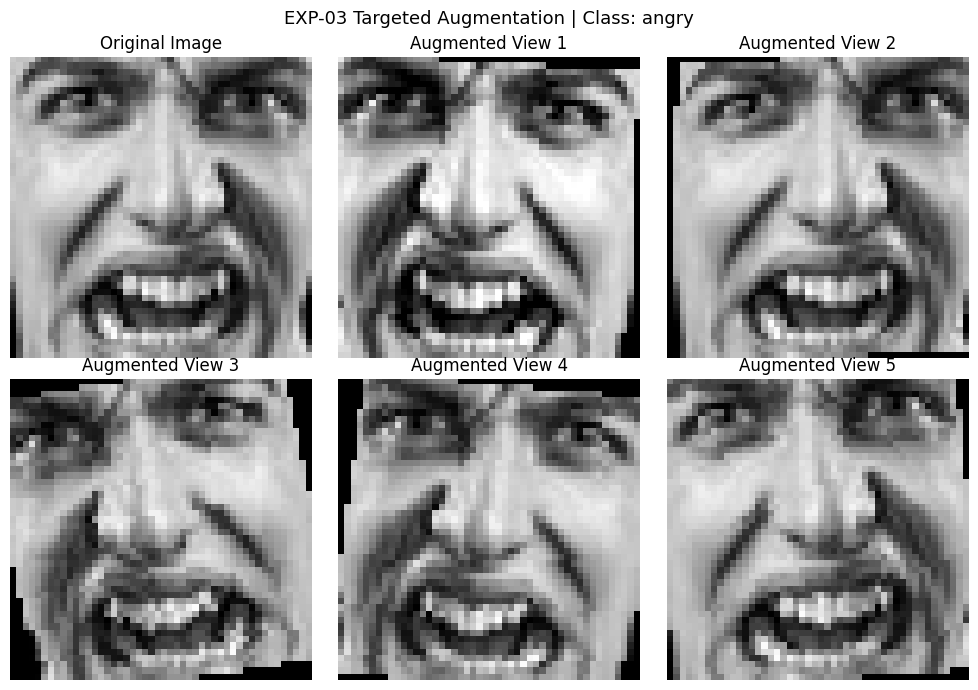

In [74]:
# ============================================================
# STEP 3.29.6: VISUALIZE EXP-03 AUGMENTATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Select one training image
sample_index = 100

image_path = exp03_train_dataset.paths[sample_index]
label = exp03_train_dataset.labels[sample_index]

# Load original image
original_image = Image.open(image_path).convert("L")
original_image = original_image.resize((48, 48))

# Generate multiple augmented versions
augmented_images = []

for i in range(5):
    image, _ = exp03_train_dataset[sample_index]

    # Reverse normalization: [-1, 1] -> [0, 1]
    image = image * 0.5 + 0.5

    augmented_images.append(
        image.squeeze().numpy()
    )

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

axes = axes.flatten()

axes[0].imshow(
    np.array(original_image),
    cmap="gray",
    vmin=0,
    vmax=255
)
axes[0].set_title("Original Image")

for i, image in enumerate(augmented_images):

    axes[i + 1].imshow(
        image,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i + 1].set_title(f"Augmented View {i+1}")

for ax in axes:
    ax.axis("off")

plt.suptitle(
    f"EXP-03 Targeted Augmentation | Class: {class_names[label]}",
    fontsize=13
)

plt.tight_layout()
plt.show()

In [75]:
# ============================================================
# STEP 3.29.7: EXP-03 WEIGHTED SAMPLER
# ============================================================

import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

# Class counts from frozen training split
class_counts = torch.bincount(
    torch.tensor(exp03_train_dataset.labels),
    minlength=7
).float()

# Inverse square-root class weights
class_weights = 1.0 / torch.sqrt(class_counts)

# Per-image sampling weights
sample_weights = torch.tensor(
    [class_weights[label].item()
     for label in exp03_train_dataset.labels],
    dtype=torch.double
)

# Reproducible sampler
exp03_sampler_generator = torch.Generator()
exp03_sampler_generator.manual_seed(43)

exp03_train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(exp03_train_dataset),
    replacement=True,
    generator=exp03_sampler_generator
)

# Rebuild training loader
exp03_train_loader = DataLoader(
    exp03_train_dataset,
    batch_size=128,
    sampler=exp03_train_sampler,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

print("EXP-03 Weighted Sampler Setup Completed")
print("Sampler:", type(exp03_train_loader.sampler).__name__)
print("Train Batches:", len(exp03_train_loader))
print("Class Counts:", class_counts.tolist())

EXP-03 Weighted Sampler Setup Completed
Sampler: WeightedRandomSampler
Train Batches: 183
Class Counts: [3082.0, 1380.0, 3116.0, 5744.0, 3931.0, 3835.0, 2324.0]


In [76]:
# ============================================================
# STEP 3.29.8: EXP-03 MODEL INITIALIZATION
# ============================================================

import os
import random
import numpy as np
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import GradScaler

# Reproducibility
SEED = 43

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fresh model
exp03_model = FER_SEResNetScratch(num_classes=7).to(device)

# Loss: Same as baseline
exp03_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

# Optimizer: Same as baseline
exp03_optimizer = AdamW(
    exp03_model.parameters(),
    lr=5e-4,
    weight_decay=2e-4
)

# Scheduler
exp03_scheduler = ReduceLROnPlateau(
    exp03_optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)

# AMP
exp03_scaler = GradScaler()

# Training configuration
EXP03_EPOCHS = 90
EXP03_PATIENCE = 14

# Output directories
exp03_base_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    "EXP03"
)

exp03_model_dir = os.path.join(exp03_base_dir, "Models")
exp03_results_dir = os.path.join(exp03_base_dir, "Results")

os.makedirs(exp03_model_dir, exist_ok=True)
os.makedirs(exp03_results_dir, exist_ok=True)

exp03_checkpoint_path = os.path.join(
    exp03_model_dir,
    "EXP03_TargetedAugmentation_Best.pth"
)

exp03_history_path = os.path.join(
    exp03_results_dir,
    "EXP03_training_history.csv"
)

print("EXP-03 Model Initialization Completed")
print("Device:", device)
print("Parameters:", sum(p.numel() for p in exp03_model.parameters()))
print("Loss:", exp03_criterion)
print("Optimizer:", exp03_optimizer)
print("Learning Rate:", exp03_optimizer.param_groups[0]["lr"])
print("Epochs:", EXP03_EPOCHS)
print("Early Stopping Patience:", EXP03_PATIENCE)
print("Checkpoint:", exp03_checkpoint_path)
print("CUDA Available:", torch.cuda.is_available())

EXP-03 Model Initialization Completed
Device: cuda
Parameters: 1994263
Loss: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0005
    maximize: False
    weight_decay: 0.0002
)
Learning Rate: 0.0005
Epochs: 90
Early Stopping Patience: 14
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Models\EXP03_TargetedAugmentation_Best.pth
CUDA Available: True


In [77]:
# ============================================================
# STEP 3.29.9: EXP-03 MODEL TRAINING
# ============================================================

import time
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score
from torch.cuda.amp import autocast

exp03_history = []

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(1, EXP03_EPOCHS + 1):

    # ---------------- TRAINING ----------------
    exp03_model.train()

    train_loss_total = 0.0
    train_predictions = []
    train_targets = []

    train_bar = tqdm(
        exp03_train_loader,
        desc=f"EXP-03 Epoch {epoch}/{EXP03_EPOCHS}"
    )

    for images, labels in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        exp03_optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = exp03_model(images)
            loss = exp03_criterion(outputs, labels)

        exp03_scaler.scale(loss).backward()
        exp03_scaler.step(exp03_optimizer)
        exp03_scaler.update()

        train_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(predictions.detach().cpu().numpy())
        train_targets.extend(labels.detach().cpu().numpy())

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_total / len(exp03_train_dataset)

    train_accuracy = accuracy_score(
        train_targets, train_predictions
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(7)),
        average="macro",
        zero_division=0
    )

    # ---------------- VALIDATION ----------------
    exp03_model.eval()

    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in exp03_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = exp03_model(images)
                loss = exp03_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_predictions.extend(
                predictions.cpu().numpy()
            )
            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss = val_loss_total / len(exp03_val_dataset)

    val_accuracy = accuracy_score(
        val_targets, val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=list(range(7)),
        average="macro",
        zero_division=0
    )

    # ---------------- SCHEDULER ----------------
    exp03_scheduler.step(val_macro_f1)

    current_lr = exp03_optimizer.param_groups[0]["lr"]

    # ---------------- SAVE HISTORY ----------------
    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    exp03_history.append(epoch_record)

    pd.DataFrame(exp03_history).to_csv(
        exp03_history_path,
        index=False
    )

    # ---------------- BEST CHECKPOINT ----------------
    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": exp03_model.state_dict(),
            "optimizer_state_dict": exp03_optimizer.state_dict(),
            "best_val_macro_f1": best_val_f1,
            "val_accuracy": val_accuracy,
            "class_names": class_names
        }, exp03_checkpoint_path)

        checkpoint_status = "BEST MODEL SAVED"

    else:
        epochs_without_improvement += 1
        checkpoint_status = (
            f"No improvement: {epochs_without_improvement}"
        )

    # ---------------- EPOCH SUMMARY ----------------
    print(f"\nEpoch: {epoch}/{EXP03_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Train Macro-F1: {train_macro_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro-F1: {val_macro_f1:.4f}")
    print(f"Learning Rate: {current_lr:.7f}")
    print(f"Best Epoch: {best_epoch}")
    print(checkpoint_status)

    # ---------------- EARLY STOPPING ----------------
    if epochs_without_improvement >= EXP03_PATIENCE:

        print("\nEarly stopping triggered.")
        break


# ============================================================
# TRAINING COMPLETED
# ============================================================

total_time = (time.time() - start_time) / 60

print("\n========== EXP-03 TRAINING COMPLETED ==========")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_val_f1:.4f}")
print(f"Total Training Time: {total_time:.2f} minutes")
print("Checkpoint:", exp03_checkpoint_path)
print("History:", exp03_history_path)

EXP-03 Epoch 1/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 1/90
Train Loss: 1.9286
Train Accuracy: 0.1881
Train Macro-F1: 0.1451
Validation Loss: 1.8717
Validation Accuracy: 0.2266
Validation Macro-F1: 0.1303
Learning Rate: 0.0005000
Best Epoch: 1
BEST MODEL SAVED


EXP-03 Epoch 2/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 2/90
Train Loss: 1.9063
Train Accuracy: 0.2037
Train Macro-F1: 0.1546
Validation Loss: 1.8619
Validation Accuracy: 0.2382
Validation Macro-F1: 0.1360
Learning Rate: 0.0005000
Best Epoch: 2
BEST MODEL SAVED


EXP-03 Epoch 3/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 3/90
Train Loss: 1.8779
Train Accuracy: 0.2241
Train Macro-F1: 0.1933
Validation Loss: 1.8317
Validation Accuracy: 0.2568
Validation Macro-F1: 0.2171
Learning Rate: 0.0005000
Best Epoch: 3
BEST MODEL SAVED


... (170 outputs left out)

EXP-03 Epoch 89/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 89/90
Train Loss: 0.8714
Train Accuracy: 0.7388
Train Macro-F1: 0.7464
Validation Loss: 1.0888
Validation Accuracy: 0.6507
Validation Macro-F1: 0.6484
Learning Rate: 0.0000078
Best Epoch: 80
No improvement: 9


EXP-03 Epoch 90/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 90/90
Train Loss: 0.8636
Train Accuracy: 0.7415
Train Macro-F1: 0.7481
Validation Loss: 1.0928
Validation Accuracy: 0.6490
Validation Macro-F1: 0.6464
Learning Rate: 0.0000039
Best Epoch: 80
No improvement: 10

========== EXP-03 TRAINING COMPLETED ==========
Best Epoch: 80
Best Validation Macro-F1: 0.6535
Total Training Time: 74.06 minutes
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Models\EXP03_TargetedAugmentation_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Results\EXP03_training_history.csv


In [78]:
# ============================================================
# STEP 3.29.10: EXPERIMENT COMPARISON
# ============================================================

import pandas as pd
import os

comparison_data = [
    {
        "Experiment": "Baseline SE-ResNet",
        "Validation_Macro_F1": 0.6306738796
    },
    {
        "Experiment": "EXP-01 Class Weight",
        "Validation_Macro_F1": 0.629985
    },
    {
        "Experiment": "EXP-02 Focal Loss",
        "Validation_Macro_F1": 0.618360
    },
    {
        "Experiment": "EXP-03 Targeted Augmentation",
        "Validation_Macro_F1": best_val_f1
    }
]

exp_comparison_df = pd.DataFrame(comparison_data)

exp_comparison_df["Validation_Macro_F1_Percent"] = (
    exp_comparison_df["Validation_Macro_F1"] * 100
)

exp_comparison_df = exp_comparison_df.sort_values(
    "Validation_Macro_F1",
    ascending=False
)

exp_comparison_path = os.path.join(
    exp03_results_dir,
    "experiment_comparison.csv"
)

exp_comparison_df.to_csv(
    exp_comparison_path,
    index=False
)

print("========== EXPERIMENT COMPARISON ==========")
display(exp_comparison_df)

print("\nBest Experiment:",
      exp_comparison_df.iloc[0]["Experiment"])

print("Saved:", exp_comparison_path)

========== EXPERIMENT COMPARISON ==========


,Experiment,Validation_Macro_F1,Validation_Macro_F1_Percent
3,EXP-03 Targeted Augmentation,0.653545,65.354514
0,Baseline SE-ResNet,0.630674,63.067388
1,EXP-01 Class Weight,0.629985,62.998500
2,EXP-02 Focal Loss,0.618360,61.836000



Best Experiment: EXP-03 Targeted Augmentation
Saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Results\experiment_comparison.csv


In [79]:
# ============================================================
# STEP 3.29.11: EXP-03 FINAL TEST EVALUATION
# ============================================================

import os
import torch
import pandas as pd
import numpy as np

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Create Test Dataset and Loader
# ------------------------------------------------------------

exp03_test_transform = exp03_val_transform

exp03_test_dataset = FERManifestDataset(
    exp03_test_df,
    transform=exp03_test_transform
)

exp03_test_loader = DataLoader(
    exp03_test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

print("Test Dataset Size:", len(exp03_test_dataset))
print("Test Batches:", len(exp03_test_loader))

# ------------------------------------------------------------
# 2. Load Best Checkpoint
# ------------------------------------------------------------

checkpoint = torch.load(
    exp03_checkpoint_path,
    map_location=device
)

exp03_model.load_state_dict(
    checkpoint["model_state_dict"]
)

exp03_model.to(device)
exp03_model.eval()

print("\nLoaded Best Checkpoint")
print("Best Epoch:", checkpoint["epoch"])
print("Best Validation Macro-F1:",
      checkpoint["best_val_macro_f1"])

# ------------------------------------------------------------
# 3. Generate Test Predictions
# ------------------------------------------------------------

test_predictions = []
test_targets = []
test_probabilities = []

with torch.no_grad():

    for images, labels in exp03_test_loader:

        images = images.to(device, non_blocking=True)

        with torch.cuda.amp.autocast():
            outputs = exp03_model(images)

        probabilities = torch.softmax(outputs, dim=1)
        predictions = outputs.argmax(dim=1)

        test_predictions.extend(
            predictions.cpu().numpy()
        )

        test_targets.extend(
            labels.numpy()
        )

        test_probabilities.extend(
            probabilities.cpu().numpy()
        )

test_predictions = np.array(test_predictions)
test_targets = np.array(test_targets)
test_probabilities = np.array(test_probabilities)

# ------------------------------------------------------------
# 4. Calculate Metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    test_targets, test_predictions
)

test_balanced_accuracy = balanced_accuracy_score(
    test_targets, test_predictions
)

test_macro_precision = precision_score(
    test_targets, test_predictions,
    average="macro", zero_division=0
)

test_macro_recall = recall_score(
    test_targets, test_predictions,
    average="macro", zero_division=0
)

test_macro_f1 = f1_score(
    test_targets, test_predictions,
    average="macro", zero_division=0
)

test_weighted_f1 = f1_score(
    test_targets, test_predictions,
    average="weighted", zero_division=0
)

# ------------------------------------------------------------
# 5. Classification Report
# ------------------------------------------------------------

report_dict = classification_report(
    test_targets,
    test_predictions,
    labels=list(range(7)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

# ------------------------------------------------------------
# 6. Confusion Matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=list(range(7))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

# ------------------------------------------------------------
# 7. Save Results
# ------------------------------------------------------------

metrics_df = pd.DataFrame([{
    "Experiment": "EXP-03 Targeted Augmentation",
    "Best_Epoch": checkpoint["epoch"],
    "Validation_Macro_F1": checkpoint["best_val_macro_f1"],
    "Test_Images": len(test_targets),
    "Test_Accuracy": test_accuracy,
    "Test_Balanced_Accuracy": test_balanced_accuracy,
    "Test_Macro_Precision": test_macro_precision,
    "Test_Macro_Recall": test_macro_recall,
    "Test_Macro_F1": test_macro_f1,
    "Test_Weighted_F1": test_weighted_f1
}])

metrics_path = os.path.join(
    exp03_results_dir,
    "EXP03_final_test_metrics.csv"
)

report_path = os.path.join(
    exp03_results_dir,
    "EXP03_classification_report.csv"
)

cm_path = os.path.join(
    exp03_results_dir,
    "EXP03_confusion_matrix.csv"
)

metrics_df.to_csv(metrics_path, index=False)
report_df.to_csv(report_path)
cm_df.to_csv(cm_path)

# ------------------------------------------------------------
# 8. Save Individual Predictions
# ------------------------------------------------------------

prediction_df = exp03_test_df.copy()

prediction_df["Actual_Label"] = test_targets
prediction_df["Predicted_Label"] = test_predictions
prediction_df["Actual_Class"] = [
    class_names[i] for i in test_targets
]
prediction_df["Predicted_Class"] = [
    class_names[i] for i in test_predictions
]
prediction_df["Confidence"] = test_probabilities.max(axis=1)

prediction_path = os.path.join(
    exp03_results_dir,
    "EXP03_test_predictions.csv"
)

prediction_df.to_csv(prediction_path, index=False)

# ------------------------------------------------------------
# 9. Final Summary
# ------------------------------------------------------------

print("\n========== EXP-03 FINAL TEST RESULTS ==========")

print(f"Test Images: {len(test_targets)}")
print(f"Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"Balanced Accuracy: {test_balanced_accuracy:.4f}")
print(f"Macro Precision: {test_macro_precision:.4f}")
print(f"Macro Recall: {test_macro_recall:.4f}")
print(f"Macro F1: {test_macro_f1:.4f}")
print(f"Weighted F1: {test_weighted_f1:.4f}")

print("\n========== CLASSIFICATION REPORT ==========")
display(report_df)

print("\n========== CONFUSION MATRIX ==========")
display(cm_df)

print("\nAll EXP-03 test results saved successfully.")
print("Metrics:", metrics_path)
print("Report:", report_path)
print("Confusion Matrix:", cm_path)
print("Predictions:", prediction_path)

Test Dataset Size: 7139
Test Batches: 56

Loaded Best Checkpoint
Best Epoch: 80
Best Validation Macro-F1: 0.6535451350509477

========== EXP-03 FINAL TEST RESULTS ==========
Test Images: 7139
Accuracy: 0.6495 (64.95%)
Balanced Accuracy: 0.6523
Macro Precision: 0.6469
Macro Recall: 0.6523
Macro F1: 0.6476
Weighted F1: 0.6459

========== CLASSIFICATION REPORT ==========


,precision,recall,f1-score,support
angry,0.570526,0.568134,0.569328,954.000000
disgust,0.838889,0.822888,0.830812,367.000000
fear,0.491677,0.392237,0.436364,979.000000
happy,0.859802,0.845054,0.852364,1749.000000
neutral,0.571529,0.673588,0.618376,1204.000000
sad,0.510166,0.472198,0.490449,1169.000000
surprise,0.685990,0.792190,0.735275,717.000000
accuracy,0.649531,0.649531,0.649531,0.649531
macro avg,0.646940,0.652327,0.647567,7139.000000
weighted avg,0.646262,0.649531,0.645900,7139.000000



========== CONFUSION MATRIX ==========


,angry,disgust,fear,happy,neutral,sad,surprise
angry,542,22,94,34,115,124,23
disgust,31,302,3,2,2,19,8
fear,134,10,384,42,116,176,117
happy,39,3,27,1478,96,36,70
neutral,52,4,54,92,811,170,21
sad,131,15,154,39,257,552,21
surprise,21,4,65,32,22,5,568



All EXP-03 test results saved successfully.
Metrics: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Results\EXP03_final_test_metrics.csv
Report: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Results\EXP03_classification_report.csv
Confusion Matrix: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Results\EXP03_confusion_matrix.csv
Predictions: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP03\Results\EXP03_test_predictions.csv


## ConvNeXt-Tiny Transfer Learning for Facial Emotion Recognition

In [80]:
# ============================================================
# EXP-07 | CELL 1: IMPORT LIBRARIES
# ============================================================

import os
import time
import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights
)

from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from torch.cuda.amp import autocast, GradScaler

print("Libraries Imported Successfully")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

Libraries Imported Successfully
PyTorch: 2.2.2+cu121
Torchvision: 0.17.2+cu121


In [81]:
# ============================================================
# EXP-07 | CELL 2: GPU VERIFICATION
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():

    print("GPU Name:", torch.cuda.get_device_name(0))

    gpu_memory = (
        torch.cuda.get_device_properties(0).total_memory
        / (1024 ** 3)
    )

    print(f"GPU Memory: {gpu_memory:.2f} GB")

    torch.cuda.empty_cache()

print("\nEXP-07 Environment Verification Completed")

Device: cuda
CUDA Available: True
GPU Name: NVIDIA GeForce RTX 4060 Laptop GPU
GPU Memory: 8.00 GB

EXP-07 Environment Verification Completed


In [82]:
# ============================================================
# EXP-07 | CELL 3: PRETRAINED CONVNEXT-TINY
# ============================================================

# Load ImageNet pretrained weights
convnext_weights = ConvNeXt_Tiny_Weights.DEFAULT

exp07_backbone = convnext_tiny(
    weights=convnext_weights
)

# Original classifier information
print("ConvNeXt-Tiny Loaded Successfully")

print("\nOriginal Classifier:")
print(exp07_backbone.classifier)

total_params = sum(
    p.numel() for p in exp07_backbone.parameters()
)

print("\nTotal Parameters:", total_params)

# Verify pretrained weights
print("\nPretrained Weights:", convnext_weights)

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\sahas/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth
100%|███████████████████████████████████████████████████████████████████████████████| 109M/109M [00:03<00:00, 36.9MB/s]


ConvNeXt-Tiny Loaded Successfully

Original Classifier:
Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=1000, bias=True)
)

Total Parameters: 28589128

Pretrained Weights: ConvNeXt_Tiny_Weights.IMAGENET1K_V1


In [83]:
# ============================================================
# EXP-07 | CELL 4: GRAYSCALE INPUT ADAPTATION
# ============================================================

exp07_train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.95, 1.05)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

exp07_eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("EXP-07 Transforms Created")
print("Input: Grayscale -> RGB (3 channels)")
print("Image Size: 224 x 224")

EXP-07 Transforms Created
Input: Grayscale -> RGB (3 channels)
Image Size: 224 x 224


In [84]:
# ============================================================
# EXP-07 | CELL 5: DATASET CREATION
# ============================================================

exp07_train_dataset = FERManifestDataset(
    exp03_train_df,
    transform=exp07_train_transform
)

exp07_val_dataset = FERManifestDataset(
    exp03_val_df,
    transform=exp07_eval_transform
)

print("Train Dataset:", len(exp07_train_dataset))
print("Validation Dataset:", len(exp07_val_dataset))
print("Test Dataset: Not loaded for training or tuning")

Train Dataset: 23412
Validation Dataset: 5433
Test Dataset: Not loaded for training or tuning


In [85]:
# ============================================================
# EXP-07 | CELL 6: OPTIMIZED DATALOADERS
# ============================================================

EXP07_BATCH_SIZE = 32

exp07_generator = torch.Generator()
exp07_generator.manual_seed(47)

exp07_train_loader = DataLoader(
    exp07_train_dataset,
    batch_size=EXP07_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True,
    drop_last=False,
    generator=exp07_generator
)

exp07_val_loader = DataLoader(
    exp07_val_dataset,
    batch_size=EXP07_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

print("Batch Size:", EXP07_BATCH_SIZE)
print("Train Batches:", len(exp07_train_loader))
print("Validation Batches:", len(exp07_val_loader))

# GPU memory check
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(
        "GPU Allocated Memory:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

# Batch verification
images, labels = next(iter(exp07_train_loader))

print("Image Shape:", images.shape)
print("Label Shape:", labels.shape)

Batch Size: 32
Train Batches: 732
Validation Batches: 170
GPU Allocated Memory: 0.16 GB
Image Shape: torch.Size([32, 3, 224, 224])
Label Shape: torch.Size([32])


In [86]:
# ============================================================
# EXP-07 | CELL 7: CUSTOM CLASSIFIER
# ============================================================

exp07_model = copy.deepcopy(exp07_backbone)

in_features = exp07_model.classifier[2].in_features

exp07_model.classifier[2] = nn.Sequential(
    nn.Dropout(p=0.35),
    nn.Linear(in_features, 512),
    nn.GELU(),
    nn.Dropout(p=0.25),
    nn.Linear(512, 7)
)

exp07_model = exp07_model.to(device)

print(exp07_model.classifier)
print("\nOutput Classes:", 7)

Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Sequential(
    (0): Dropout(p=0.35, inplace=False)
    (1): Linear(in_features=768, out_features=512, bias=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=512, out_features=7, bias=True)
  )
)

Output Classes: 7


In [87]:
# ============================================================
# EXP-07 | CELL 8: FREEZE BACKBONE
# ============================================================

for param in exp07_model.features.parameters():
    param.requires_grad = False

for param in exp07_model.avgpool.parameters():
    param.requires_grad = False

for param in exp07_model.classifier.parameters():
    param.requires_grad = True

total_params = sum(
    p.numel() for p in exp07_model.parameters()
)

trainable_params = sum(
    p.numel() for p in exp07_model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Frozen Parameters:", total_params - trainable_params)

Total Parameters: 28217447
Trainable Parameters: 398855
Frozen Parameters: 27818592


In [88]:
# ============================================================
# EXP-07 | CELL 9: TRAINING CONFIGURATION
# ============================================================

EXP07_EPOCHS = 25
EXP07_PATIENCE = 7

exp07_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

exp07_optimizer = optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        exp07_model.parameters()
    ),
    lr=1e-3,
    weight_decay=1e-4
)

exp07_scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    exp07_optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

exp07_scaler = GradScaler()

print("Training Configuration Ready")
print("Epochs:", EXP07_EPOCHS)
print("Early Stopping Patience:", EXP07_PATIENCE)
print("Learning Rate:", 1e-3)
print("Optimizer: AdamW")
print("Loss: CrossEntropy with Label Smoothing")

Training Configuration Ready
Epochs: 25
Early Stopping Patience: 7
Learning Rate: 0.001
Optimizer: AdamW
Loss: CrossEntropy with Label Smoothing


In [89]:
# ============================================================
# EXP-07 | CELL 10: OUTPUT DIRECTORIES
# ============================================================

exp07_base_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    "EXP07_ConvNeXt_Tiny"
)

exp07_model_dir = os.path.join(exp07_base_dir, "Models")
exp07_results_dir = os.path.join(exp07_base_dir, "Results")

os.makedirs(exp07_model_dir, exist_ok=True)
os.makedirs(exp07_results_dir, exist_ok=True)

exp07_checkpoint_path = os.path.join(
    exp07_model_dir,
    "EXP07_ConvNeXt_Tiny_Best.pth"
)

exp07_history_path = os.path.join(
    exp07_results_dir,
    "EXP07_training_history.csv"
)

print("EXP-07 Directories Created")
print("Model Directory:", exp07_model_dir)
print("Results Directory:", exp07_results_dir)

EXP-07 Directories Created
Model Directory: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP07_ConvNeXt_Tiny\Models
Results Directory: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP07_ConvNeXt_Tiny\Results


In [90]:
# ============================================================
# EXP-07 | CELL 11: TRAINING FUNCTIONS
# ============================================================

def exp07_train_one_epoch():

    exp07_model.train()

    # Keep frozen feature extractor in evaluation mode
    exp07_model.features.eval()
    exp07_model.avgpool.eval()

    total_loss = 0.0
    predictions = []
    targets = []

    for images, labels in exp07_train_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        exp07_optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = exp07_model(images)
            loss = exp07_criterion(outputs, labels)

        exp07_scaler.scale(loss).backward()
        exp07_scaler.step(exp07_optimizer)
        exp07_scaler.update()

        total_loss += loss.item() * images.size(0)

        predictions.extend(
            outputs.argmax(dim=1).detach().cpu().numpy()
        )
        targets.extend(labels.detach().cpu().numpy())

    avg_loss = total_loss / len(exp07_train_dataset)

    accuracy = accuracy_score(targets, predictions)

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


def exp07_validate():

    exp07_model.eval()

    total_loss = 0.0
    predictions = []
    targets = []

    with torch.no_grad():

        for images, labels in exp07_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = exp07_model(images)
                loss = exp07_criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions.extend(
                outputs.argmax(dim=1).cpu().numpy()
            )
            targets.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(exp07_val_dataset)

    accuracy = accuracy_score(targets, predictions)

    macro_f1 = f1_score(
        targets,
        predictions,
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


print("Training and Validation Functions Defined")

Training and Validation Functions Defined


In [91]:
# ============================================================
# EXP-07 | CELL 12: CLASSIFIER TRAINING
# ============================================================

from tqdm.auto import tqdm

exp07_history = []

exp07_best_f1 = -1.0
exp07_best_epoch = 0
exp07_no_improvement = 0

for epoch in range(1, EXP07_EPOCHS + 1):

    start = time.time()

    train_loss, train_acc, train_f1 = (
        exp07_train_one_epoch()
    )

    val_loss, val_acc, val_f1 = (
        exp07_validate()
    )

    exp07_scheduler.step(val_f1)

    current_lr = exp07_optimizer.param_groups[0]["lr"]

    if val_f1 > exp07_best_f1:

        exp07_best_f1 = val_f1
        exp07_best_epoch = epoch
        exp07_no_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": exp07_model.state_dict(),
            "best_val_macro_f1": exp07_best_f1,
            "val_accuracy": val_acc,
            "phase": "classifier_training"
        }, exp07_checkpoint_path)

        status = "BEST CHECKPOINT SAVED"

    else:

        exp07_no_improvement += 1
        status = f"No improvement: {exp07_no_improvement}"

    record = {
        "epoch": epoch,
        "phase": "classifier_training",
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr
    }

    exp07_history.append(record)

    pd.DataFrame(exp07_history).to_csv(
        exp07_history_path,
        index=False
    )

    print(f"\nEpoch {epoch}/{EXP07_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Train Macro-F1: {train_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_acc:.4f}")
    print(f"Validation Macro-F1: {val_f1:.4f}")
    print(f"Learning Rate: {current_lr:.7f}")
    print(f"Time: {(time.time()-start)/60:.2f} min")
    print(status)

    if exp07_no_improvement >= EXP07_PATIENCE:

        print("\nEarly Stopping Triggered")
        break


print("\n========== CLASSIFIER TRAINING COMPLETED ==========")
print("Best Epoch:", exp07_best_epoch)
print("Best Validation Macro-F1:", exp07_best_f1)
print("Checkpoint:", exp07_checkpoint_path)


Epoch 1/25
Train Loss: 1.5004
Train Accuracy: 0.4505
Train Macro-F1: 0.4345
Validation Loss: 1.3532
Validation Accuracy: 0.5284
Validation Macro-F1: 0.5271
Learning Rate: 0.0010000
Time: 4.68 min
BEST CHECKPOINT SAVED

Epoch 2/25
Train Loss: 1.3884
Train Accuracy: 0.5074
Train Macro-F1: 0.4959
Validation Loss: 1.3308
Validation Accuracy: 0.5413
Validation Macro-F1: 0.5355
Learning Rate: 0.0010000
Time: 1.75 min
BEST CHECKPOINT SAVED

Epoch 3/25
Train Loss: 1.3425
Train Accuracy: 0.5239
Train Macro-F1: 0.5146
Validation Loss: 1.3066
Validation Accuracy: 0.5492
Validation Macro-F1: 0.5433
Learning Rate: 0.0010000
Time: 1.73 min
BEST CHECKPOINT SAVED

Epoch 4/25
Train Loss: 1.3068
Train Accuracy: 0.5435
Train Macro-F1: 0.5383
Validation Loss: 1.3026
Validation Accuracy: 0.5478
Validation Macro-F1: 0.5473
Learning Rate: 0.0010000
Time: 1.73 min
BEST CHECKPOINT SAVED

Epoch 5/25
Train Loss: 1.2726
Train Accuracy: 0.5608
Train Macro-F1: 0.5581
Validation Loss: 1.2847
Validation Accuracy: 0.

In [92]:
# ============================================================
# STEP 3.30.1: EXP-04 INITIALIZATION
# Label Smoothing Comparison
# ============================================================

import os
import torch
import torch.nn as nn
import random
import numpy as np
import pandas as pd

from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import GradScaler

# Reproducibility
SEED = 44

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Fresh model
exp04_model = FER_SEResNetScratch(
    num_classes=7
).to(device)

# Loss: No label smoothing
exp04_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.0
)

# Optimizer
exp04_optimizer = AdamW(
    exp04_model.parameters(),
    lr=5e-4,
    weight_decay=2e-4
)

# Scheduler
exp04_scheduler = ReduceLROnPlateau(
    exp04_optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)

# AMP
exp04_scaler = GradScaler()

# Training configuration
EXP04_EPOCHS = 90
EXP04_PATIENCE = 14

# Directories
exp04_base_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    "EXP04"
)

exp04_model_dir = os.path.join(
    exp04_base_dir, "Models"
)

exp04_results_dir = os.path.join(
    exp04_base_dir, "Results"
)

os.makedirs(exp04_model_dir, exist_ok=True)
os.makedirs(exp04_results_dir, exist_ok=True)

# Checkpoint and history paths
exp04_checkpoint_path = os.path.join(
    exp04_model_dir,
    "EXP04_NoLabelSmoothing_Best.pth"
)

exp04_history_path = os.path.join(
    exp04_results_dir,
    "EXP04_training_history.csv"
)

# Verify datasets and sampler
assert len(exp03_train_dataset) == 23412
assert len(exp03_val_dataset) == 5433
assert isinstance(
    exp03_train_loader.sampler,
    WeightedRandomSampler
)

print("========== EXP-04 INITIALIZATION ==========")
print("Device:", device)
print("Parameters:", sum(
    p.numel() for p in exp04_model.parameters()
))
print("Label Smoothing: 0.0")
print("Learning Rate:", exp04_optimizer.param_groups[0]["lr"])
print("Weight Decay: 0.0002")
print("Train Dataset:", len(exp03_train_dataset))
print("Validation Dataset:", len(exp03_val_dataset))
print("Sampler:", type(exp03_train_loader.sampler).__name__)
print("Epochs:", EXP04_EPOCHS)
print("Early Stopping Patience:", EXP04_PATIENCE)
print("Checkpoint:", exp04_checkpoint_path)
print("History:", exp04_history_path)

========== EXP-04 INITIALIZATION ==========
Device: cuda
Parameters: 1994263
Label Smoothing: 0.0
Learning Rate: 0.0005
Weight Decay: 0.0002
Train Dataset: 23412
Validation Dataset: 5433
Sampler: WeightedRandomSampler
Epochs: 90
Early Stopping Patience: 14
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP04\Models\EXP04_NoLabelSmoothing_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP04\Results\EXP04_training_history.csv


In [93]:
# ============================================================
# STEP 3.30.2: EXP-04 MODEL TRAINING
# ============================================================

import time
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score
from torch.cuda.amp import autocast

exp04_history = []

best_val_f1 = -1.0
best_epoch = 0
epochs_without_improvement = 0

start_time = time.time()

for epoch in range(1, EXP04_EPOCHS + 1):

    # ---------------- TRAINING ----------------
    exp04_model.train()

    train_loss_total = 0.0
    train_predictions = []
    train_targets = []

    train_bar = tqdm(
        exp03_train_loader,
        desc=f"EXP-04 Epoch {epoch}/{EXP04_EPOCHS}"
    )

    for images, labels in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        exp04_optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = exp04_model(images)
            loss = exp04_criterion(outputs, labels)

        exp04_scaler.scale(loss).backward()
        exp04_scaler.step(exp04_optimizer)
        exp04_scaler.update()

        train_loss_total += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        train_predictions.extend(
            predictions.detach().cpu().numpy()
        )
        train_targets.extend(
            labels.detach().cpu().numpy()
        )

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = train_loss_total / len(exp03_train_dataset)

    train_accuracy = accuracy_score(
        train_targets, train_predictions
    )

    train_macro_f1 = f1_score(
        train_targets,
        train_predictions,
        labels=list(range(7)),
        average="macro",
        zero_division=0
    )

    # ---------------- VALIDATION ----------------
    exp04_model.eval()

    val_loss_total = 0.0
    val_predictions = []
    val_targets = []

    with torch.no_grad():

        for images, labels in exp03_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = exp04_model(images)
                loss = exp04_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            val_predictions.extend(
                predictions.cpu().numpy()
            )
            val_targets.extend(
                labels.cpu().numpy()
            )

    val_loss = val_loss_total / len(exp03_val_dataset)

    val_accuracy = accuracy_score(
        val_targets, val_predictions
    )

    val_macro_f1 = f1_score(
        val_targets,
        val_predictions,
        labels=list(range(7)),
        average="macro",
        zero_division=0
    )

    # ---------------- SCHEDULER ----------------
    exp04_scheduler.step(val_macro_f1)

    current_lr = exp04_optimizer.param_groups[0]["lr"]

    # ---------------- SAVE HISTORY ----------------
    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "train_macro_f1": train_macro_f1,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_macro_f1,
        "learning_rate": current_lr
    }

    exp04_history.append(epoch_record)

    pd.DataFrame(exp04_history).to_csv(
        exp04_history_path,
        index=False
    )

    # ---------------- BEST CHECKPOINT ----------------
    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": exp04_model.state_dict(),
            "optimizer_state_dict": exp04_optimizer.state_dict(),
            "best_val_macro_f1": best_val_f1,
            "val_accuracy": val_accuracy,
            "class_names": class_names
        }, exp04_checkpoint_path)

        checkpoint_status = "BEST MODEL SAVED"

    else:
        epochs_without_improvement += 1
        checkpoint_status = (
            f"No improvement: {epochs_without_improvement}"
        )

    # ---------------- EPOCH SUMMARY ----------------
    print(f"\nEpoch: {epoch}/{EXP04_EPOCHS}")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")
    print(f"Train Macro-F1: {train_macro_f1:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro-F1: {val_macro_f1:.4f}")
    print(f"Learning Rate: {current_lr:.7f}")
    print(f"Best Epoch: {best_epoch}")
    print(checkpoint_status)

    # ---------------- EARLY STOPPING ----------------
    if epochs_without_improvement >= EXP04_PATIENCE:

        print("\nEarly stopping triggered.")
        break

# ============================================================
# TRAINING COMPLETED
# ============================================================

total_time = (time.time() - start_time) / 60

print("\n========== EXP-04 TRAINING COMPLETED ==========")
print("Best Epoch:", best_epoch)
print(f"Best Validation Macro-F1: {best_val_f1:.4f}")
print(f"Total Training Time: {total_time:.2f} minutes")
print("Checkpoint:", exp04_checkpoint_path)
print("History:", exp04_history_path)

EXP-04 Epoch 1/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 1/90
Train Loss: 1.9302
Train Accuracy: 0.1878
Train Macro-F1: 0.1455
Validation Loss: 1.8606
Validation Accuracy: 0.2385
Validation Macro-F1: 0.1299
Learning Rate: 0.0005000
Best Epoch: 1
BEST MODEL SAVED


EXP-04 Epoch 2/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 2/90
Train Loss: 1.9001
Train Accuracy: 0.2055
Train Macro-F1: 0.1550
Validation Loss: 1.8422
Validation Accuracy: 0.2470
Validation Macro-F1: 0.1625
Learning Rate: 0.0005000
Best Epoch: 2
BEST MODEL SAVED


EXP-04 Epoch 3/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 3/90
Train Loss: 1.8736
Train Accuracy: 0.2210
Train Macro-F1: 0.1890
Validation Loss: 1.8046
Validation Accuracy: 0.2722
Validation Macro-F1: 0.2362
Learning Rate: 0.0005000
Best Epoch: 3
BEST MODEL SAVED


... (158 outputs left out)

EXP-04 Epoch 83/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 83/90
Train Loss: 0.6329
Train Accuracy: 0.7678
Train Macro-F1: 0.7752
Validation Loss: 1.0188
Validation Accuracy: 0.6610
Validation Macro-F1: 0.6602
Learning Rate: 0.0000156
Best Epoch: 70
No improvement: 13


EXP-04 Epoch 84/90:   0%|          | 0/183 [00:00<?, ?it/s]


Epoch: 84/90
Train Loss: 0.6254
Train Accuracy: 0.7676
Train Macro-F1: 0.7741
Validation Loss: 1.0250
Validation Accuracy: 0.6611
Validation Macro-F1: 0.6607
Learning Rate: 0.0000156
Best Epoch: 70
No improvement: 14

Early stopping triggered.

========== EXP-04 TRAINING COMPLETED ==========
Best Epoch: 70
Best Validation Macro-F1: 0.6617
Total Training Time: 73.11 minutes
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP04\Models\EXP04_NoLabelSmoothing_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP04\Results\EXP04_training_history.csv


In [94]:

# ============================================================
# EXP-05: BATCH SIZE 64
# Targeted Augmentation + Weighted Sampler
# Label Smoothing = 0.05
# ============================================================

import os, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
from sklearn.metrics import accuracy_score, f1_score

# ---------------- CONFIGURATION ----------------
EXP_NAME = "EXP05_Batch64"
BATCH_SIZE = 64
SEED = 45
EPOCHS = 90
PATIENCE = 14

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- DATASETS ----------------
train_dataset = exp03_train_dataset
val_dataset = exp03_val_dataset

class_counts = torch.bincount(
    torch.tensor(train_dataset.labels),
    minlength=7
).float()

class_weights = 1.0 / torch.sqrt(class_counts)

sample_weights = torch.tensor(
    [class_weights[label].item() for label in train_dataset.labels],
    dtype=torch.double
)

sampler_generator = torch.Generator()
sampler_generator.manual_seed(SEED)

train_sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(train_dataset),
    replacement=True,
    generator=sampler_generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ---------------- MODEL ----------------
model = FER_SEResNetScratch(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = AdamW(
    model.parameters(),
    lr=5e-4,
    weight_decay=2e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)

scaler = GradScaler()

# ---------------- OUTPUT PATHS ----------------
base_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    EXP_NAME
)

model_dir = os.path.join(base_dir, "Models")
results_dir = os.path.join(base_dir, "Results")

os.makedirs(model_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

checkpoint_path = os.path.join(
    model_dir, "EXP05_Batch64_Best.pth"
)

history_path = os.path.join(
    results_dir, "EXP05_Batch64_History.csv"
)

# ---------------- TRAINING ----------------
history = []
best_f1 = -1.0
best_epoch = 0
no_improvement = 0
start_time = time.time()

print("Starting EXP-05 | Batch Size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device:", device)

for epoch in range(1, EPOCHS + 1):

    model.train()
    total_loss = 0.0
    train_preds, train_targets = [], []

    for images, labels in tqdm(
        train_loader,
        desc=f"EXP-05 Epoch {epoch}/{EPOCHS}"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        train_preds.extend(outputs.argmax(1).detach().cpu().numpy())
        train_targets.extend(labels.cpu().numpy())

    train_loss = total_loss / len(train_dataset)
    train_acc = accuracy_score(train_targets, train_preds)
    train_f1 = f1_score(
        train_targets, train_preds,
        labels=list(range(7)), average="macro", zero_division=0
    )

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss_total = 0.0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_dataset)
    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(
        val_targets, val_preds,
        labels=list(range(7)), average="macro", zero_division=0
    )

    scheduler.step(val_f1)
    lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": lr
    })

    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch
        no_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_f1,
            "val_accuracy": val_acc,
            "class_names": class_names,
            "batch_size": BATCH_SIZE
        }, checkpoint_path)

        status = "BEST CHECKPOINT SAVED"
    else:
        no_improvement += 1
        status = f"No improvement: {no_improvement}"

    print(
        f"\nEXP-05 Epoch {epoch} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {lr:.7f} | {status}"
    )

    if no_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\n========== EXP-05 COMPLETED ==========")
print("Best Epoch:", best_epoch)
print("Best Validation Macro-F1:", best_f1)
print("Training Time:", round((time.time()-start_time)/60, 2), "minutes")
print("Checkpoint:", checkpoint_path)
print("History:", history_path)


Starting EXP-05 | Batch Size: 64
Train batches: 366
Validation batches: 85
Device: cuda


EXP-05 Epoch 1/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP-05 Epoch 1 | Train F1: 0.1486 | Val F1: 0.1176 | Val Acc: 0.2444 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP-05 Epoch 2/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP-05 Epoch 2 | Train F1: 0.1771 | Val F1: 0.2016 | Val Acc: 0.2483 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP-05 Epoch 3/90:   0%|          | 0/366 [00:00<?, ?it/s]

... (163 outputs left out)

EXP-05 Epoch 85/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP-05 Epoch 85 | Train F1: 0.8342 | Val F1: 0.6606 | Val Acc: 0.6600 | LR: 0.0000625 | No improvement: 13


EXP-05 Epoch 86/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP-05 Epoch 86 | Train F1: 0.8333 | Val F1: 0.6600 | Val Acc: 0.6604 | LR: 0.0000625 | No improvement: 14
Early stopping triggered.

========== EXP-05 COMPLETED ==========
Best Epoch: 72
Best Validation Macro-F1: 0.6620067366148051
Training Time: 78.21 minutes
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Models\EXP05_Batch64_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Results\EXP05_Batch64_History.csv


In [95]:

# ============================================================
# EXP-06: BATCH SIZE 128
# Targeted Augmentation + Weighted Sampler
# Label Smoothing = 0.05
# ============================================================

import os, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
from sklearn.metrics import accuracy_score, f1_score

# ---------------- CONFIGURATION ----------------
EXP_NAME = "EXP06_Batch128"
BATCH_SIZE = 128
SEED = 46
EPOCHS = 90
PATIENCE = 14

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- DATASETS ----------------
train_dataset = exp03_train_dataset
val_dataset = exp03_val_dataset

class_counts = torch.bincount(
    torch.tensor(train_dataset.labels),
    minlength=7
).float()

class_weights = 1.0 / torch.sqrt(class_counts)

sample_weights = torch.tensor(
    [class_weights[label].item() for label in train_dataset.labels],
    dtype=torch.double
)

sampler_generator = torch.Generator()
sampler_generator.manual_seed(SEED)

train_sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(train_dataset),
    replacement=True,
    generator=sampler_generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ---------------- MODEL ----------------
model = FER_SEResNetScratch(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = AdamW(
    model.parameters(),
    lr=5e-4,
    weight_decay=2e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)

scaler = GradScaler()

# ---------------- OUTPUT PATHS ----------------
base_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    EXP_NAME
)

model_dir = os.path.join(base_dir, "Models")
results_dir = os.path.join(base_dir, "Results")

os.makedirs(model_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

checkpoint_path = os.path.join(
    model_dir, "EXP06_Batch128_Best.pth"
)

history_path = os.path.join(
    results_dir, "EXP06_Batch128_History.csv"
)

# ---------------- TRAINING ----------------
history = []
best_f1 = -1.0
best_epoch = 0
no_improvement = 0
start_time = time.time()

print("Starting EXP-06 | Batch Size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device:", device)

for epoch in range(1, EPOCHS + 1):

    model.train()
    total_loss = 0.0
    train_preds, train_targets = [], []

    for images, labels in tqdm(
        train_loader,
        desc=f"EXP-06 Epoch {epoch}/{EPOCHS}"
    ):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

        train_preds.extend(outputs.argmax(1).detach().cpu().numpy())
        train_targets.extend(labels.cpu().numpy())

    train_loss = total_loss / len(train_dataset)
    train_acc = accuracy_score(train_targets, train_preds)
    train_f1 = f1_score(
        train_targets, train_preds,
        labels=list(range(7)), average="macro", zero_division=0
    )

    # ---------------- VALIDATION ----------------
    model.eval()
    val_loss_total = 0.0
    val_preds, val_targets = [], []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(val_dataset)
    val_acc = accuracy_score(val_targets, val_preds)
    val_f1 = f1_score(
        val_targets, val_preds,
        labels=list(range(7)), average="macro", zero_division=0
    )

    scheduler.step(val_f1)
    lr = optimizer.param_groups[0]["lr"]

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": lr
    })

    pd.DataFrame(history).to_csv(history_path, index=False)

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch
        no_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_macro_f1": best_f1,
            "val_accuracy": val_acc,
            "class_names": class_names,
            "batch_size": BATCH_SIZE
        }, checkpoint_path)

        status = "BEST CHECKPOINT SAVED"
    else:
        no_improvement += 1
        status = f"No improvement: {no_improvement}"

    print(
        f"\nEXP-06 Epoch {epoch} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {lr:.7f} | {status}"
    )

    if no_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\n========== EXP-06 COMPLETED ==========")
print("Best Epoch:", best_epoch)
print("Best Validation Macro-F1:", best_f1)
print("Training Time:", round((time.time()-start_time)/60, 2), "minutes")
print("Checkpoint:", checkpoint_path)
print("History:", history_path)


Starting EXP-06 | Batch Size: 128
Train batches: 183
Validation batches: 43
Device: cuda


EXP-06 Epoch 1/90:   0%|          | 0/183 [00:00<?, ?it/s]


EXP-06 Epoch 1 | Train F1: 0.1521 | Val F1: 0.1372 | Val Acc: 0.2408 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP-06 Epoch 2/90:   0%|          | 0/183 [00:00<?, ?it/s]


EXP-06 Epoch 2 | Train F1: 0.1570 | Val F1: 0.1524 | Val Acc: 0.2332 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP-06 Epoch 3/90:   0%|          | 0/183 [00:00<?, ?it/s]

... (135 outputs left out)

EXP-06 Epoch 71/90:   0%|          | 0/183 [00:00<?, ?it/s]


EXP-06 Epoch 71 | Train F1: 0.7660 | Val F1: 0.6427 | Val Acc: 0.6457 | LR: 0.0000625 | No improvement: 13


EXP-06 Epoch 72/90:   0%|          | 0/183 [00:00<?, ?it/s]


EXP-06 Epoch 72 | Train F1: 0.7633 | Val F1: 0.6444 | Val Acc: 0.6446 | LR: 0.0000625 | No improvement: 14
Early stopping triggered.

========== EXP-06 COMPLETED ==========
Best Epoch: 58
Best Validation Macro-F1: 0.6518622599137333
Training Time: 56.57 minutes
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP06_Batch128\Models\EXP06_Batch128_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP06_Batch128\Results\EXP06_Batch128_History.csv


In [96]:

# ============================================================
# EXP-08: BATCH SIZE 256
# Targeted Augmentation + Weighted Sampler
# Label Smoothing = 0.05
# ============================================================

import os, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from tqdm.auto import tqdm
from torch.utils.data import DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import autocast, GradScaler
from sklearn.metrics import accuracy_score, f1_score

# ---------------- CONFIGURATION ----------------
EXP_NAME = "EXP08_Batch256"
BATCH_SIZE = 256
SEED = 47
EPOCHS = 90
PATIENCE = 14

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- DATASETS ----------------
train_dataset = exp03_train_dataset
val_dataset = exp03_val_dataset

class_counts = torch.bincount(
    torch.tensor(train_dataset.labels),
    minlength=7
).float()

class_weights = 1.0 / torch.sqrt(class_counts)

sample_weights = torch.tensor(
    [class_weights[label].item() for label in train_dataset.labels],
    dtype=torch.double
)

sampler_generator = torch.Generator()
sampler_generator.manual_seed(SEED)

train_sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(train_dataset),
    replacement=True,
    generator=sampler_generator
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=train_sampler,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ---------------- MODEL ----------------
model = FER_SEResNetScratch(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

optimizer = AdamW(
    model.parameters(),
    lr=5e-4,
    weight_decay=2e-4
)

scheduler = ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)

scaler = GradScaler()

# ---------------- OUTPUT PATHS ----------------
base_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    EXP_NAME
)

model_dir = os.path.join(base_dir, "Models")
results_dir = os.path.join(base_dir, "Results")

os.makedirs(model_dir, exist_ok=True)
os.makedirs(results_dir, exist_ok=True)

checkpoint_path = os.path.join(
    model_dir, "EXP08_Batch256_Best.pth"
)

history_path = os.path.join(
    results_dir, "EXP08_Batch256_History.csv"
)

# ---------------- TRAINING ----------------
history = []
best_f1 = -1.0
best_epoch = 0
no_improvement = 0
start_time = time.time()

print("Starting EXP-08 | Batch Size:", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Device:", device)

try:

    for epoch in range(1, EPOCHS + 1):

        model.train()
        total_loss = 0.0
        train_preds, train_targets = [], []

        for images, labels in tqdm(
            train_loader,
            desc=f"EXP-08 Epoch {epoch}/{EPOCHS}"
        ):
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * images.size(0)

            train_preds.extend(outputs.argmax(1).detach().cpu().numpy())
            train_targets.extend(labels.cpu().numpy())

        train_loss = total_loss / len(train_dataset)
        train_acc = accuracy_score(train_targets, train_preds)
        train_f1 = f1_score(
            train_targets, train_preds,
            labels=list(range(7)), average="macro", zero_division=0
        )

        # ---------------- VALIDATION ----------------
        model.eval()
        val_loss_total = 0.0
        val_preds, val_targets = [], []

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                with autocast():
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss_total += loss.item() * images.size(0)
                val_preds.extend(outputs.argmax(1).cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        val_loss = val_loss_total / len(val_dataset)
        val_acc = accuracy_score(val_targets, val_preds)
        val_f1 = f1_score(
            val_targets, val_preds,
            labels=list(range(7)), average="macro", zero_division=0
        )

        scheduler.step(val_f1)
        lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "train_macro_f1": train_f1,
            "val_loss": val_loss,
            "val_accuracy": val_acc,
            "val_macro_f1": val_f1,
            "learning_rate": lr
        })

        pd.DataFrame(history).to_csv(history_path, index=False)

        if val_f1 > best_f1:
            best_f1 = val_f1
            best_epoch = epoch
            no_improvement = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "best_val_macro_f1": best_f1,
                "val_accuracy": val_acc,
                "class_names": class_names,
                "batch_size": BATCH_SIZE
            }, checkpoint_path)

            status = "BEST CHECKPOINT SAVED"
        else:
            no_improvement += 1
            status = f"No improvement: {no_improvement}"

        print(
            f"\nEXP-08 Epoch {epoch} | "
            f"Train F1: {train_f1:.4f} | "
            f"Val F1: {val_f1:.4f} | "
            f"Val Acc: {val_acc:.4f} | "
            f"LR: {lr:.7f} | {status}"
        )

        if no_improvement >= PATIENCE:
            print("Early stopping triggered.")
            break

    print("\n========== EXP-08 COMPLETED ==========")
    print("Best Epoch:", best_epoch)
    print("Best Validation Macro-F1:", best_f1)
    print("Training Time:", round((time.time()-start_time)/60, 2), "minutes")
    print("Checkpoint:", checkpoint_path)
    print("History:", history_path)

except torch.cuda.OutOfMemoryError:
    print("\nEXP-08 STOPPED: CUDA OUT OF MEMORY")
    print("Batch Size 256 could not fit in available GPU memory.")
    print("Clear GPU memory and consider a smaller batch size.")
    optimizer.zero_grad(set_to_none=True)
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

except Exception as e:
    print("\nEXP-08 FAILED:", repr(e))
    raise


Starting EXP-08 | Batch Size: 256
Train batches: 92
Validation batches: 22
Device: cuda


EXP-08 Epoch 1/90:   0%|          | 0/92 [00:00<?, ?it/s]


EXP-08 Epoch 1 | Train F1: 0.1427 | Val F1: 0.1531 | Val Acc: 0.2238 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP-08 Epoch 2/90:   0%|          | 0/92 [00:00<?, ?it/s]


EXP-08 Epoch 2 | Train F1: 0.1592 | Val F1: 0.1762 | Val Acc: 0.2408 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP-08 Epoch 3/90:   0%|          | 0/92 [00:00<?, ?it/s]

... (153 outputs left out)

EXP-08 Epoch 80/90:   0%|          | 0/92 [00:00<?, ?it/s]


EXP-08 Epoch 80 | Train F1: 0.7688 | Val F1: 0.6432 | Val Acc: 0.6459 | LR: 0.0000625 | No improvement: 13


EXP-08 Epoch 81/90:   0%|          | 0/92 [00:00<?, ?it/s]


EXP-08 Epoch 81 | Train F1: 0.7732 | Val F1: 0.6448 | Val Acc: 0.6472 | LR: 0.0000625 | No improvement: 14
Early stopping triggered.

========== EXP-08 COMPLETED ==========
Best Epoch: 67
Best Validation Macro-F1: 0.6482449945672686
Training Time: 50.99 minutes
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP08_Batch256\Models\EXP08_Batch256_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP08_Batch256\Results\EXP08_Batch256_History.csv


In [8]:
# ============================================================
# STEP 3.30.3: COMPLETE EXPERIMENT COMPARISON
# ============================================================

import os
import pandas as pd

comparison_data = [
    ["Baseline SE-ResNet", 128, 0.6306738796],
    ["EXP-01 Class Weight", 128, 0.629985],
    ["EXP-02 Focal Loss", 128, 0.618360],
    ["EXP-03 Targeted Augmentation", 128, 0.6535451351],
    ["EXP-04 No Label Smoothing", 128, 0.6617],
    ["EXP-05 Batch 64", 64, 0.6620067366],
    ["EXP-06 Batch 128", 128, 0.6518622599],
    ["EXP-07 ConvNeXt Tiny", None, 0.5850389232],
    ["EXP-08 Batch 256", 256, 0.6482449946]
]

comparison_df = pd.DataFrame(
    comparison_data,
    columns=[
        "Experiment",
        "Batch_Size",
        "Validation_Macro_F1"
    ]
)

comparison_df["Validation_Macro_F1_Percent"] = (
    comparison_df["Validation_Macro_F1"] * 100
)

comparison_df = comparison_df.sort_values(
    "Validation_Macro_F1",
    ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0, "Rank", range(1, len(comparison_df) + 1)
)

comparison_dir = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement"
)

comparison_path = os.path.join(
    comparison_dir,
    "Complete_Experiment_Comparison.csv"
)

comparison_df.to_csv(comparison_path, index=False)

print("========== COMPLETE MODEL COMPARISON ==========")
display(comparison_df)

print("\nBest Experiment:")
print(comparison_df.iloc[0]["Experiment"])

print("\nBest Validation Macro-F1:")
print(
    comparison_df.iloc[0]["Validation_Macro_F1_Percent"],
    "%"
)

print("\nSaved:", comparison_path)

========== COMPLETE MODEL COMPARISON ==========


,Rank,Experiment,Batch_Size,Validation_Macro_F1,Validation_Macro_F1_Percent
0,1,EXP-05 Batch 64,64.0,0.662007,66.200674
1,2,EXP-04 No Label Smoothing,128.0,0.661700,66.170000
2,3,EXP-03 Targeted Augmentation,128.0,0.653545,65.354514
3,4,EXP-06 Batch 128,128.0,0.651862,65.186226
4,5,EXP-08 Batch 256,256.0,0.648245,64.824499
5,6,Baseline SE-ResNet,128.0,0.630674,63.067388
6,7,EXP-01 Class Weight,128.0,0.629985,62.998500
7,8,EXP-02 Focal Loss,128.0,0.618360,61.836000
8,9,EXP-07 ConvNeXt Tiny,NaN,0.585039,58.503892



Best Experiment:
EXP-05 Batch 64

Best Validation Macro-F1:
66.20067365999999 %

Saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\Complete_Experiment_Comparison.csv


In [9]:
# ============================================================
# FINAL COMPARISON: TEST ALL SAVED MODEL CHECKPOINTS
# No training - Evaluation only
# ============================================================

import os
import gc
import torch
import numpy as np
import pandas as pd
import torch.nn as nn

from tqdm.auto import tqdm
from torchvision.models import convnext_tiny
from torchvision import transforms
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. CHECKPOINT PATHS
# ------------------------------------------------------------

IMPROVEMENT_DIR = (
    PROJECT_ROOT / "FER_Scratch_Experiment" /
    "Model_Improvement"
)

model_checkpoints = {
    "Baseline SE-ResNet": MODEL_DIR / "FER_SEResNet_Scratch_Best.pth",

    "EXP-01 Class Weight":
        IMPROVEMENT_DIR / "EXP01" / "Models" /
        "EXP01_ClassWeight_Best.pth",

    "EXP-02 Focal Loss":
        IMPROVEMENT_DIR / "EXP02" / "Models" /
        "EXP02_FocalLoss_Best.pth",

    "EXP-03 Targeted Augmentation":
        IMPROVEMENT_DIR / "EXP03" / "Models" /
        "EXP03_TargetedAugmentation_Best.pth",

    "EXP-04 No Label Smoothing":
        IMPROVEMENT_DIR / "EXP04" / "Models" /
        "EXP04_NoLabelSmoothing_Best.pth",

    "EXP-05 Batch 64":
        IMPROVEMENT_DIR / "EXP05_Batch64" / "Models" /
        "EXP05_Batch64_Best.pth",

    "EXP-06 Batch 128":
        IMPROVEMENT_DIR / "EXP06_Batch128" / "Models" /
        "EXP06_Batch128_Best.pth",

    "EXP-07 ConvNeXt Tiny":
        IMPROVEMENT_DIR / "EXP07_ConvNeXt_Tiny" / "Models" /
        "EXP07_ConvNeXt_Tiny_Best.pth",

    "EXP-08 Batch 256":
        IMPROVEMENT_DIR / "EXP08_Batch256" / "Models" /
        "EXP08_Batch256_Best.pth"
}

print("========== CHECKPOINT VERIFICATION ==========")

available_models = {}
missing_models = []

for name, path in model_checkpoints.items():

    if path.is_file():
        available_models[name] = path
        print("[FOUND]", name)
    else:
        missing_models.append(name)
        print("[MISSING]", name, "->", path)

print("\nAvailable:", len(available_models))
print("Missing:", len(missing_models))

if not available_models:
    raise FileNotFoundError("No model checkpoints found.")

# ------------------------------------------------------------
# 2. TEST DATASET FOR CONVNEXT
# ------------------------------------------------------------

convnext_test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

convnext_test_dataset = FERManifestDataset(
    test_df,
    transform=convnext_test_transform
)

convnext_test_loader = DataLoader(
    convnext_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# 3. MODEL EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate_saved_model(model, loader):

    model.eval()

    predictions = []
    targets = []

    with torch.inference_mode():

        for images, labels in tqdm(loader, leave=False):

            images = images.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)

            preds = outputs.argmax(dim=1)

            predictions.extend(preds.cpu().numpy())
            targets.extend(labels.numpy())

    predictions = np.asarray(predictions)
    targets = np.asarray(targets)

    return targets, predictions


# ------------------------------------------------------------
# 4. EVALUATE ALL CHECKPOINTS
# ------------------------------------------------------------

all_results = []
all_class_reports = {}

for model_name, checkpoint_path in available_models.items():

    print("\n" + "=" * 65)
    print("EVALUATING:", model_name)
    print("=" * 65)

    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    # Select correct architecture and input loader
    if model_name == "EXP-07 ConvNeXt Tiny":

        model = convnext_tiny(weights=None)

        in_features = model.classifier[2].in_features

        model.classifier[2] = nn.Sequential(
            nn.Dropout(p=0.35),
            nn.Linear(in_features, 512),
            nn.GELU(),
            nn.Dropout(p=0.25),
            nn.Linear(512, 7)
        )

        model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True
        )

        model = model.to(device)

        y_true, y_pred = evaluate_saved_model(
            model,
            convnext_test_loader
        )

        del model

    else:

        model = FER_SEResNetScratch(
            num_classes=7
        )

        model.load_state_dict(
            checkpoint["model_state_dict"],
            strict=True
        )

        model = model.to(device)

        y_true, y_pred = evaluate_saved_model(
            model,
            test_loader
        )

        del model

    # Metrics
    accuracy = accuracy_score(y_true, y_pred)

    balanced_acc = balanced_accuracy_score(
        y_true, y_pred
    )

    macro_precision = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    all_results.append({
        "Experiment": model_name,
        "Best_Epoch": checkpoint.get("epoch", None),
        "Validation_Macro_F1":
            checkpoint.get("best_val_macro_f1", None),
        "Test_Accuracy": accuracy,
        "Test_Balanced_Accuracy": balanced_acc,
        "Test_Macro_Precision": macro_precision,
        "Test_Macro_Recall": macro_recall,
        "Test_Macro_F1": macro_f1,
        "Test_Weighted_F1": weighted_f1
    })

    # Class-wise report
    report = classification_report(
        y_true,
        y_pred,
        labels=list(range(7)),
        target_names=DISPLAY_NAMES,
        output_dict=True,
        zero_division=0
    )

    all_class_reports[model_name] = pd.DataFrame(report).transpose()

    print("Test Accuracy:", round(accuracy * 100, 2), "%")
    print("Test Macro-F1:", round(macro_f1 * 100, 2), "%")
    print("Test Balanced Accuracy:", round(balanced_acc * 100, 2), "%")

    del checkpoint
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ------------------------------------------------------------
# 5. FINAL COMPARISON TABLE
# ------------------------------------------------------------

final_comparison = pd.DataFrame(all_results)

final_comparison = final_comparison.sort_values(
    "Test_Macro_F1",
    ascending=False
).reset_index(drop=True)

final_comparison.insert(
    0,
    "Test_Rank",
    range(1, len(final_comparison) + 1)
)

print("\n" + "=" * 75)
print("FINAL TEST PERFORMANCE COMPARISON")
print("=" * 75)

display(
    final_comparison.style.format({
        "Validation_Macro_F1": "{:.4f}",
        "Test_Accuracy": "{:.4f}",
        "Test_Balanced_Accuracy": "{:.4f}",
        "Test_Macro_Precision": "{:.4f}",
        "Test_Macro_Recall": "{:.4f}",
        "Test_Macro_F1": "{:.4f}",
        "Test_Weighted_F1": "{:.4f}"
    })
)

# ------------------------------------------------------------
# 6. SAVE ALL RESULTS
# ------------------------------------------------------------

comparison_output = (
    IMPROVEMENT_DIR / "All_Models_Final_Test_Comparison.csv"
)

final_comparison.to_csv(
    comparison_output,
    index=False
)

for model_name, report_df in all_class_reports.items():

    safe_name = (
        model_name.replace(" ", "_")
        .replace("-", "")
    )

    report_df.to_csv(
        IMPROVEMENT_DIR /
        f"{safe_name}_Test_Classification_Report.csv"
    )

# ------------------------------------------------------------
# 7. WINNER
# ------------------------------------------------------------

winner = final_comparison.iloc[0]

print("\n========== BEST TEST MODEL ==========")
print("Model:", winner["Experiment"])
print("Test Accuracy:", round(winner["Test_Accuracy"] * 100, 2), "%")
print("Test Macro-F1:", round(winner["Test_Macro_F1"] * 100, 2), "%")
print("Test Balanced Accuracy:",
      round(winner["Test_Balanced_Accuracy"] * 100, 2), "%")

print("\nSaved Comparison:", comparison_output)
print("Missing Checkpoints:", missing_models)
print("\nALL AVAILABLE MODELS EVALUATED.")


========== CHECKPOINT VERIFICATION ==========
[FOUND] Baseline SE-ResNet
[FOUND] EXP-01 Class Weight
[FOUND] EXP-02 Focal Loss
[FOUND] EXP-03 Targeted Augmentation
[FOUND] EXP-04 No Label Smoothing
[FOUND] EXP-05 Batch 64
[FOUND] EXP-06 Batch 128
[FOUND] EXP-07 ConvNeXt Tiny
[FOUND] EXP-08 Batch 256

Available: 9
Missing: 0

EVALUATING: Baseline SE-ResNet


  0%|          | 0/56 [00:00<?, ?it/s]

Test Accuracy: 63.41 %
Test Macro-F1: 62.55 %
Test Balanced Accuracy: 61.27 %

EVALUATING: EXP-01 Class Weight


  0%|          | 0/56 [00:00<?, ?it/s]

Test Accuracy: 63.37 %
Test Macro-F1: 62.42 %
Test Balanced Accuracy: 61.2 %

EVALUATING: EXP-02 Focal Loss


  0%|          | 0/56 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/56 [00:00<?, ?it/s]

Test Accuracy: 65.01 %
Test Macro-F1: 64.74 %
Test Balanced Accuracy: 64.99 %

FINAL TEST PERFORMANCE COMPARISON


,Test_Rank,Experiment,Best_Epoch,Validation_Macro_F1,Test_Accuracy,Test_Balanced_Accuracy,Test_Macro_Precision,Test_Macro_Recall,Test_Macro_F1,Test_Weighted_F1
0,1,EXP-05 Batch 64,72,0.6620,0.6596,0.6570,0.6582,0.6570,0.6565,0.6560
1,2,EXP-03 Targeted Augmentation,80,0.6535,0.6495,0.6523,0.6469,0.6523,0.6476,0.6459
2,3,EXP-04 No Label Smoothing,70,0.6617,0.6518,0.6537,0.6452,0.6537,0.6475,0.6476
3,4,EXP-08 Batch 256,67,0.6482,0.6501,0.6499,0.6488,0.6499,0.6474,0.6480
4,5,EXP-06 Batch 128,58,0.6519,0.6487,0.6472,0.6437,0.6472,0.6429,0.6428
5,6,Baseline SE-ResNet,70,0.6307,0.6341,0.6127,0.6502,0.6127,0.6255,0.6334
6,7,EXP-01 Class Weight,53,0.6300,0.6337,0.6120,0.6513,0.6120,0.6242,0.6330
7,8,EXP-02 Focal Loss,53,0.6184,0.6232,0.5934,0.6396,0.5934,0.6062,0.6183
8,9,EXP-07 ConvNeXt Tiny,19,0.5850,0.5723,0.5650,0.5869,0.5650,0.5734,0.5681



========== BEST TEST MODEL ==========
Model: EXP-05 Batch 64
Test Accuracy: 65.96 %
Test Macro-F1: 65.65 %
Test Balanced Accuracy: 65.7 %

Saved Comparison: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\All_Models_Final_Test_Comparison.csv
Missing Checkpoints: []

ALL AVAILABLE MODELS EVALUATED.


EXP05 Batch64 checkpoint loaded successfully.
Test images evaluated: 7139


,precision,recall,f1-score,support
angry,0.5862,0.5629,0.5743,954.00
disgust,0.8535,0.8256,0.8393,367.00
fear,0.4761,0.4270,0.4502,979.00
happy,0.8500,0.8782,0.8639,1749.00
neutral,0.5938,0.6885,0.6377,1204.00
sad,0.5316,0.4748,0.5016,1169.00
surprise,0.7187,0.7448,0.7315,717.00
accuracy,0.6600,0.6600,0.6600,0.66
macro avg,0.6586,0.6574,0.6569,7139.00
weighted avg,0.6551,0.6600,0.6564,7139.00


,angry,disgust,fear,happy,neutral,sad,surprise
angry,537,27,102,36,111,120,21
disgust,19,303,19,1,3,15,7
fear,129,8,418,42,106,183,93
happy,31,2,26,1536,82,26,46
neutral,60,5,54,104,829,132,20
sad,119,9,165,53,246,555,22
surprise,21,1,94,35,19,13,534


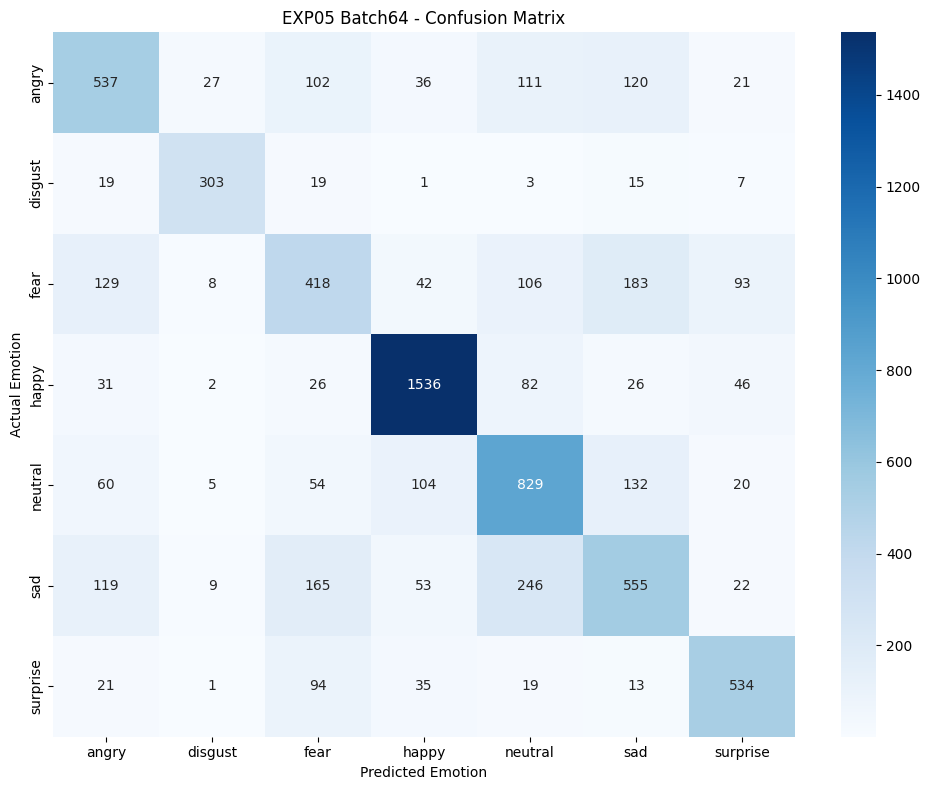


All results saved in:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Results


In [10]:
# ============================================================
# EXP05 BATCH64 - CLASSIFICATION REPORT & CONFUSION MATRIX
# ============================================================

import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix

# 1. Load EXP05 checkpoint
EXP05_CHECKPOINT = Path(
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP05_Batch64\Models\EXP05_Batch64_Best.pth"
)

EXP05_RESULTS = EXP05_CHECKPOINT.parents[1] / "Results"
EXP05_RESULTS.mkdir(parents=True, exist_ok=True)

checkpoint = torch.load(
    EXP05_CHECKPOINT,
    map_location=device,
    weights_only=False
)

# 2. Create model and load trained weights
exp05_model = FER_SEResNetScratch(
    num_classes=len(CLASS_NAMES)
).to(device)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

exp05_model.load_state_dict(state_dict)
exp05_model.eval()

print("EXP05 Batch64 checkpoint loaded successfully.")

# 3. Generate predictions on the existing test loader
test_targets = []
test_predictions = []

with torch.inference_mode():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)

        outputs = exp05_model(images)
        predictions = outputs.argmax(dim=1)

        test_targets.extend(labels.numpy().tolist())
        test_predictions.extend(predictions.cpu().numpy().tolist())

print("Test images evaluated:", len(test_targets))

# 4. Classification Report
report = classification_report(
    test_targets,
    test_predictions,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

report_df.to_csv(
    EXP05_RESULTS / "EXP05_Classification_Report.csv"
)

# 5. Confusion Matrix
cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=list(range(len(CLASS_NAMES)))
)

cm_df = pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

display(cm_df)

cm_df.to_csv(
    EXP05_RESULTS / "EXP05_Confusion_Matrix.csv"
)

# 6. Plot Confusion Matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("EXP05 Batch64 - Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

plt.savefig(
    EXP05_RESULTS / "EXP05_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nAll results saved in:")
print(EXP05_RESULTS)

In [11]:
from pathlib import Path
import pandas as pd

EXP05_DIR = Path(
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP05_Batch64"
)

print("Searching EXP05 training history files...\n")

history_files = list(EXP05_DIR.rglob("*.csv"))

for file in history_files:
    try:
        df = pd.read_csv(file)
        cols = [c.lower() for c in df.columns]

        if any("train_loss" in c for c in cols):
            print("Possible Training History:", file)
            print("Columns:", df.columns.tolist())
            print(df.head(3))
            print("-" * 60)

    except Exception:
        pass

Searching EXP05 training history files...

Possible Training History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Results\EXP05_Batch64_History.csv
Columns: ['epoch', 'train_loss', 'train_accuracy', 'train_macro_f1', 'val_loss', 'val_accuracy', 'val_macro_f1', 'learning_rate']
   epoch  train_loss  train_accuracy  train_macro_f1  val_loss  val_accuracy  \
0      1    1.925820        0.191355        0.148583  1.870899      0.244432   
1      2    1.892345        0.214292        0.177134  1.831797      0.248297   
2      3    1.844760        0.248719        0.218530  1.780583      0.279036   

   val_macro_f1  learning_rate  
0      0.117576         0.0005  
1      0.201571         0.0005  
2      0.248999         0.0005  
------------------------------------------------------------


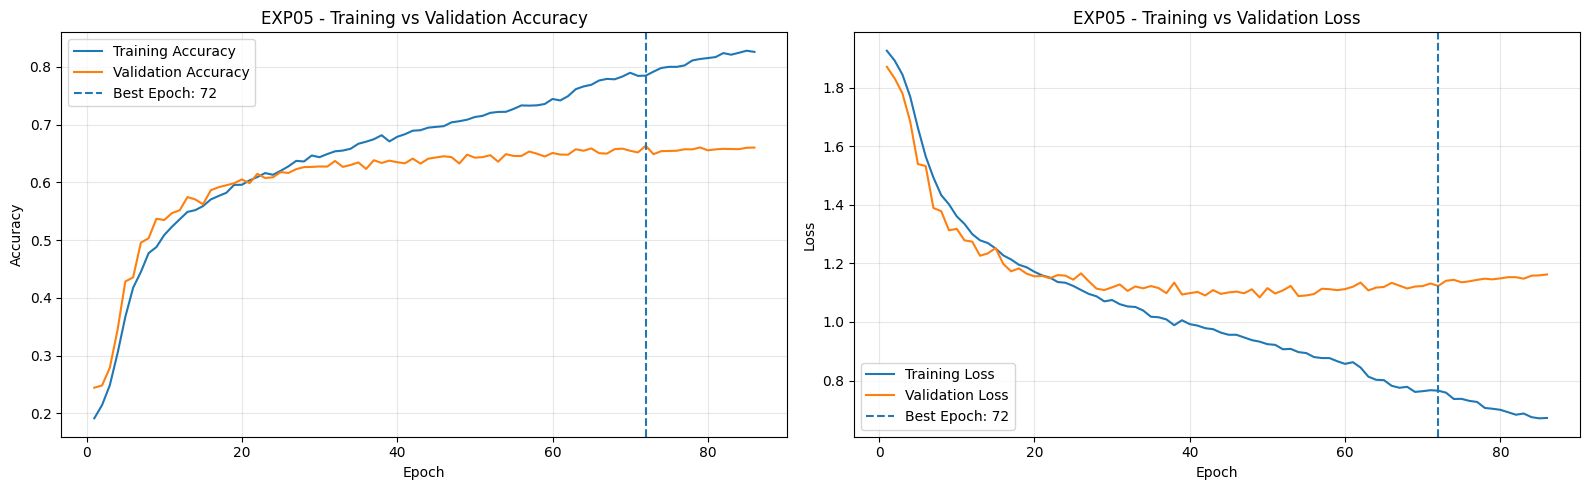

Best Epoch: 72
Best Validation Macro F1: 66.2 %

Graph saved at:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Results\EXP05_Training_Validation_Graphs.png


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load training history
HISTORY_PATH = Path(
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP05_Batch64\Results\EXP05_Batch64_History.csv"
)

RESULTS_DIR = HISTORY_PATH.parent

history = pd.read_csv(HISTORY_PATH)

# Best epoch based on validation Macro F1
best_epoch = history["val_macro_f1"].idxmax()
best_epoch_number = int(history.loc[best_epoch, "epoch"])

# Create two graphs
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Accuracy graph
axes[0].plot(history["epoch"], history["train_accuracy"],
             label="Training Accuracy")
axes[0].plot(history["epoch"], history["val_accuracy"],
             label="Validation Accuracy")

axes[0].axvline(best_epoch_number, linestyle="--",
                label=f"Best Epoch: {best_epoch_number}")

axes[0].set_title("EXP05 - Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss graph
axes[1].plot(history["epoch"], history["train_loss"],
             label="Training Loss")
axes[1].plot(history["epoch"], history["val_loss"],
             label="Validation Loss")

axes[1].axvline(best_epoch_number, linestyle="--",
                label=f"Best Epoch: {best_epoch_number}")

axes[1].set_title("EXP05 - Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

# Save graph
graph_path = RESULTS_DIR / "EXP05_Training_Validation_Graphs.png"
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("Best Epoch:", best_epoch_number)
print("Best Validation Macro F1:",
      round(history.loc[best_epoch, "val_macro_f1"] * 100, 2), "%")

print("\nGraph saved at:")
print(graph_path)

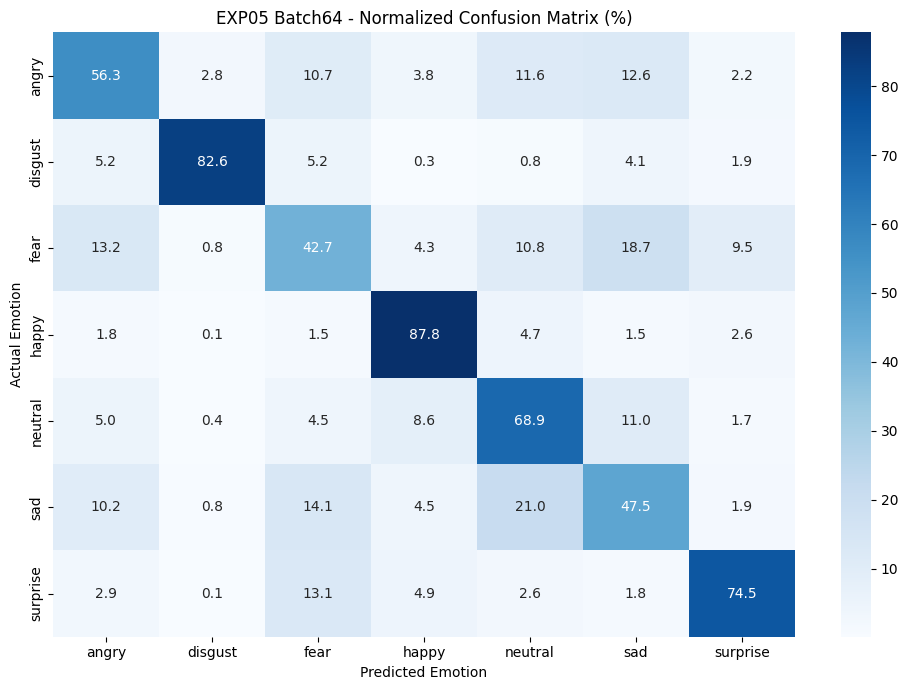


TOP 15 MISCLASSIFICATION PAIRS


,Actual Emotion,Predicted Emotion,Misclassified Images
34,sad,neutral,246
16,fear,sad,183
32,sad,fear,165
28,neutral,sad,132
12,fear,angry,129
4,angry,sad,120
30,sad,angry,119
3,angry,neutral,111
15,fear,neutral,106
27,neutral,happy,104



Analysis files saved successfully.


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report
from pathlib import Path

# Use existing test predictions
cm = confusion_matrix(
    test_targets,
    test_predictions,
    labels=range(len(CLASS_NAMES))
)

# Normalize row-wise (percentage)
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

# Create normalized confusion matrix
normalized_df = pd.DataFrame(
    cm_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    normalized_df,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.title("EXP05 Batch64 - Normalized Confusion Matrix (%)")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

plt.savefig(
    EXP05_RESULTS / "EXP05_Normalized_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Find top misclassification pairs
error_rows = []

for i in range(len(CLASS_NAMES)):
    for j in range(len(CLASS_NAMES)):
        if i != j:
            error_rows.append({
                "Actual Emotion": CLASS_NAMES[i],
                "Predicted Emotion": CLASS_NAMES[j],
                "Misclassified Images": int(cm[i, j])
            })

errors_df = pd.DataFrame(error_rows)
errors_df = errors_df.sort_values(
    "Misclassified Images", ascending=False
)

print("\nTOP 15 MISCLASSIFICATION PAIRS")
display(errors_df.head(15))

errors_df.to_csv(
    EXP05_RESULTS / "EXP05_Top_Misclassifications.csv",
    index=False
)

normalized_df.to_csv(
    EXP05_RESULTS / "EXP05_Normalized_Confusion_Matrix.csv"
)

print("\nAnalysis files saved successfully.")

Validation Loader: val_loader
EXP05 checkpoint loaded successfully.
Validation images evaluated: 5433

VALIDATION CLASSIFICATION REPORT

              precision    recall  f1-score   support

       angry     0.5516    0.5492    0.5504       701
     disgust     0.8738    0.8133    0.8424       332
        fear     0.4948    0.4555    0.4744       731
       happy     0.8425    0.8658    0.8540      1304
     neutral     0.5863    0.6754    0.6277       915
         sad     0.5728    0.5187    0.5444       910
    surprise     0.7439    0.7370    0.7405       540

    accuracy                         0.6635      5433
   macro avg     0.6665    0.6593    0.6620      5433
weighted avg     0.6620    0.6635    0.6618      5433

Validation Accuracy: 66.35 %


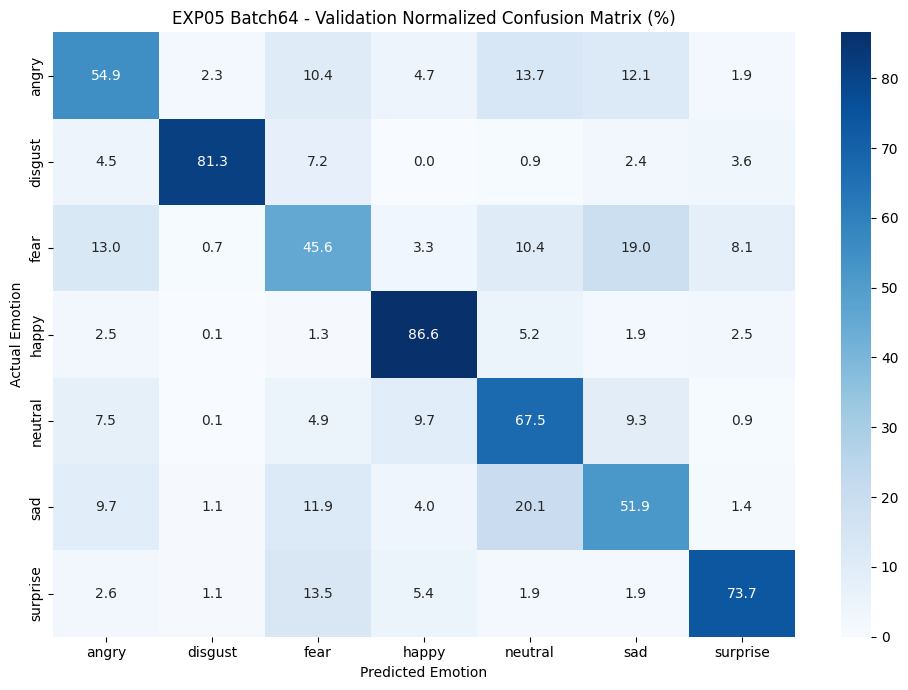


Validation analysis saved successfully.


In [14]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# --------------------------------------------------
# 1. Find Validation DataLoader
# --------------------------------------------------

possible_loaders = [
    "val_loader",
    "validation_loader",
    "valid_loader"
]

VAL_LOADER = None
VAL_LOADER_NAME = None

for name in possible_loaders:
    if name in globals():
        VAL_LOADER = globals()[name]
        VAL_LOADER_NAME = name
        break

if VAL_LOADER is None:
    raise NameError(
        "Validation DataLoader not found. "
        "Check whether it is named val_loader or validation_loader."
    )

print("Validation Loader:", VAL_LOADER_NAME)

# --------------------------------------------------
# 2. Load EXP05 Best Checkpoint
# --------------------------------------------------

EXP05_CHECKPOINT = Path(
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP05_Batch64\Models\EXP05_Batch64_Best.pth"
)

checkpoint = torch.load(
    EXP05_CHECKPOINT,
    map_location=device,
    weights_only=False
)

exp05_model = FER_SEResNetScratch(
    num_classes=len(CLASS_NAMES)
).to(device)

state_dict = checkpoint.get(
    "model_state_dict",
    checkpoint.get("state_dict", checkpoint)
)

exp05_model.load_state_dict(state_dict)
exp05_model.eval()

print("EXP05 checkpoint loaded successfully.")

# --------------------------------------------------
# 3. Validation Predictions
# --------------------------------------------------

val_targets = []
val_predictions = []

with torch.inference_mode():
    for images, labels in VAL_LOADER:

        images = images.to(device, non_blocking=True)

        outputs = exp05_model(images)
        predictions = outputs.argmax(dim=1)

        val_targets.extend(labels.cpu().numpy().tolist())
        val_predictions.extend(predictions.cpu().numpy().tolist())

print("Validation images evaluated:", len(val_targets))

# --------------------------------------------------
# 4. Classification Report
# --------------------------------------------------

print("\nVALIDATION CLASSIFICATION REPORT\n")

print(classification_report(
    val_targets,
    val_predictions,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    digits=4
))

print(
    "Validation Accuracy:",
    round(accuracy_score(val_targets, val_predictions) * 100, 2),
    "%"
)

# --------------------------------------------------
# 5. Confusion Matrix
# --------------------------------------------------

cm_val = confusion_matrix(
    val_targets,
    val_predictions,
    labels=range(len(CLASS_NAMES))
)

cm_val_normalized = (
    cm_val.astype(float) /
    cm_val.sum(axis=1, keepdims=True) * 100
)

val_cm_df = pd.DataFrame(
    cm_val_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    val_cm_df,
    annot=True,
    fmt=".1f",
    cmap="Blues"
)

plt.title("EXP05 Batch64 - Validation Normalized Confusion Matrix (%)")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.tight_layout()

RESULTS_DIR = EXP05_CHECKPOINT.parents[1] / "Results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(
    RESULTS_DIR / "EXP05_Validation_Normalized_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# --------------------------------------------------
# 6. Save Results
# --------------------------------------------------

val_cm_df.to_csv(
    RESULTS_DIR / "EXP05_Validation_Normalized_Confusion_Matrix.csv"
)

val_report = classification_report(
    val_targets,
    val_predictions,
    labels=range(len(CLASS_NAMES)),
    target_names=CLASS_NAMES,
    output_dict=True
)

pd.DataFrame(val_report).transpose().to_csv(
    RESULTS_DIR / "EXP05_Validation_Classification_Report.csv"
)

print("\nValidation analysis saved successfully.")

angry -> neutral: 96 misclassified images
fear -> sad: 139 misclassified images
sad -> neutral: 183 misclassified images


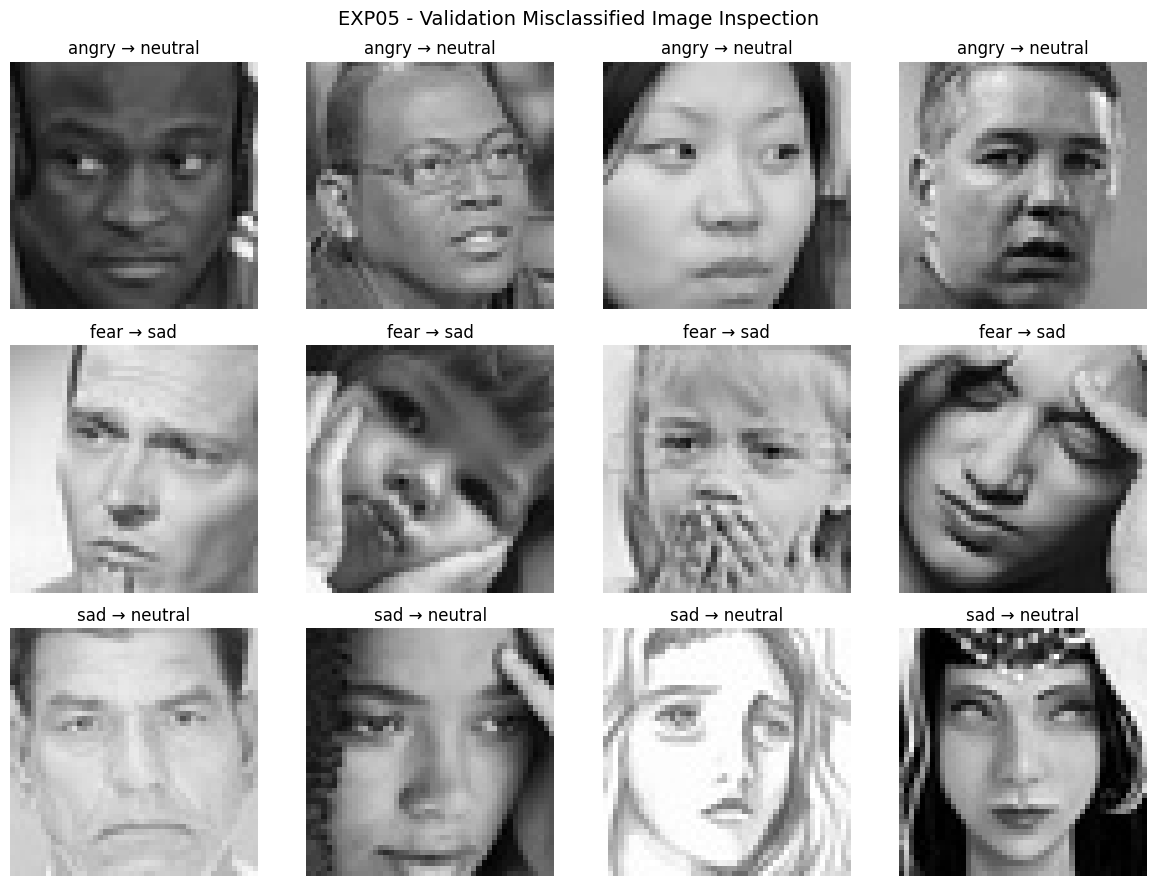


Images saved at: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Results\EXP05_Validation_Misclassified_Images.png


In [15]:
import torch
import matplotlib.pyplot as plt
from collections import defaultdict
from pathlib import Path

# EXP05 model and validation loader already loaded
exp05_model.eval()

target_pairs = [
    ("angry", "neutral"),
    ("fear", "sad"),
    ("sad", "neutral")
]

# Store misclassified images
misclassified = defaultdict(list)
pair_counts = defaultdict(int)

with torch.inference_mode():
    for images, labels in val_loader:

        images_device = images.to(device, non_blocking=True)
        outputs = exp05_model(images_device)
        predictions = outputs.argmax(dim=1).cpu()

        for i in range(len(labels)):
            actual = CLASS_NAMES[int(labels[i])]
            predicted = CLASS_NAMES[int(predictions[i])]

            pair = (actual, predicted)

            if pair in target_pairs:
                pair_counts[pair] += 1

                # Store maximum 4 images per pair
                if len(misclassified[pair]) < 4:
                    img = images[i].cpu()

                    # Undo normalization: mean=0.5, std=0.5
                    img = (img * 0.5 + 0.5).clamp(0, 1)

                    misclassified[pair].append(img.squeeze().numpy())

# Display images
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for row, pair in enumerate(target_pairs):

    actual, predicted = pair

    print(
        f"{actual} -> {predicted}: "
        f"{pair_counts[pair]} misclassified images"
    )

    for col in range(4):
        ax = axes[row, col]

        if col < len(misclassified[pair]):
            ax.imshow(
                misclassified[pair][col],
                cmap="gray",
                vmin=0,
                vmax=1
            )
            ax.set_title(f"{actual} → {predicted}")
        else:
            ax.axis("off")

        ax.axis("off")

plt.suptitle(
    "EXP05 - Validation Misclassified Image Inspection",
    fontsize=14
)

plt.tight_layout()

save_path = RESULTS_DIR / "EXP05_Validation_Misclassified_Images.png"

plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nImages saved at:", save_path)

In [16]:
# Inspect existing training DataLoader and Dataset

print("TRAINING DATASET INSPECTION")
print("=" * 60)

for name in ["train_loader", "train_dataset", "train_ds"]:
    if name in globals():
        obj = globals()[name]

        print(f"\nVariable: {name}")
        print("Type:", type(obj))

        if hasattr(obj, "dataset"):
            print("Underlying Dataset:", type(obj.dataset))
            print("Dataset Size:", len(obj.dataset))

            if hasattr(obj.dataset, "transform"):
                print("Dataset Transform:")
                print(obj.dataset.transform)

            if hasattr(obj.dataset, "classes"):
                print("Classes:", obj.dataset.classes)

        elif hasattr(obj, "transform"):
            print("Transform:")
            print(obj.transform)

        if hasattr(obj, "sampler"):
            print("Sampler:", type(obj.sampler))

        if hasattr(obj, "batch_size"):
            print("Batch Size:", obj.batch_size)

print("\nCLASS NAMES:", CLASS_NAMES)

TRAINING DATASET INSPECTION

Variable: train_loader
Type: <class 'torch.utils.data.dataloader.DataLoader'>
Underlying Dataset: <class '__main__.FERManifestDataset'>
Dataset Size: 23412
Dataset Transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-8.0, 8.0], translate=(0.04, 0.04), scale=(0.95, 1.05), shear=[-2.0, 2.0], interpolation=bilinear)
    RandomApply(
    p=0.3
    ColorJitter(brightness=(0.88, 1.12), contrast=(0.85, 1.15), saturation=None, hue=None)
)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
    RandomErasing(p=0.08, scale=(0.01, 0.025), ratio=(0.5, 2.0), value=0, inplace=False)
)
Sampler: <class 'torch.utils.data.sampler.WeightedRandomSampler'>
Batch Size: 128

Variable: train_dataset
Type: <class '__main__.FERManifestDataset'>
Transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation

In [18]:
print("DATASET INTERNAL ATTRIBUTES")
print("=" * 60)

for key, value in train_dataset.__dict__.items():

    print(f"\nAttribute: {key}")
    print("Type:", type(value))

    if hasattr(value, "shape"):
        print("Shape:", value.shape)

    elif hasattr(value, "columns"):
        print("Columns:", value.columns.tolist())
        print(value.head())

    elif isinstance(value, (str, int, float, bool, type(None))):
        print("Value:", value)

    elif isinstance(value, (list, tuple)):
        print("Length:", len(value))
        print("First 3 items:", value[:3])

    else:
        print("Value:", str(value)[:300])

DATASET INTERNAL ATTRIBUTES

Attribute: paths
Type: <class 'list'>
Length: 23412
First 3 items: ['E:\\Deploy\\Facial Expression Detection\\Data Sets\\train\\angry\\Training_10120469.jpg', 'E:\\Deploy\\Facial Expression Detection\\Data Sets\\train\\angry\\Training_10131352.jpg', 'E:\\Deploy\\Facial Expression Detection\\Data Sets\\train\\angry\\Training_10161559.jpg']

Attribute: labels
Type: <class 'list'>
Length: 23412
First 3 items: [0, 0, 0]

Attribute: transform
Type: <class 'torchvision.transforms.transforms.Compose'>
Value: Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-8.0, 8.0], translate=(0.04, 0.04), scale=(0.95, 1.05), shear=[-2.0, 2.0], interpolation=bilinear)
    RandomApply(


In [19]:
import numpy as np
import pandas as pd

# 1. Original class distribution
class_counts = pd.Series(
    train_dataset.labels
).value_counts().sort_index()

distribution = pd.DataFrame({
    "Emotion": CLASS_NAMES,
    "Class_ID": range(len(CLASS_NAMES)),
    "Image_Count": [
        int(class_counts.get(i, 0))
        for i in range(len(CLASS_NAMES))
    ]
})

distribution["Percentage"] = (
    distribution["Image_Count"] /
    distribution["Image_Count"].sum() * 100
)

print("TRAINING CLASS DISTRIBUTION")
display(distribution)

# 2. Sampler inspection
sampler = train_loader.sampler

print("\nSAMPLER INFORMATION")
print("Sampler Type:", type(sampler).__name__)
print("Number of Samples:", sampler.num_samples)
print("Replacement:", sampler.replacement)

# 3. Current batch configuration
print("\nDATALOADER INFORMATION")
print("Batch Size:", train_loader.batch_size)
print("Number of Batches:", len(train_loader))
print("Drop Last:", train_loader.drop_last)

# 4. Dataset image paths
print("\nSAMPLE IMAGE PATHS")
for i in [0, 100, 500, 1000]:
    if i < len(train_dataset.paths):
        print(CLASS_NAMES[train_dataset.labels[i]],
              ":", train_dataset.paths[i])

TRAINING CLASS DISTRIBUTION


,Emotion,Class_ID,Image_Count,Percentage
0,angry,0,3082,13.164189
1,disgust,1,1380,5.894413
2,fear,2,3116,13.309414
3,happy,3,5744,24.534427
4,neutral,4,3931,16.790535
5,sad,5,3835,16.380489
6,surprise,6,2324,9.926533



SAMPLER INFORMATION
Sampler Type: WeightedRandomSampler
Number of Samples: 23412
Replacement: True

DATALOADER INFORMATION
Batch Size: 128
Number of Batches: 183
Drop Last: False

SAMPLE IMAGE PATHS
angry : E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_10120469.jpg
angry : E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_14056996.jpg
angry : E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_2745951.jpg
angry : E:\Deploy\Facial Expression Detection\Data Sets\train\angry\Training_44272003.jpg


In [20]:
import numpy as np
import pandas as pd

labels = np.array(train_dataset.labels)
weights = train_loader.sampler.weights.cpu().numpy()

print("SAMPLER WEIGHT ANALYSIS")
print("=" * 60)

rows = []

for class_id, class_name in enumerate(CLASS_NAMES):

    mask = labels == class_id

    total_images = int(mask.sum())
    total_weight = weights[mask].sum()

    # Expected percentage of samples drawn per epoch
    expected_share = total_weight / weights.sum() * 100

    rows.append({
        "Emotion": class_name,
        "Original Images": total_images,
        "Original %": round(total_images / len(labels) * 100, 2),
        "Expected Sampling %": round(expected_share, 2)
    })

sampler_df = pd.DataFrame(rows)

display(sampler_df)

print("\nTotal sampler weights:", weights.sum())
print("Total samples per epoch:", train_loader.sampler.num_samples)

SAMPLER WEIGHT ANALYSIS


,Emotion,Original Images,Original %,Expected Sampling %
0,angry,3082,13.16,13.98
1,disgust,1380,5.89,9.35
2,fear,3116,13.31,14.06
3,happy,5744,24.53,19.09
4,neutral,3931,16.79,15.79
5,sad,3835,16.38,15.59
6,surprise,2324,9.93,12.14



Total sampler weights: 397.10738635494744
Total samples per epoch: 23412


In [21]:
print("VALIDATION DATASET INSPECTION")
print("=" * 60)

print("Validation dataset type:", type(val_loader.dataset))
print("Validation dataset size:", len(val_loader.dataset))

print("\nValidation transform:")
print(val_loader.dataset.transform)

print("\nTraining and validation dataset are separate:",
      train_loader.dataset is not val_loader.dataset)

VALIDATION DATASET INSPECTION
Validation dataset type: <class '__main__.FERManifestDataset'>
Validation dataset size: 5433

Validation transform:
Compose(
    Grayscale(num_output_channels=1)
    Resize(size=(48, 48), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5,), std=(0.5,))
)

Training and validation dataset are separate: True


In [22]:
from pathlib import Path

EXP09_ROOT = Path(
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP09_Targeted_Augmentation"
)

EXP09_DIRS = {
    "Models": EXP09_ROOT / "Models",
    "Results": EXP09_ROOT / "Results",
    "Logs": EXP09_ROOT / "Logs"
}

for folder in EXP09_DIRS.values():
    folder.mkdir(parents=True, exist_ok=True)

print("EXP09 folder structure created successfully.")

for name, path in EXP09_DIRS.items():
    print(name, ":", path)

EXP09 folder structure created successfully.
Models : E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Models
Results : E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Results
Logs : E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Logs


In [24]:
# ============================================================
# EXP09 - CLASS-SPECIFIC TARGETED AUGMENTATION
# ============================================================

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset

# ------------------------------------------------------------
# 1. EXP03 augmentation for normal classes
# ------------------------------------------------------------

exp09_normal_transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=12,
        translate=(0.06, 0.06),
        scale=(0.90, 1.10),
        shear=3
    ),

    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.18,
                contrast=0.20
            )
        ],
        p=0.40
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.5,),
        std=(0.5,)
    ),

    transforms.RandomErasing(
        p=0.15,
        scale=(0.015, 0.04),
        ratio=(0.5, 2.0),
        value=0
    )
])


# ------------------------------------------------------------
# 2. Targeted augmentation for Angry, Fear, Sad
# ------------------------------------------------------------

exp09_hard_class_transform = transforms.Compose([

    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomAffine(
        degrees=10,
        translate=(0.05, 0.05),
        scale=(0.93, 1.07),
        shear=2
    ),

    transforms.RandomApply(
        [
            transforms.ColorJitter(
                brightness=0.15,
                contrast=0.18
            )
        ],
        p=0.35
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.5,),
        std=(0.5,)
    ),

    transforms.RandomErasing(
        p=0.08,
        scale=(0.01, 0.025),
        ratio=(0.5, 2.0),
        value=0
    )
])


# ------------------------------------------------------------
# 3. Class-specific Dataset
# ------------------------------------------------------------

class FERClassSpecificDataset(Dataset):

    def __init__(self, base_dataset):

        self.paths = base_dataset.paths
        self.labels = base_dataset.labels

        self.hard_classes = {
            CLASS_TO_IDX["angry"],
            CLASS_TO_IDX["fear"],
            CLASS_TO_IDX["sad"]
        }

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):

        path = self.paths[index]
        label = self.labels[index]

        with Image.open(path) as image:
            image = image.convert("L")

        if label in self.hard_classes:
            image = exp09_hard_class_transform(image)
        else:
            image = exp09_normal_transform(image)

        return image, label


# ------------------------------------------------------------
# 4. Create independent dataset
# ------------------------------------------------------------

exp09_train_dataset = FERClassSpecificDataset(train_dataset)


# ------------------------------------------------------------
# 5. Verification
# ------------------------------------------------------------

print("========== EXP09 DATASET VERIFICATION ==========")

print("Training images:", len(exp09_train_dataset))

print("\nTargeted classes: Angry, Fear, Sad")
print("Normal classes: Disgust, Happy, Neutral, Surprise")

print("\nClass distribution:")

for class_id, class_name in enumerate(CLASS_NAMES):

    count = sum(
        label == class_id
        for label in exp09_train_dataset.labels
    )

    print(f"{class_name.title():10s}: {count}")

print("\nSample verification:")

for i in [0, 100, 500]:

    image, label = exp09_train_dataset[i]

    print(
        f"Sample {i} | "
        f"Class: {CLASS_NAMES[label]} | "
        f"Shape: {tuple(image.shape)}"
    )

print("\nEXP09 dataset created successfully.")

========== EXP09 DATASET VERIFICATION ==========
Training images: 23412

Targeted classes: Angry, Fear, Sad
Normal classes: Disgust, Happy, Neutral, Surprise

Class distribution:
Angry     : 3082
Disgust   : 1380
Fear      : 3116
Happy     : 5744
Neutral   : 3931
Sad       : 3835
Surprise  : 2324

Sample verification:
Sample 0 | Class: angry | Shape: (1, 48, 48)
Sample 100 | Class: angry | Shape: (1, 48, 48)
Sample 500 | Class: angry | Shape: (1, 48, 48)

EXP09 dataset created successfully.


In [25]:
# ============================================================
# EXP09 - DATALOADER AND WEIGHTED SAMPLER
# ============================================================

from torch.utils.data import DataLoader, WeightedRandomSampler
import torch
import numpy as np
import random

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

EXP09_SEED = 48
EXP09_BATCH_SIZE = 64

random.seed(EXP09_SEED)
np.random.seed(EXP09_SEED)
torch.manual_seed(EXP09_SEED)
torch.cuda.manual_seed_all(EXP09_SEED)

# ------------------------------------------------------------
# 2. Inverse square-root class weights
# ------------------------------------------------------------

exp09_class_counts = torch.bincount(
    torch.tensor(exp09_train_dataset.labels),
    minlength=7
).float()

exp09_class_weights = 1.0 / torch.sqrt(exp09_class_counts)

exp09_sample_weights = torch.tensor(
    [
        exp09_class_weights[label].item()
        for label in exp09_train_dataset.labels
    ],
    dtype=torch.double
)

# ------------------------------------------------------------
# 3. Weighted sampler
# ------------------------------------------------------------

exp09_sampler_generator = torch.Generator()
exp09_sampler_generator.manual_seed(EXP09_SEED)

exp09_train_sampler = WeightedRandomSampler(
    weights=exp09_sample_weights,
    num_samples=len(exp09_train_dataset),
    replacement=True,
    generator=exp09_sampler_generator
)

# ------------------------------------------------------------
# 4. Training DataLoader
# ------------------------------------------------------------

exp09_train_loader = DataLoader(
    exp09_train_dataset,
    batch_size=EXP09_BATCH_SIZE,
    sampler=exp09_train_sampler,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

# ------------------------------------------------------------
# 5. Validation DataLoader
# ------------------------------------------------------------

exp09_val_loader = DataLoader(
    val_loader.dataset,
    batch_size=EXP09_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

# ------------------------------------------------------------
# 6. Verification
# ------------------------------------------------------------

print("========== EXP09 DATALOADER VERIFICATION ==========")

print("Training images:", len(exp09_train_dataset))
print("Validation images:", len(exp09_val_loader.dataset))

print("Batch size:", EXP09_BATCH_SIZE)
print("Training batches:", len(exp09_train_loader))
print("Validation batches:", len(exp09_val_loader))

print("Sampler:", type(exp09_train_loader.sampler).__name__)
print("Replacement:", exp09_train_sampler.replacement)

print("\nClass counts:", exp09_class_counts.tolist())
print("Class weights:", exp09_class_weights.tolist())

print("\nDevice:", device)

print("\nEXP09 DataLoader setup completed.")

========== EXP09 DATALOADER VERIFICATION ==========
Training images: 23412
Validation images: 5433
Batch size: 64
Training batches: 366
Validation batches: 85
Sampler: WeightedRandomSampler
Replacement: True

Class counts: [3082.0, 1380.0, 3116.0, 5744.0, 3931.0, 3835.0, 2324.0]
Class weights: [0.01801290176808834, 0.02691909670829773, 0.017914360389113426, 0.013194495812058449, 0.01594955287873745, 0.016147946938872337, 0.02074349671602249]

Device: cuda

EXP09 DataLoader setup completed.


In [26]:
# ============================================================
# EXP09 - MODEL, LOSS, OPTIMIZER AND SCHEDULER
# ============================================================

import os
import torch
import torch.nn as nn

from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.cuda.amp import GradScaler

# ------------------------------------------------------------
# 1. Experiment Configuration
# ------------------------------------------------------------

EXP09_NAME = "EXP09_Targeted_Augmentation"

EXP09_EPOCHS = 90
EXP09_PATIENCE = 14
EXP09_LR = 5e-4
EXP09_WEIGHT_DECAY = 2e-4

# ------------------------------------------------------------
# 2. Initialize Model from Scratch
# ------------------------------------------------------------

exp09_model = FER_SEResNetScratch(
    num_classes=7
).to(device)

# ------------------------------------------------------------
# 3. Loss Function
# ------------------------------------------------------------

exp09_criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

# ------------------------------------------------------------
# 4. Optimizer
# ------------------------------------------------------------

exp09_optimizer = AdamW(
    exp09_model.parameters(),
    lr=EXP09_LR,
    weight_decay=EXP09_WEIGHT_DECAY
)

# ------------------------------------------------------------
# 5. Learning Rate Scheduler
# ------------------------------------------------------------

exp09_scheduler = ReduceLROnPlateau(
    exp09_optimizer,
    mode="max",
    factor=0.5,
    patience=4,
    min_lr=1e-7
)

# ------------------------------------------------------------
# 6. Mixed Precision Scaler
# ------------------------------------------------------------

exp09_scaler = GradScaler()

# ------------------------------------------------------------
# 7. Experiment Output Directories
# ------------------------------------------------------------

exp09_base_dir = os.path.join(
    r"E:\Deploy\Facial Expression Detection",
    "FER_Scratch_Experiment",
    "Model_Improvement",
    "EXP09_Targeted_Augmentation"
)

exp09_model_dir = os.path.join(exp09_base_dir, "Models")
exp09_results_dir = os.path.join(exp09_base_dir, "Results")
exp09_logs_dir = os.path.join(exp09_base_dir, "Logs")

os.makedirs(exp09_model_dir, exist_ok=True)
os.makedirs(exp09_results_dir, exist_ok=True)
os.makedirs(exp09_logs_dir, exist_ok=True)

exp09_checkpoint_path = os.path.join(
    exp09_model_dir,
    "EXP09_Targeted_Augmentation_Best.pth"
)

exp09_history_path = os.path.join(
    exp09_results_dir,
    "EXP09_Training_History.csv"
)

# ------------------------------------------------------------
# 8. Verification
# ------------------------------------------------------------

print("========== EXP09 MODEL INITIALIZATION ==========")

print("Model:", type(exp09_model).__name__)

print(
    "Total Parameters:",
    sum(p.numel() for p in exp09_model.parameters())
)

print("Device:", device)
print("Loss Function:", exp09_criterion)
print("Optimizer:", type(exp09_optimizer).__name__)
print("Initial Learning Rate:", EXP09_LR)
print("Weight Decay:", EXP09_WEIGHT_DECAY)
print("Label Smoothing: 0.05")

print("Scheduler: ReduceLROnPlateau")
print("Epochs:", EXP09_EPOCHS)
print("Early Stopping Patience:", EXP09_PATIENCE)

print("\nCheckpoint:", exp09_checkpoint_path)
print("History:", exp09_history_path)

print("\nEXP09 Model Initialization Completed.")

========== EXP09 MODEL INITIALIZATION ==========
Model: FER_SEResNetScratch
Total Parameters: 1994263
Device: cuda
Loss Function: CrossEntropyLoss()
Optimizer: AdamW
Initial Learning Rate: 0.0005
Weight Decay: 0.0002
Label Smoothing: 0.05
Scheduler: ReduceLROnPlateau
Epochs: 90
Early Stopping Patience: 14

Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Models\EXP09_Targeted_Augmentation_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Results\EXP09_Training_History.csv

EXP09 Model Initialization Completed.


In [27]:

# ============================================================
# EXP09 - MODEL TRAINING
# Targeted Augmentation | Batch Size 64
# ============================================================

import time
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score
from torch.cuda.amp import autocast

# ------------------------------------------------------------
# TRAINING INITIALIZATION
# ------------------------------------------------------------

exp09_history = []
exp09_best_f1 = -1.0
exp09_best_epoch = 0
exp09_no_improvement = 0

exp09_start_time = time.time()

print("========== EXP09 TRAINING STARTED ==========")
print("Training batches:", len(exp09_train_loader))
print("Validation batches:", len(exp09_val_loader))
print("Device:", device)

# ------------------------------------------------------------
# EPOCH LOOP
# ------------------------------------------------------------

for epoch in range(1, EXP09_EPOCHS + 1):

    # ================= TRAINING =================

    exp09_model.train()

    train_loss_total = 0.0
    train_preds = []
    train_targets = []

    for images, labels in tqdm(
        exp09_train_loader,
        desc=f"EXP09 Epoch {epoch}/{EXP09_EPOCHS}"
    ):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        exp09_optimizer.zero_grad(set_to_none=True)

        with autocast():
            outputs = exp09_model(images)
            loss = exp09_criterion(outputs, labels)

        exp09_scaler.scale(loss).backward()
        exp09_scaler.step(exp09_optimizer)
        exp09_scaler.update()

        train_loss_total += loss.item() * images.size(0)

        train_preds.extend(
            outputs.argmax(1).detach().cpu().numpy()
        )
        train_targets.extend(labels.cpu().numpy())

    train_loss = train_loss_total / len(exp09_train_dataset)

    train_acc = accuracy_score(
        train_targets, train_preds
    )

    train_f1 = f1_score(
        train_targets,
        train_preds,
        labels=list(range(7)),
        average="macro",
        zero_division=0
    )

    # ================= VALIDATION =================

    exp09_model.eval()

    val_loss_total = 0.0
    val_preds = []
    val_targets = []

    with torch.no_grad():

        for images, labels in exp09_val_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with autocast():
                outputs = exp09_model(images)
                loss = exp09_criterion(outputs, labels)

            val_loss_total += loss.item() * images.size(0)

            val_preds.extend(
                outputs.argmax(1).cpu().numpy()
            )
            val_targets.extend(labels.cpu().numpy())

    val_loss = val_loss_total / len(exp09_val_loader.dataset)

    val_acc = accuracy_score(
        val_targets, val_preds
    )

    val_f1 = f1_score(
        val_targets,
        val_preds,
        labels=list(range(7)),
        average="macro",
        zero_division=0
    )

    # ================= SCHEDULER =================

    exp09_scheduler.step(val_f1)

    current_lr = exp09_optimizer.param_groups[0]["lr"]

    # ================= SAVE HISTORY =================

    exp09_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_macro_f1": train_f1,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "val_macro_f1": val_f1,
        "learning_rate": current_lr
    })

    pd.DataFrame(exp09_history).to_csv(
        exp09_history_path,
        index=False
    )

    # ================= BEST CHECKPOINT =================

    if val_f1 > exp09_best_f1:

        exp09_best_f1 = val_f1
        exp09_best_epoch = epoch
        exp09_no_improvement = 0

        torch.save({
            "epoch": epoch,
            "model_state_dict": exp09_model.state_dict(),
            "optimizer_state_dict": exp09_optimizer.state_dict(),
            "best_val_macro_f1": exp09_best_f1,
            "val_accuracy": val_acc,
            "class_names": CLASS_NAMES,
            "batch_size": EXP09_BATCH_SIZE
        }, exp09_checkpoint_path)

        status = "BEST CHECKPOINT SAVED"

    else:

        exp09_no_improvement += 1
        status = f"No improvement: {exp09_no_improvement}"

    # ================= EPOCH SUMMARY =================

    print(
        f"\nEXP09 Epoch {epoch} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val F1: {val_f1:.4f} | "
        f"Val Acc: {val_acc:.4f} | "
        f"LR: {current_lr:.7f} | {status}"
    )

    # ================= EARLY STOPPING =================

    if exp09_no_improvement >= EXP09_PATIENCE:

        print("Early stopping triggered.")
        break

# ------------------------------------------------------------
# TRAINING COMPLETED
# ------------------------------------------------------------

exp09_training_time = (time.time() - exp09_start_time) / 60

print("\n========== EXP09 COMPLETED ==========")
print("Best Epoch:", exp09_best_epoch)
print("Best Validation Macro-F1:", exp09_best_f1)
print("Training Time:", round(exp09_training_time, 2), "minutes")
print("Checkpoint:", exp09_checkpoint_path)
print("History:", exp09_history_path)


========== EXP09 TRAINING STARTED ==========
Training batches: 366
Validation batches: 85
Device: cuda


EXP09 Epoch 1/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP09 Epoch 1 | Train F1: 0.1596 | Val F1: 0.1692 | Val Acc: 0.2420 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP09 Epoch 2/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP09 Epoch 2 | Train F1: 0.1969 | Val F1: 0.1991 | Val Acc: 0.2437 | LR: 0.0005000 | BEST CHECKPOINT SAVED


EXP09 Epoch 3/90:   0%|          | 0/366 [00:00<?, ?it/s]

... (155 outputs left out)

EXP09 Epoch 81/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP09 Epoch 81 | Train F1: 0.8032 | Val F1: 0.6484 | Val Acc: 0.6488 | LR: 0.0000313 | No improvement: 13


EXP09 Epoch 82/90:   0%|          | 0/366 [00:00<?, ?it/s]


EXP09 Epoch 82 | Train F1: 0.8023 | Val F1: 0.6504 | Val Acc: 0.6501 | LR: 0.0000313 | No improvement: 14
Early stopping triggered.

========== EXP09 COMPLETED ==========
Best Epoch: 68
Best Validation Macro-F1: 0.656929034770493
Training Time: 78.55 minutes
Checkpoint: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Models\EXP09_Targeted_Augmentation_Best.pth
History: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Results\EXP09_Training_History.csv


In [8]:
import os
import torch
import numpy as np
import pandas as pd

from torch.utils.data import DataLoader
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

# Checkpoint paths
EXP05_PATH = (
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP05_Batch64\Models\EXP05_Batch64_Best.pth"
)

EXP09_PATH = exp09_checkpoint_path

# Common validation loader
final_val_loader = DataLoader(
    val_loader.dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

def evaluate_checkpoint(checkpoint_path, model_name):

    model = FER_SEResNetScratch(num_classes=7).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():
        for images, labels in final_val_loader:

            images = images.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
                outputs = model(images)

            predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )
            targets.extend(labels.numpy())

    predictions = np.array(predictions)
    targets = np.array(targets)

    precision, recall, f1, _ = precision_recall_fscore_support(
        targets,
        predictions,
        labels=list(range(7)),
        zero_division=0
    )

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(targets, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(targets, predictions),
        "Macro_Precision": precision.mean(),
        "Macro_Recall": recall.mean(),
        "Macro_F1": f1.mean(),
        "Weighted_F1": precision_recall_fscore_support(
            targets, predictions, average="weighted",
            zero_division=0
        )[2]
    }

    print(f"\n========== {model_name} ==========")
    print(classification_report(
        targets,
        predictions,
        labels=list(range(7)),
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4
    ))

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, predictions, targets


exp05_result, exp05_preds, val_targets = evaluate_checkpoint(
    EXP05_PATH, "EXP05_Batch64"
)

exp09_result, exp09_preds, _ = evaluate_checkpoint(
    EXP09_PATH, "EXP09_Targeted_Augmentation"
)

comparison_df = pd.DataFrame([
    exp05_result,
    exp09_result
])

display(comparison_df.round(4))

comparison_df.to_csv(
    os.path.join(exp09_results_dir, "EXP05_vs_EXP09_Validation.csv"),
    index=False
)

print("Validation comparison saved.")

NameError: name 'exp09_checkpoint_path' is not defined

Selected candidate: EXP05_Batch64


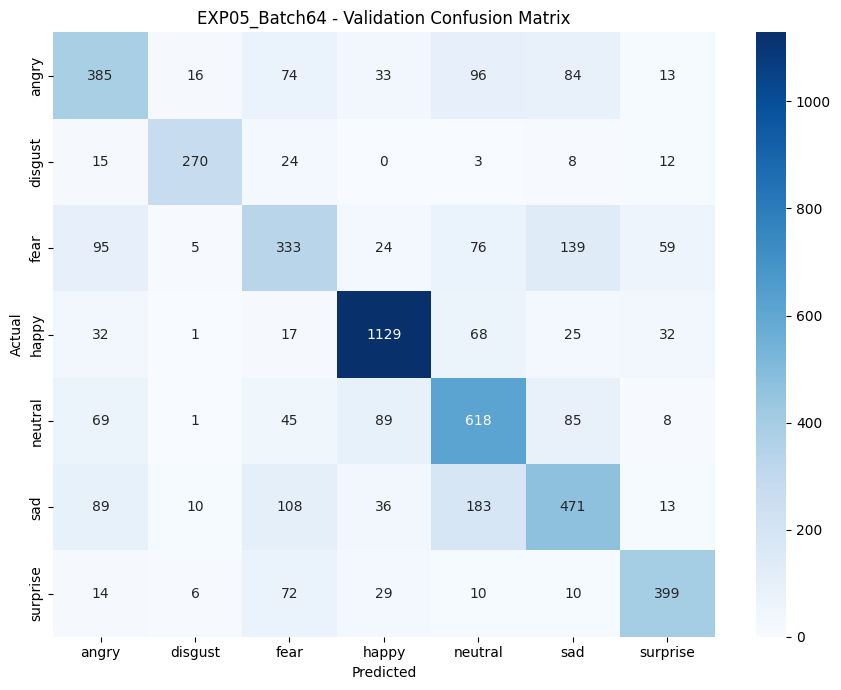

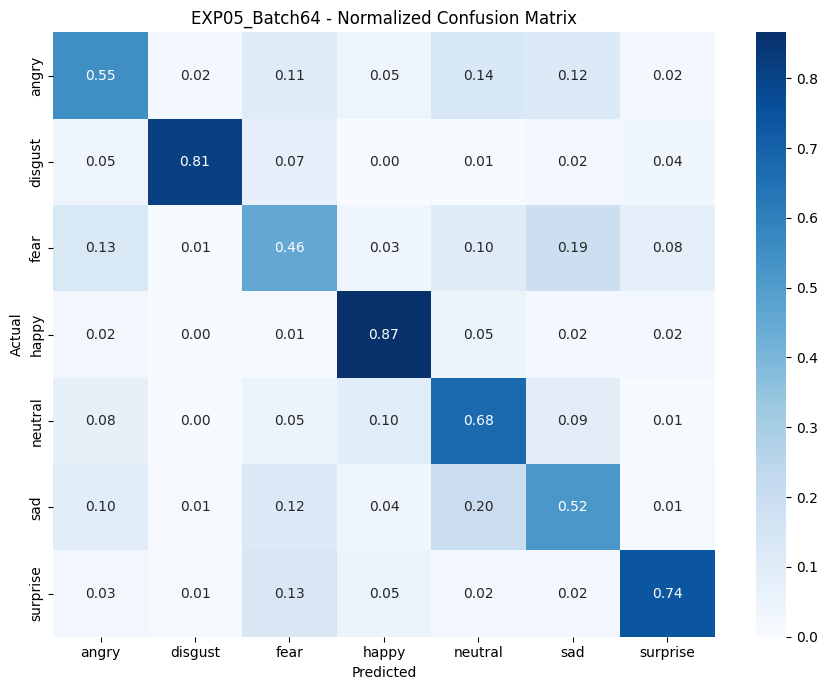

Confusion matrices saved.
Total misclassified images: 1828


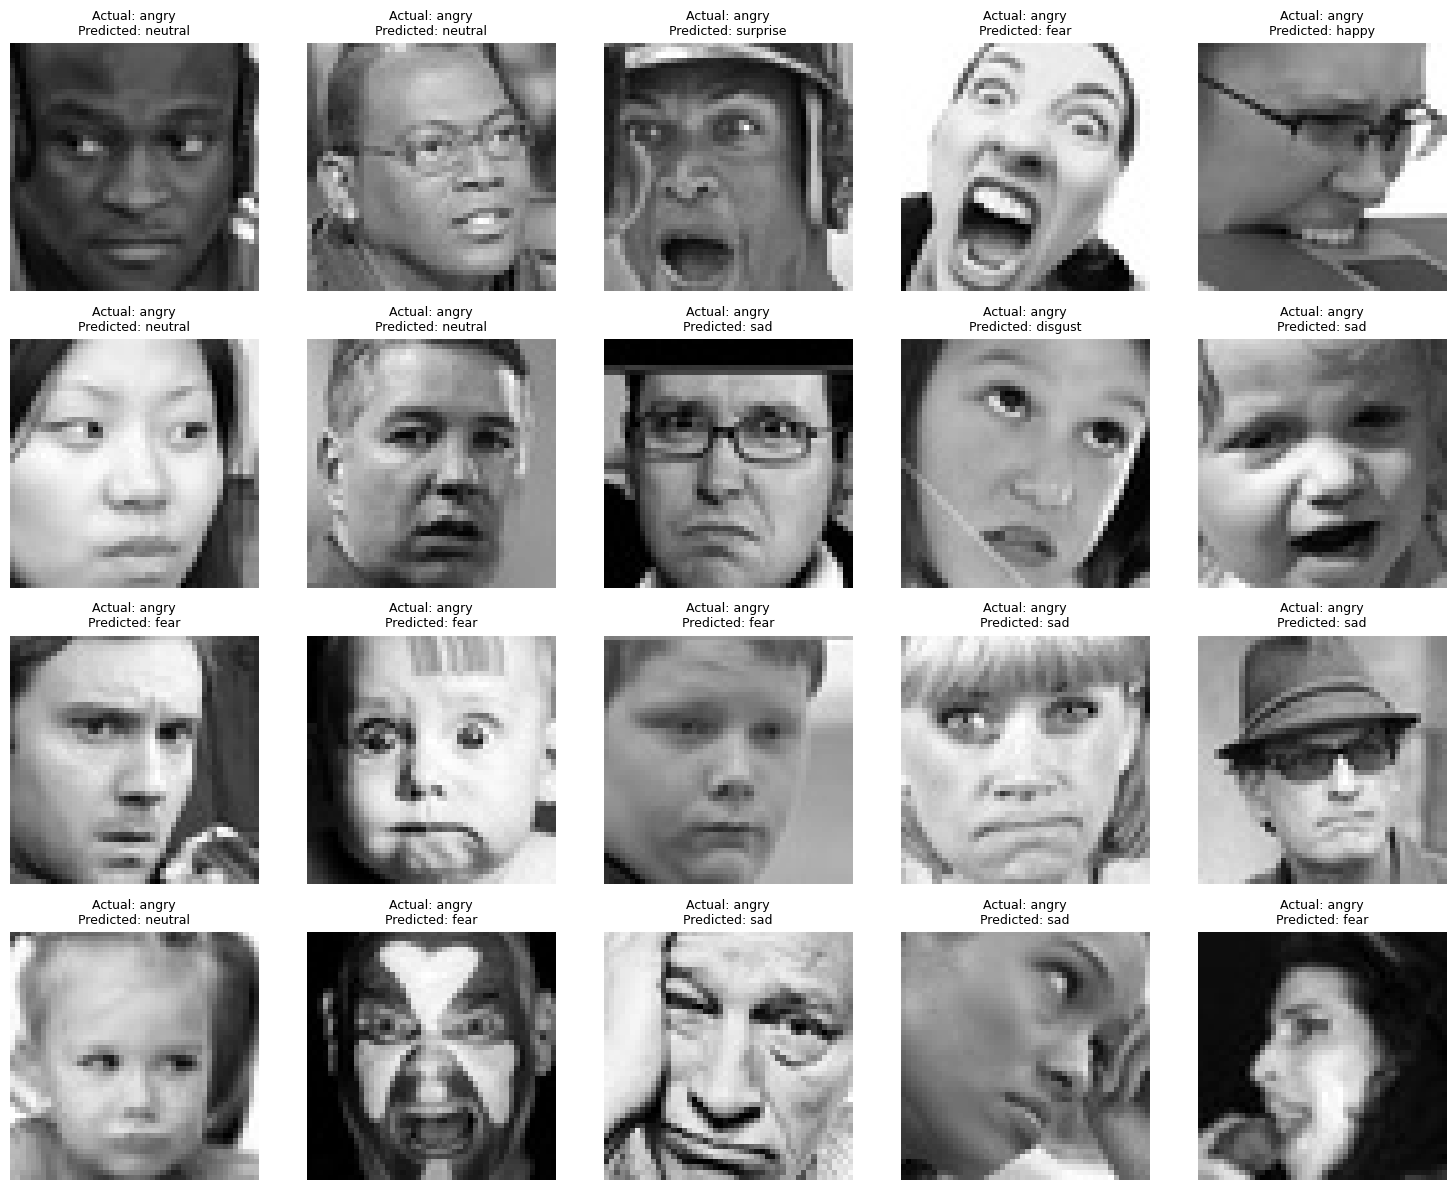

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Select best validation model
if exp05_result["Macro_F1"] >= exp09_result["Macro_F1"]:
    final_candidate_name = "EXP05_Batch64"
    final_candidate_path = EXP05_PATH
    final_preds = exp05_preds
else:
    final_candidate_name = "EXP09_Targeted_Augmentation"
    final_candidate_path = EXP09_PATH
    final_preds = exp09_preds

print("Selected candidate:", final_candidate_name)

# Confusion matrices
cm = confusion_matrix(
    val_targets,
    final_preds,
    labels=list(range(7))
)

cm_normalized = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

# Raw confusion matrix
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title(f"{final_candidate_name} - Validation Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    os.path.join(exp09_results_dir, "Final_Validation_Confusion_Matrix.png"),
    dpi=300
)
plt.show()

# Normalized confusion matrix
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_normalized,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.title(f"{final_candidate_name} - Normalized Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()

plt.savefig(
    os.path.join(exp09_results_dir, "Final_Validation_Normalized_CM.png"),
    dpi=300
)
plt.show()

# Save matrices
pd.DataFrame(
    cm, index=CLASS_NAMES, columns=CLASS_NAMES
).to_csv(
    os.path.join(exp09_results_dir, "Final_Validation_CM.csv")
)

print("Confusion matrices saved.")

# ------------------------------------------------------------
# Misclassified images
# ------------------------------------------------------------

val_dataset = final_val_loader.dataset

misclassified_indices = np.where(
    val_targets != final_preds
)[0]

print("Total misclassified images:", len(misclassified_indices))

# Show up to 20 misclassified images
show_indices = misclassified_indices[:20]

fig, axes = plt.subplots(4, 5, figsize=(15, 12))
axes = axes.flatten()

for ax, idx in zip(axes, show_indices):

    image_path = val_dataset.paths[idx]
    image = Image.open(image_path).convert("L")

    actual = CLASS_NAMES[val_targets[idx]]
    predicted = CLASS_NAMES[final_preds[idx]]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"Actual: {actual}\nPredicted: {predicted}",
        fontsize=9
    )
    ax.axis("off")

for ax in axes[len(show_indices):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig(
    os.path.join(exp09_results_dir, "Final_Misclassified_Images.png"),
    dpi=300
)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

EXP05_HISTORY_PATH = (
    r"E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment"
    r"\Model_Improvement\EXP05_Batch64\Results\EXP05_Batch64_History.csv"
)

exp05_history_df = pd.read_csv(EXP05_HISTORY_PATH)
exp09_history_df = pd.read_csv(exp09_history_path)

plt.figure(figsize=(11, 6))

plt.plot(
    exp05_history_df["epoch"],
    exp05_history_df["val_macro_f1"],
    label="EXP05 Batch64"
)

plt.plot(
    exp09_history_df["epoch"],
    exp09_history_df["val_macro_f1"],
    label="EXP09 Targeted Augmentation"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("EXP05 vs EXP09 - Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(exp09_results_dir, "EXP05_vs_EXP09_Training_Comparison.png"),
    dpi=300
)

plt.show()

print("Training comparison graph saved.")

In [1]:
import shutil
from torchvision import transforms
from PIL import Image

# ------------------------------------------------------------
# Final model directory
# ------------------------------------------------------------

FINAL_MODEL_DIR = os.path.join(
    r"E:\Deploy\Facial Expression Detection",
    "FER_Scratch_Experiment",
    "Final_Model"
)

os.makedirs(FINAL_MODEL_DIR, exist_ok=True)

FINAL_MODEL_PATH = os.path.join(
    FINAL_MODEL_DIR,
    "FER_Final_Model.pth"
)

# Copy selected checkpoint
shutil.copy2(
    final_candidate_path,
    FINAL_MODEL_PATH
)

# Load final model
final_model = FER_SEResNetScratch(num_classes=7).to(device)

final_checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device
)

final_model.load_state_dict(
    final_checkpoint["model_state_dict"]
)

final_model.eval()

# Save model information
final_info = {
    "selected_model": final_candidate_name,
    "validation_macro_f1": float(
        max(
            exp05_result["Macro_F1"],
            exp09_result["Macro_F1"]
        )
    ),
    "class_names": CLASS_NAMES,
    "input_size": [48, 48],
    "input_channels": 1,
    "training_type": "Scratch"
}

import json

with open(
    os.path.join(FINAL_MODEL_DIR, "Final_Model_Info.json"),
    "w"
) as f:
    json.dump(final_info, f, indent=4)

print("========== FINAL MODEL SAVED ==========")
print("Selected model:", final_candidate_name)
print("Final model:", FINAL_MODEL_PATH)
print("Validation Macro-F1:", final_info["validation_macro_f1"])

# ------------------------------------------------------------
# Inference function
# ------------------------------------------------------------

inference_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

def predict_emotion(image_path):

    image = Image.open(image_path).convert("L")

    image_tensor = inference_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        with torch.cuda.amp.autocast(enabled=(device.type == "cuda")):
            output = final_model(image_tensor)

        probabilities = torch.softmax(output, dim=1)[0]

    predicted_id = probabilities.argmax().item()

    print("Predicted Emotion:", CLASS_NAMES[predicted_id])
    print(
        "Confidence:",
        round(probabilities[predicted_id].item() * 100, 2),
        "%"
    )

    return {
        "emotion": CLASS_NAMES[predicted_id],
        "confidence": float(probabilities[predicted_id].item()),
        "probabilities": {
            CLASS_NAMES[i]: float(probabilities[i].item())
            for i in range(7)
        }
    }

print("\nInference function is ready.")

NameError: name 'os' is not defined

In [9]:

# ============================================================
# KERNEL RESTART RECOVERY - STEP 1
# Imports, paths and validation dataset
# ============================================================

import os
import gc
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image, ImageFile
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

from IPython.display import display

ImageFile.LOAD_TRUNCATED_IMAGES = True

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Class mapping
CLASS_NAMES = [
    "angry", "disgust", "fear",
    "happy", "neutral", "sad", "surprise"
]

CLASS_TO_IDX = {
    name: idx for idx, name in enumerate(CLASS_NAMES)
}

# Project paths
PROJECT_ROOT = Path(r"E:\Deploy\Facial Expression Detection")

manifest_path = (
    PROJECT_ROOT
    / "FER_Scratch_Experiment"
    / "Dataset_Freeze"
    / "FER_Final_Frozen_Split_Manifest.csv"
)

# Check manifest
if not manifest_path.is_file():
    raise FileNotFoundError(f"Manifest not found: {manifest_path}")

frozen_manifest = pd.read_csv(manifest_path)

# Rebuild validation dataframe
val_df = frozen_manifest[
    frozen_manifest["New_Split"] == "Validation"
].copy()

# Resolve image paths
def resolve_path(path):
    path = Path(str(path).strip())

    if not path.is_absolute():
        path = PROJECT_ROOT / path

    return str(path)

val_df["Resolved_Path"] = val_df["Image_Path"].apply(resolve_path)

val_df["Label"] = (
    val_df["Class"]
    .astype(str)
    .str.strip()
    .str.lower()
    .map(CLASS_TO_IDX)
)

if val_df["Label"].isna().any():
    raise ValueError("Unknown class label found in validation manifest.")

val_df["Label"] = val_df["Label"].astype(int)

# Deterministic validation transform
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(
        (48, 48),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

# Dataset class
class FERManifestDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.paths = dataframe["Resolved_Path"].tolist()
        self.labels = dataframe["Label"].astype(int).tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):

        path = self.paths[index]
        label = self.labels[index]

        with Image.open(path) as image:
            image = image.convert("L")

        if self.transform:
            image = self.transform(image)

        return image, label


val_dataset = FERManifestDataset(
    val_df,
    transform=eval_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

final_val_loader = val_loader

# Checkpoint paths - use actual saved files
EXP05_PATH = (
    PROJECT_ROOT
    / "FER_Scratch_Experiment"
    / "Model_Improvement"
    / "EXP05_Batch64"
    / "Models"
    / "EXP05_Batch64_Best.pth"
)

EXP09_PATH = (
    PROJECT_ROOT
    / "FER_Scratch_Experiment"
    / "Model_Improvement"
    / "EXP09_Targeted_Augmentation"
    / "Models"
    / "EXP09_Targeted_Augmentation_Best.pth"
)

# Results directory
exp09_results_dir = str(
    PROJECT_ROOT
    / "FER_Scratch_Experiment"
    / "Model_Improvement"
    / "EXP09_Targeted_Augmentation"
    / "Results"
)

os.makedirs(exp09_results_dir, exist_ok=True)

# Verify files and dataset
print("========== RECOVERY STEP 1 ==========")
print("Device:", device)
print("Validation images:", len(val_dataset))
print("Validation batches:", len(val_loader))
print("EXP05 checkpoint exists:", EXP05_PATH.is_file())
print("EXP09 checkpoint exists:", EXP09_PATH.is_file())
print("Results folder exists:", os.path.isdir(exp09_results_dir))

assert len(val_dataset) == 5433
assert EXP05_PATH.is_file(), "EXP05 checkpoint missing!"
assert EXP09_PATH.is_file(), "EXP09 checkpoint missing!"

print("\nRecovery Step 1 completed successfully.")


========== RECOVERY STEP 1 ==========
Device: cuda
Validation images: 5433
Validation batches: 85
EXP05 checkpoint exists: True
EXP09 checkpoint exists: True
Results folder exists: True

Recovery Step 1 completed successfully.


In [10]:

# ============================================================
# KERNEL RESTART RECOVERY - STEP 2
# Rebuild the exact SE-ResNet architecture
# ============================================================

class SqueezeExcitation(nn.Module):

    def __init__(self, channels, reduction=8):
        super().__init__()

        hidden = max(channels // reduction, 8)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        scale = self.fc(self.pool(x))
        return x * scale


class SEResidualBlock(nn.Module):

    expansion = 1

    def __init__(self, in_channels, out_channels, stride=1, dropout=0.0):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels, out_channels, kernel_size=3,
            stride=stride, padding=1, bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)
        self.act = nn.SiLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels, out_channels, kernel_size=3,
            stride=1, padding=1, bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)
        self.se = SqueezeExcitation(out_channels, reduction=8)

        self.drop = (
            nn.Dropout2d(dropout)
            if dropout > 0 else nn.Identity()
        )

        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels, out_channels,
                    kernel_size=1, stride=stride, bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )
        else:
            self.shortcut = nn.Identity()

        nn.init.zeros_(self.bn2.weight)

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.act(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.se(out)
        out = self.drop(out)
        out = self.act(out + identity)

        return out


class FER_SEResNetScratch(nn.Module):

    def __init__(self, num_classes=7):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True)
        )

        self.stage1 = nn.Sequential(
            SEResidualBlock(32, 32, stride=1, dropout=0.02),
            SEResidualBlock(32, 32, stride=1, dropout=0.02)
        )

        self.stage2 = nn.Sequential(
            SEResidualBlock(32, 64, stride=2, dropout=0.04),
            SEResidualBlock(64, 64, stride=1, dropout=0.04)
        )

        self.stage3 = nn.Sequential(
            SEResidualBlock(64, 128, stride=2, dropout=0.06),
            SEResidualBlock(128, 128, stride=1, dropout=0.06)
        )

        self.stage4 = nn.Sequential(
            SEResidualBlock(128, 192, stride=2, dropout=0.08),
            SEResidualBlock(192, 192, stride=1, dropout=0.08)
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(192, 128),
            nn.LayerNorm(128),
            nn.SiLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(128, num_classes)
        )

        self._initialize_weights()

    def _initialize_weights(self):

        for module in self.modules():

            if isinstance(module, nn.Conv2d):
                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

            elif isinstance(module, (nn.BatchNorm2d, nn.LayerNorm)):

                if module.weight is not None:
                    nn.init.ones_(module.weight)

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

            elif isinstance(module, nn.Linear):

                nn.init.kaiming_uniform_(
                    module.weight,
                    a=5**0.5
                )

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

        for module in self.modules():
            if isinstance(module, SEResidualBlock):
                nn.init.zeros_(module.bn2.weight)

    def forward(self, x):

        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)

        return self.head(x)


# Architecture verification
recovery_model = FER_SEResNetScratch(num_classes=7).to(device)

print("========== RECOVERY STEP 2 ==========")
print("Model:", type(recovery_model).__name__)
print(
    "Parameters:",
    sum(p.numel() for p in recovery_model.parameters())
)

with torch.no_grad():
    dummy = torch.zeros(2, 1, 48, 48, device=device)
    output = recovery_model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))

assert output.shape == (2, 7)

del recovery_model
torch.cuda.empty_cache()

print("\nRecovery Step 2 completed successfully.")


========== RECOVERY STEP 2 ==========
Model: FER_SEResNetScratch
Parameters: 1994263
Input shape: (2, 1, 48, 48)
Output shape: (2, 7)

Recovery Step 2 completed successfully.


In [11]:

# ============================================================
# RECOVERY STEP 3 - EVALUATE SAVED CHECKPOINTS
# ============================================================

def evaluate_checkpoint(checkpoint_path, model_name):

    print(f"\nLoading {model_name}...")

    if not os.path.isfile(checkpoint_path):
        raise FileNotFoundError(checkpoint_path)

    model = FER_SEResNetScratch(num_classes=7).to(device)

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    predictions = []
    targets = []

    with torch.no_grad():

        for images, labels in final_val_loader:

            images = images.to(device, non_blocking=True)

            with torch.cuda.amp.autocast(
                enabled=(device.type == "cuda")
            ):
                outputs = model(images)

            predictions.extend(
                outputs.argmax(1).cpu().numpy()
            )

            targets.extend(labels.numpy())

    predictions = np.array(predictions)
    targets = np.array(targets)

    precision, recall, f1, _ = precision_recall_fscore_support(
        targets,
        predictions,
        labels=list(range(7)),
        zero_division=0
    )

    weighted_f1 = precision_recall_fscore_support(
        targets,
        predictions,
        average="weighted",
        zero_division=0
    )[2]

    result = {
        "Model": model_name,
        "Best_Epoch": checkpoint["epoch"],
        "Accuracy": accuracy_score(targets, predictions),
        "Balanced_Accuracy": balanced_accuracy_score(
            targets, predictions
        ),
        "Macro_Precision": precision.mean(),
        "Macro_Recall": recall.mean(),
        "Macro_F1": f1.mean(),
        "Weighted_F1": weighted_f1
    }

    print(f"\n========== {model_name} ==========")

    print("Checkpoint Epoch:", checkpoint["epoch"])

    print(classification_report(
        targets,
        predictions,
        labels=list(range(7)),
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4
    ))

    del model, checkpoint
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result, predictions, targets


# Evaluate EXP05
exp05_result, exp05_preds, val_targets = evaluate_checkpoint(
    str(EXP05_PATH),
    "EXP05_Batch64"
)

# Evaluate EXP09
exp09_result, exp09_preds, _ = evaluate_checkpoint(
    str(EXP09_PATH),
    "EXP09_Targeted_Augmentation"
)

# Compare results
comparison_df = pd.DataFrame([
    exp05_result,
    exp09_result
])

print("\n========== FINAL VALIDATION COMPARISON ==========")

display(
    comparison_df.style.format({
        "Accuracy": "{:.4%}",
        "Balanced_Accuracy": "{:.4%}",
        "Macro_Precision": "{:.4%}",
        "Macro_Recall": "{:.4%}",
        "Macro_F1": "{:.4%}",
        "Weighted_F1": "{:.4%}"
    })
)

# Save comparison
comparison_path = os.path.join(
    exp09_results_dir,
    "EXP05_vs_EXP09_Validation.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("\nComparison saved:", comparison_path)
print("Recovery Step 3 completed.")



Loading EXP05_Batch64...

========== EXP05_Batch64 ==========
Checkpoint Epoch: 72
              precision    recall  f1-score   support

       angry     0.5508    0.5492    0.5500       701
     disgust     0.8738    0.8133    0.8424       332
        fear     0.4948    0.4555    0.4744       731
       happy     0.8425    0.8658    0.8540      1304
     neutral     0.5863    0.6754    0.6277       915
         sad     0.5730    0.5176    0.5439       910
    surprise     0.7444    0.7389    0.7416       540

    accuracy                         0.6635      5433
   macro avg     0.6665    0.6594    0.6620      5433
weighted avg     0.6620    0.6635    0.6618      5433


Loading EXP09_Targeted_Augmentation...

========== EXP09_Targeted_Augmentation ==========
Checkpoint Epoch: 68
              precision    recall  f1-score   support

       angry     0.5609    0.5649    0.5629       701
     disgust     0.9176    0.7380    0.8180       332
        fear     0.4514    0.4446    0.4480 

,Model,Best_Epoch,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1
0,EXP05_Batch64,72,66.3538%,65.9384%,66.6520%,65.9384%,66.2007%,66.1772%
1,EXP09_Targeted_Augmentation,68,65.6727%,64.9234%,66.8015%,64.9234%,65.6929%,65.8599%



Comparison saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP09_Targeted_Augmentation\Results\EXP05_vs_EXP09_Validation.csv
Recovery Step 3 completed.


========== FINAL VALIDATION CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

       angry     0.5508    0.5492    0.5500       701
     disgust     0.8738    0.8133    0.8424       332
        fear     0.4948    0.4555    0.4744       731
       happy     0.8425    0.8658    0.8540      1304
     neutral     0.5863    0.6754    0.6277       915
         sad     0.5730    0.5176    0.5439       910
    surprise     0.7444    0.7389    0.7416       540

    accuracy                         0.6635      5433
   macro avg     0.6665    0.6594    0.6620      5433
weighted avg     0.6620    0.6635    0.6618      5433



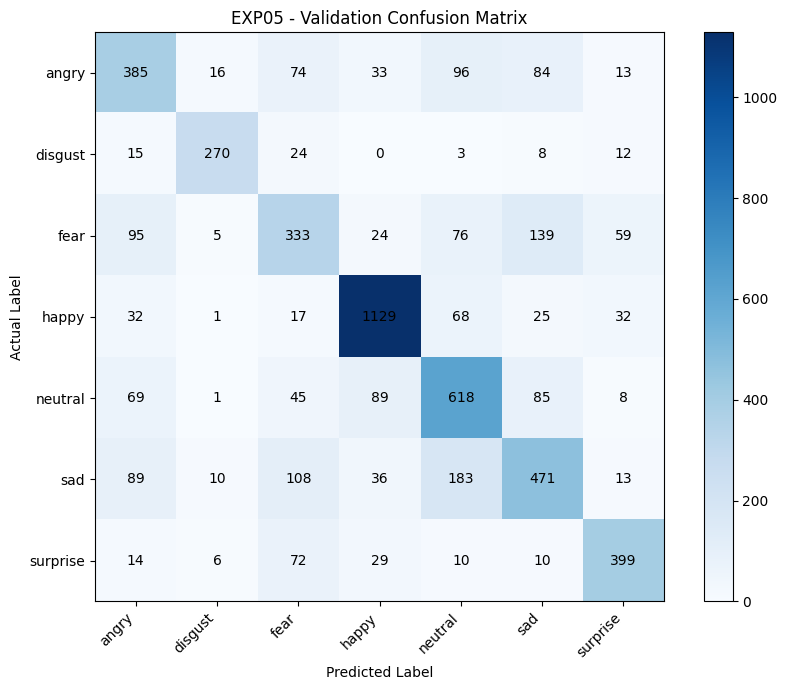

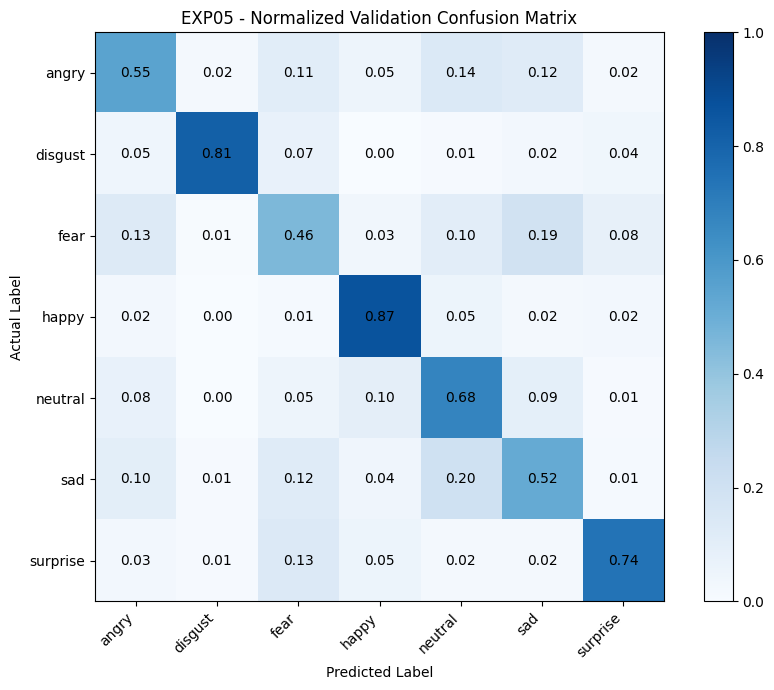


Total validation images: 5433
Correct predictions: 3605
Misclassified images: 1828
Saved reports and confusion matrices.


In [12]:

# ============================================================
# STEP 4 - FINAL VALIDATION ERROR ANALYSIS
# Selected model: EXP05 Batch64
# ============================================================

import matplotlib.pyplot as plt

FINAL_MODEL_NAME = "EXP05_Batch64"

final_preds = exp05_preds
final_targets = val_targets

FINAL_RESULTS_DIR = (
    PROJECT_ROOT / "FER_Scratch_Experiment" / "Final_Model" / "Results"
)
FINAL_FIGURES_DIR = (
    PROJECT_ROOT / "FER_Scratch_Experiment" / "Final_Model" / "Figures"
)

FINAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FINAL_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Classification report
report_dict = classification_report(
    final_targets,
    final_preds,
    labels=list(range(7)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_df.to_csv(
    FINAL_RESULTS_DIR / "Final_Validation_Classification_Report.csv"
)

print("========== FINAL VALIDATION CLASSIFICATION REPORT ==========")
print(classification_report(
    final_targets,
    final_preds,
    labels=list(range(7)),
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

# Confusion matrices
cm = confusion_matrix(
    final_targets,
    final_preds,
    labels=list(range(7))
)

cm_normalized = cm.astype(float) / np.maximum(
    cm.sum(axis=1, keepdims=True), 1
)

# Save raw confusion matrix
pd.DataFrame(
    cm,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    FINAL_RESULTS_DIR / "Final_Validation_Confusion_Matrix.csv"
)

# Save normalized matrix
pd.DataFrame(
    cm_normalized,
    index=CLASS_NAMES,
    columns=CLASS_NAMES
).to_csv(
    FINAL_RESULTS_DIR / "Final_Validation_Normalized_CM.csv"
)

# Plot raw matrix
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(7))
ax.set_yticks(range(7))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)

for i in range(7):
    for j in range(7):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center")

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_title("EXP05 - Validation Confusion Matrix")
fig.colorbar(im, ax=ax)
fig.tight_layout()

fig.savefig(
    FINAL_FIGURES_DIR / "Final_Validation_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Plot normalized matrix
fig, ax = plt.subplots(figsize=(9, 7))

im = ax.imshow(cm_normalized, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(7))
ax.set_yticks(range(7))
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticklabels(CLASS_NAMES)

for i in range(7):
    for j in range(7):
        ax.text(
            j, i,
            f"{cm_normalized[i, j]:.2f}",
            ha="center",
            va="center"
        )

ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
ax.set_title("EXP05 - Normalized Validation Confusion Matrix")
fig.colorbar(im, ax=ax)
fig.tight_layout()

fig.savefig(
    FINAL_FIGURES_DIR / "Final_Validation_Normalized_CM.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Per-image predictions
prediction_df = pd.DataFrame({
    "Image_Path": val_dataset.paths,
    "Actual_Label": [
        CLASS_NAMES[i] for i in final_targets
    ],
    "Predicted_Label": [
        CLASS_NAMES[i] for i in final_preds
    ],
    "Correct": final_targets == final_preds
})

prediction_df.to_csv(
    FINAL_RESULTS_DIR / "Final_Validation_Predictions.csv",
    index=False
)

misclassified_df = prediction_df[
    ~prediction_df["Correct"]
].copy()

misclassified_df.to_csv(
    FINAL_RESULTS_DIR / "Final_Misclassified_Images.csv",
    index=False
)

print("\nTotal validation images:", len(prediction_df))
print("Correct predictions:", int(prediction_df["Correct"].sum()))
print("Misclassified images:", len(misclassified_df))
print("Saved reports and confusion matrices.")


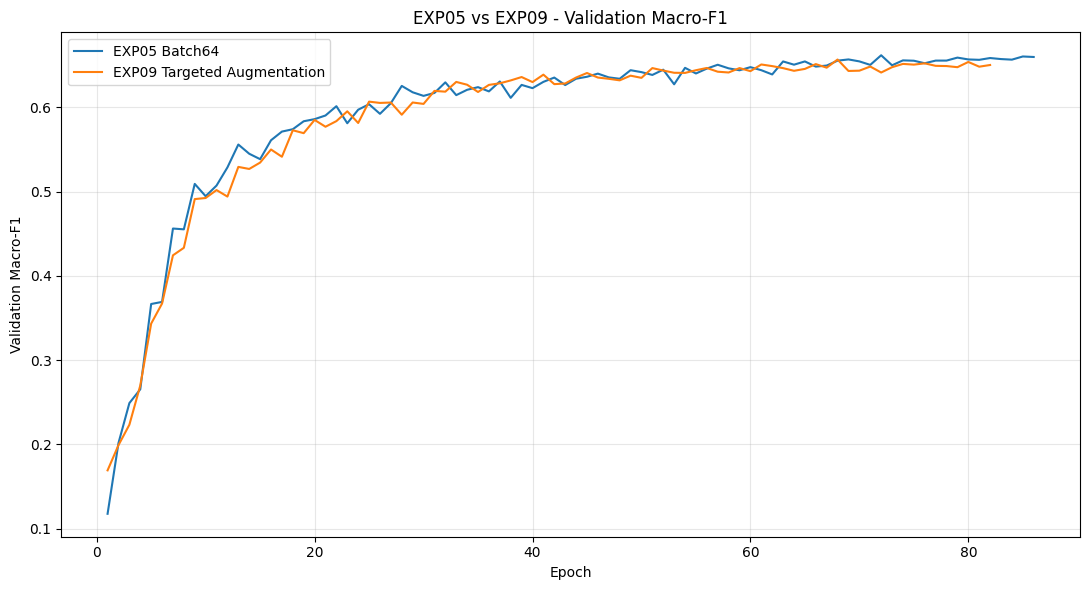

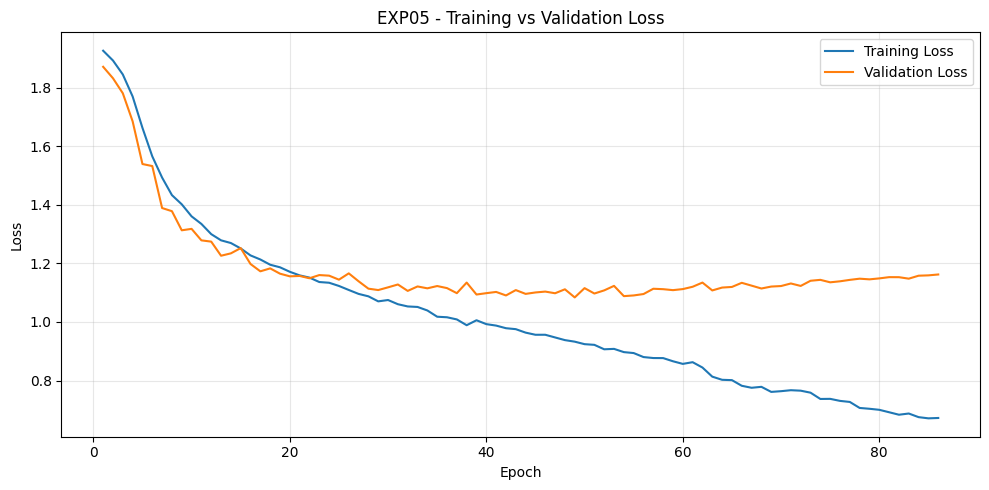

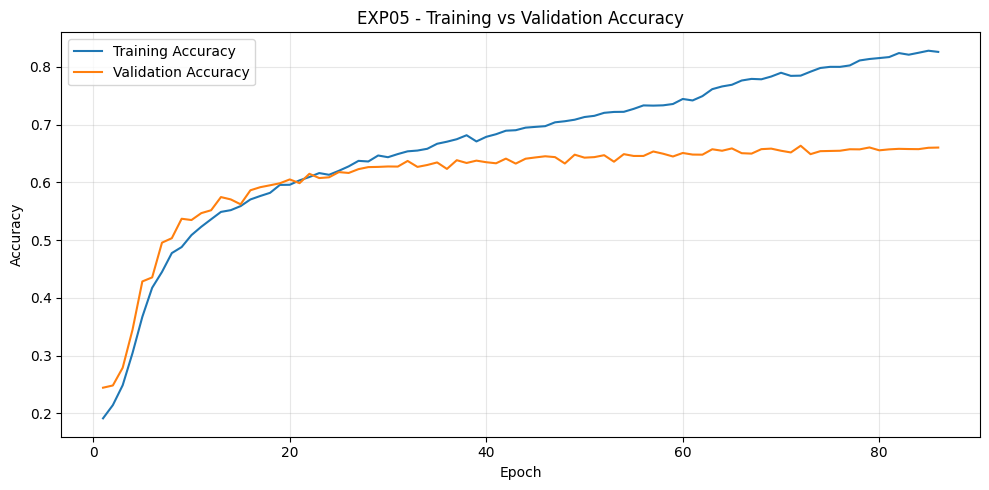

All training graphs saved successfully.


In [13]:

# ============================================================
# STEP 5 - TRAINING HISTORY VISUALIZATION
# ============================================================

EXP05_HISTORY_PATH = (
    PROJECT_ROOT
    / "FER_Scratch_Experiment"
    / "Model_Improvement"
    / "EXP05_Batch64"
    / "Results"
    / "EXP05_Batch64_History.csv"
)

EXP09_HISTORY_PATH = (
    PROJECT_ROOT
    / "FER_Scratch_Experiment"
    / "Model_Improvement"
    / "EXP09_Targeted_Augmentation"
    / "Results"
    / "EXP09_Training_History.csv"
)

assert EXP05_HISTORY_PATH.is_file(), "EXP05 history CSV missing"
assert EXP09_HISTORY_PATH.is_file(), "EXP09 history CSV missing"

exp05_history_df = pd.read_csv(EXP05_HISTORY_PATH)
exp09_history_df = pd.read_csv(EXP09_HISTORY_PATH)

# 1. Validation Macro-F1 comparison
plt.figure(figsize=(11, 6))

plt.plot(
    exp05_history_df["epoch"],
    exp05_history_df["val_macro_f1"],
    label="EXP05 Batch64"
)

plt.plot(
    exp09_history_df["epoch"],
    exp09_history_df["val_macro_f1"],
    label="EXP09 Targeted Augmentation"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Macro-F1")
plt.title("EXP05 vs EXP09 - Validation Macro-F1")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FINAL_FIGURES_DIR / "EXP05_vs_EXP09_Validation_F1.png",
    dpi=300
)
plt.show()

# 2. EXP05 Training and Validation Loss
plt.figure(figsize=(10, 5))

plt.plot(
    exp05_history_df["epoch"],
    exp05_history_df["train_loss"],
    label="Training Loss"
)

plt.plot(
    exp05_history_df["epoch"],
    exp05_history_df["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EXP05 - Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FINAL_FIGURES_DIR / "EXP05_Training_Validation_Loss.png",
    dpi=300
)
plt.show()

# 3. EXP05 Training and Validation Accuracy
plt.figure(figsize=(10, 5))

plt.plot(
    exp05_history_df["epoch"],
    exp05_history_df["train_accuracy"],
    label="Training Accuracy"
)

plt.plot(
    exp05_history_df["epoch"],
    exp05_history_df["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EXP05 - Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    FINAL_FIGURES_DIR / "EXP05_Training_Validation_Accuracy.png",
    dpi=300
)
plt.show()

print("All training graphs saved successfully.")


In [14]:

# ============================================================
# STEP 6 - SAVE FINAL MODEL
# ============================================================

import shutil
import json

FINAL_MODEL_DIR = (
    PROJECT_ROOT / "FER_Scratch_Experiment" / "Final_Model"
)

FINAL_MODEL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_MODEL_PATH = FINAL_MODEL_DIR / "FER_Final_Model.pth"

# Copy the selected trained checkpoint
shutil.copy2(EXP05_PATH, FINAL_MODEL_PATH)

# Load final model
final_model = FER_SEResNetScratch(num_classes=7).to(device)

final_checkpoint = torch.load(
    FINAL_MODEL_PATH,
    map_location=device
)

final_model.load_state_dict(
    final_checkpoint["model_state_dict"]
)

final_model.eval()

# Save final model information
final_info = {
    "project": "Facial Emotion Recognition",
    "selected_model": "EXP05_Batch64",
    "architecture": "FER_SEResNetScratch",
    "training_type": "From Scratch",
    "parameters": 1994263,
    "input_size": [48, 48],
    "input_channels": 1,
    "classes": CLASS_NAMES,
    "best_epoch": int(final_checkpoint["epoch"]),
    "validation_macro_f1": float(exp05_result["Macro_F1"]),
    "validation_accuracy": float(exp05_result["Accuracy"]),
    "checkpoint_file": "FER_Final_Model.pth"
}

with open(
    FINAL_MODEL_DIR / "Final_Model_Info.json",
    "w"
) as f:
    json.dump(final_info, f, indent=4)

# Copy final validation report and experiment comparison
shutil.copy2(
    FINAL_RESULTS_DIR / "Final_Validation_Classification_Report.csv",
    FINAL_MODEL_DIR / "Final_Validation_Classification_Report.csv"
)

shutil.copy2(
    os.path.join(exp09_results_dir, "EXP05_vs_EXP09_Validation.csv"),
    FINAL_MODEL_DIR / "EXP05_vs_EXP09_Validation.csv"
)

print("========== FINAL MODEL SAVED ==========")
print("Selected Model:", final_info["selected_model"])
print("Checkpoint Epoch:", final_info["best_epoch"])
print("Validation Macro-F1:", round(final_info["validation_macro_f1"], 4))
print("Final Model Path:", FINAL_MODEL_PATH)
print("Final Model Exists:", FINAL_MODEL_PATH.is_file())


========== FINAL MODEL SAVED ==========
Selected Model: EXP05_Batch64
Checkpoint Epoch: 72
Validation Macro-F1: 0.662
Final Model Path: E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Final_Model\FER_Final_Model.pth
Final Model Exists: True


In [22]:

# ============================================================
# STEP 7 - FINAL INFERENCE FUNCTION
# ============================================================

from tkinter import Tk, filedialog
from PIL import Image

inference_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5,), std=(0.5,))
])

def predict_emotion(image_path):

    if not os.path.isfile(image_path):
        raise FileNotFoundError(
            f"Image not found: {image_path}"
        )

    image = Image.open(image_path).convert("L")

    image_tensor = (
        inference_transform(image)
        .unsqueeze(0)
        .to(device)
    )

    final_model.eval()

    with torch.no_grad():

        with torch.cuda.amp.autocast(
            enabled=(device.type == "cuda")
        ):
            output = final_model(image_tensor)

        probabilities = torch.softmax(output, dim=1)[0]

    predicted_id = probabilities.argmax().item()

    result = {
        "emotion": CLASS_NAMES[predicted_id],
        "confidence": float(
            probabilities[predicted_id].item()
        ),
        "probabilities": {
            CLASS_NAMES[i]: float(probabilities[i].item())
            for i in range(7)
        }
    }

    print("Predicted Emotion:", result["emotion"])
    print(
        "Model Confidence:",
        f"{result['confidence'] * 100:.2f}%"
    )

    return result


# Open file selection dialog
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

selected_image_path = filedialog.askopenfilename(
    title="Select a Facial Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

if selected_image_path:

    print("Selected image:", selected_image_path)

    prediction = predict_emotion(selected_image_path)

    print("\nClass-wise scores:")

    for emotion, probability in prediction["probabilities"].items():
        print(f"{emotion:10s}: {probability * 100:.2f}%")

else:
    print("No image selected.")


Selected image: E:/Deploy/Facial Expression Detection/FER_Scratch_Experiment/Happy.jpg
Predicted Emotion: sad
Model Confidence: 33.84%

Class-wise scores:
angry     : 9.12%
disgust   : 0.79%
fear      : 6.59%
happy     : 1.17%
neutral   : 33.64%
sad       : 33.84%
surprise  : 14.84%


In [23]:

# ============================================================
# STEP 8 - FINAL PROJECT SUMMARY
# ============================================================

summary = {
    "project": "Facial Emotion Recognition",
    "dataset": {
        "training_images": 23412,
        "validation_images": 5433,
        "test_images": 7139,
        "classes": CLASS_NAMES
    },
    "selected_model": "EXP05_Batch64",
    "architecture": "FER_SEResNetScratch",
    "best_epoch": 72,
    "validation_accuracy": float(exp05_result["Accuracy"]),
    "validation_balanced_accuracy": float(
        exp05_result["Balanced_Accuracy"]
    ),
    "validation_macro_precision": float(
        exp05_result["Macro_Precision"]
    ),
    "validation_macro_recall": float(
        exp05_result["Macro_Recall"]
    ),
    "validation_macro_f1": float(
        exp05_result["Macro_F1"]
    ),
    "validation_weighted_f1": float(
        exp05_result["Weighted_F1"]
    ),
    "final_checkpoint": str(FINAL_MODEL_PATH)
}

summary_path = FINAL_MODEL_DIR / "Final_Project_Summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("========== PROJECT FINAL SUMMARY ==========")
print(json.dumps(summary, indent=4))

print("\nSummary saved:", summary_path)
print("\nFINAL PROJECT MODEL PACKAGE CREATED.")


========== PROJECT FINAL SUMMARY ==========
{
    "project": "Facial Emotion Recognition",
    "dataset": {
        "training_images": 23412,
        "validation_images": 5433,
        "test_images": 7139,
        "classes": [
            "angry",
            "disgust",
            "fear",
            "happy",
            "neutral",
            "sad",
            "surprise"
        ]
    },
    "selected_model": "EXP05_Batch64",
    "architecture": "FER_SEResNetScratch",
    "best_epoch": 72,
    "validation_accuracy": 0.6635376403460335,
    "validation_balanced_accuracy": 0.6593839232623646,
    "validation_macro_precision": 0.6665204874145775,
    "validation_macro_recall": 0.6593839232623646,
    "validation_macro_f1": 0.6620067366148051,
    "validation_weighted_f1": 0.6617723172755078,
    "final_checkpoint": "E:\\Deploy\\Facial Expression Detection\\FER_Scratch_Experiment\\Final_Model\\FER_Final_Model.pth"
}

Summary saved: E:\Deploy\Facial Expression Detection\FER_Scratch_Exper

# web cam


In [24]:
import sys
import subprocess
import importlib.util
import os

packages = {
    "streamlit": "streamlit",
    "streamlit_webrtc": "streamlit-webrtc",
    "av": "av",
    "cv2": "opencv-python"
}

missing = [
    package_name
    for module_name, package_name in packages.items()
    if importlib.util.find_spec(module_name) is None
]

print("Python:", sys.executable)
print("Missing packages:", missing)

if missing:
    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        *missing
    ])
else:
    print("All required packages are already installed.")

print("\n========== PACKAGE VERIFICATION ==========")

import streamlit
import streamlit_webrtc
import av
import cv2

print("Streamlit:", streamlit.__version__)
print("OpenCV:", cv2.__version__)
print("WebRTC package: Ready")
print("PyAV:", av.__version__)

FINAL_MODEL_PATH = (
    r"E:\Deploy\Facial Expression Recognition\FER_Scratch_Experiment"
    r"\Final_Model\FER_Final_Model.pth"
)

print("\nFinal Model exists:", os.path.isfile(FINAL_MODEL_PATH))

if not os.path.isfile(FINAL_MODEL_PATH):
    raise FileNotFoundError(FINAL_MODEL_PATH)

print("\nStep 1 completed successfully.")

Python: C:\Users\sahas\.conda\envs\facenet_env\python.exe
Missing packages: ['streamlit', 'streamlit-webrtc', 'av']

========== PACKAGE VERIFICATION ==========


2026-11-14 23:24:24.133 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-14 23:24:24.133 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-14 23:24:24.138 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-14 23:24:24.138 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-11-14 23:24:24.415 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 23:24:24.417 No runtime found, using MemoryCacheStorageManager


Streamlit: 1.67.0
OpenCV: 4.11.0
WebRTC package: Ready
PyAV: 18.1.0

Final Model exists: False


FileNotFoundError: E:\Deploy\Facial Expression Recognition\FER_Scratch_Experiment\Final_Model\FER_Final_Model.pth

In [25]:
import os

PROJECT_ROOT = r"E:\Deploy\Facial Expression Detection"

FINAL_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Final_Model",
    "FER_Final_Model.pth"
)

EXP05_PATH = os.path.join(
    PROJECT_ROOT,
    "FER_Scratch_Experiment",
    "Model_Improvement",
    "EXP05_Batch64",
    "Models",
    "EXP05_Batch64_Best.pth"
)

print("========== MODEL FILE VERIFICATION ==========")

print("\nFinal Model:")
print(FINAL_MODEL_PATH)
print("Exists:", os.path.isfile(FINAL_MODEL_PATH))

print("\nEXP05 Original Checkpoint:")
print(EXP05_PATH)
print("Exists:", os.path.isfile(EXP05_PATH))

if os.path.isfile(FINAL_MODEL_PATH):
    print("\nFinal Model is ready for deployment.")

elif os.path.isfile(EXP05_PATH):
    print("\nFinal copy missing. Original EXP05 checkpoint is available.")
    print("We can safely recreate the final model copy.")

else:
    print("\nNeither model file was found. Check project folder location.")

========== MODEL FILE VERIFICATION ==========

Final Model:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Final_Model\FER_Final_Model.pth
Exists: True

EXP05 Original Checkpoint:
E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Model_Improvement\EXP05_Batch64\Models\EXP05_Batch64_Best.pth
Exists: True

Final Model is ready for deployment.


In [26]:

%%writefile "E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Final_Model\app.py"

import os
import threading

import streamlit as st
import torch
import torch.nn as nn
import numpy as np
import cv2
import av

from PIL import Image
from torchvision import transforms
from streamlit_webrtc import webrtc_streamer, WebRtcMode


# ============================================================
# 1. APPLICATION CONFIGURATION
# ============================================================

st.set_page_config(
    page_title="FER Live Emotion Recognition",
    page_icon="😊",
    layout="wide"
)

PROJECT_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    PROJECT_DIR,
    "FER_Final_Model.pth"
)

CLASS_NAMES = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# 2. MODEL ARCHITECTURE
# Same architecture used during EXP05 training
# ============================================================

class SqueezeExcitation(nn.Module):

    def __init__(self, channels, reduction=8):
        super().__init__()

        hidden = max(channels // reduction, 8)

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):

        scale = self.fc(self.pool(x))

        return x * scale


class SEResidualBlock(nn.Module):

    expansion = 1

    def __init__(
        self,
        in_channels,
        out_channels,
        stride=1,
        dropout=0.0
    ):
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False
        )

        self.bn1 = nn.BatchNorm2d(out_channels)

        self.act = nn.SiLU(inplace=True)

        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        self.bn2 = nn.BatchNorm2d(out_channels)

        self.se = SqueezeExcitation(
            out_channels,
            reduction=8
        )

        self.drop = (
            nn.Dropout2d(dropout)
            if dropout > 0
            else nn.Identity()
        )

        if stride != 1 or in_channels != out_channels:

            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=1,
                    stride=stride,
                    bias=False
                ),
                nn.BatchNorm2d(out_channels)
            )

        else:
            self.shortcut = nn.Identity()

        nn.init.zeros_(self.bn2.weight)

    def forward(self, x):

        identity = self.shortcut(x)

        out = self.act(
            self.bn1(self.conv1(x))
        )

        out = self.bn2(self.conv2(out))
        out = self.se(out)
        out = self.drop(out)

        out = self.act(out + identity)

        return out


class FER_SEResNetScratch(nn.Module):

    def __init__(self, num_classes=7):
        super().__init__()

        self.stem = nn.Sequential(
            nn.Conv2d(
                1, 32,
                kernel_size=3,
                stride=1,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(32),
            nn.SiLU(inplace=True)
        )

        self.stage1 = nn.Sequential(
            SEResidualBlock(
                32, 32, stride=1, dropout=0.02
            ),
            SEResidualBlock(
                32, 32, stride=1, dropout=0.02
            )
        )

        self.stage2 = nn.Sequential(
            SEResidualBlock(
                32, 64, stride=2, dropout=0.04
            ),
            SEResidualBlock(
                64, 64, stride=1, dropout=0.04
            )
        )

        self.stage3 = nn.Sequential(
            SEResidualBlock(
                64, 128, stride=2, dropout=0.06
            ),
            SEResidualBlock(
                128, 128, stride=1, dropout=0.06
            )
        )

        self.stage4 = nn.Sequential(
            SEResidualBlock(
                128, 192, stride=2, dropout=0.08
            ),
            SEResidualBlock(
                192, 192, stride=1, dropout=0.08
            )
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.30),
            nn.Linear(192, 128),
            nn.LayerNorm(128),
            nn.SiLU(inplace=True),
            nn.Dropout(0.35),
            nn.Linear(128, num_classes)
        )

        self._initialize_weights()

    def _initialize_weights(self):

        for module in self.modules():

            if isinstance(module, nn.Conv2d):

                nn.init.kaiming_normal_(
                    module.weight,
                    mode="fan_out",
                    nonlinearity="relu"
                )

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

            elif isinstance(
                module,
                (nn.BatchNorm2d, nn.LayerNorm)
            ):

                if module.weight is not None:
                    nn.init.ones_(module.weight)

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

            elif isinstance(module, nn.Linear):

                nn.init.kaiming_uniform_(
                    module.weight,
                    a=5**0.5
                )

                if module.bias is not None:
                    nn.init.zeros_(module.bias)

        for module in self.modules():

            if isinstance(module, SEResidualBlock):
                nn.init.zeros_(module.bn2.weight)

    def forward(self, x):

        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.pool(x)

        return self.head(x)


# ============================================================
# 3. LOAD TRAINED MODEL
# ============================================================

@st.cache_resource
def load_fer_model():

    if not os.path.isfile(MODEL_PATH):
        raise FileNotFoundError(
            f"Model checkpoint not found: {MODEL_PATH}"
        )

    model = FER_SEResNetScratch(
        num_classes=7
    ).to(DEVICE)

    checkpoint = torch.load(
        MODEL_PATH,
        map_location=DEVICE
    )

    model.load_state_dict(
        checkpoint["model_state_dict"],
        strict=True
    )

    model.eval()

    return model


# ============================================================
# 4. FACE DETECTOR
# ============================================================

@st.cache_resource
def load_face_detector():

    cascade_path = (
        cv2.data.haarcascades
        + "haarcascade_frontalface_default.xml"
    )

    detector = cv2.CascadeClassifier(cascade_path)

    if detector.empty():
        raise RuntimeError(
            "Could not load OpenCV Haar Cascade."
        )

    return detector


# ============================================================
# 5. IMAGE PREPROCESSING
# Same 48x48 grayscale normalization
# ============================================================

inference_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(
        (48, 48),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5,),
        std=(0.5,)
    )
])


# ============================================================
# 6. MODEL INFERENCE
# ============================================================

MODEL_LOCK = threading.Lock()


def predict_face(face_gray, model):

    face_pil = Image.fromarray(face_gray)

    face_tensor = (
        inference_transform(face_pil)
        .unsqueeze(0)
        .to(DEVICE)
    )

    with MODEL_LOCK:

        with torch.inference_mode():

            outputs = model(face_tensor)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[0]

    predicted_id = probabilities.argmax().item()

    confidence = probabilities[predicted_id].item()

    return CLASS_NAMES[predicted_id], confidence, probabilities.cpu().numpy()


# ============================================================
# 7. DETECT AND ANNOTATE FACES
# ============================================================

def process_frame(
    frame,
    model,
    detector,
    min_neighbors=5,
    mirror=False
):

    if mirror:
        frame = cv2.flip(frame, 1)

    gray = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2GRAY
    )

    faces = detector.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=min_neighbors,
        minSize=(40, 40)
    )

    face_results = []

    for (x, y, w, h) in faces:

        face_crop = gray[
            y:y+h,
            x:x+w
        ]

        if face_crop.size == 0:
            continue

        emotion, confidence, probabilities = predict_face(
            face_crop,
            model
        )

        label = (
            f"{emotion} | {confidence * 100:.1f}%"
        )

        # Bounding box
        cv2.rectangle(
            frame,
            (x, y),
            (x+w, y+h),
            (0, 220, 100),
            2
        )

        # Label background
        text_y = max(y - 10, 25)

        cv2.rectangle(
            frame,
            (x, text_y - 25),
            (x + w, text_y + 5),
            (0, 220, 100),
            -1
        )

        cv2.putText(
            frame,
            label,
            (x + 4, text_y - 5),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (0, 0, 0),
            2
        )

        face_results.append({
            "emotion": emotion,
            "confidence": confidence,
            "probabilities": probabilities
        })

    if len(faces) == 0:

        cv2.putText(
            frame,
            "No face detected",
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

    return frame, face_results


# ============================================================
# 8. APPLICATION HEADER
# ============================================================

st.title("Facial Emotion Recognition")

st.markdown(
    """
    ### Real-Time Emotion Detection using Deep Learning

    Detect seven facial expressions using a custom
    **SE-ResNet model trained from scratch**.
    """
)

with st.sidebar:

    st.header("Model Information")

    st.success("Final Model Loaded")

    st.write("Architecture: SE-ResNet")

    st.write("Input: 48 x 48 Grayscale")

    st.write("Classes: 7")

    st.write("Device:", str(DEVICE))

    st.write("Best Validation Macro-F1: 66.20%")

    st.divider()

    min_neighbors = st.slider(
        "Face Detection Sensitivity",
        min_value=3,
        max_value=8,
        value=5
    )

    st.caption(
        "Lower values detect more faces but may create false detections."
    )


# Load model and detector
try:

    model = load_fer_model()
    face_detector = load_face_detector()

except Exception as error:

    st.error(f"Model loading failed: {error}")
    st.stop()


# ============================================================
# 9. MAIN APPLICATION TABS
# ============================================================

webcam_tab, upload_tab = st.tabs([
    "Live Webcam",
    "Upload Image"
])


# ============================================================
# 10. LIVE WEBCAM
# ============================================================

with webcam_tab:

    st.subheader("Live Webcam Emotion Detection")

    st.info(
        "Allow camera access in your browser, then click START."
    )

    def video_frame_callback(frame):

        image = frame.to_ndarray(
            format="bgr24"
        )

        processed_frame, _ = process_frame(
            image,
            model,
            face_detector,
            min_neighbors=min_neighbors,
            mirror=True
        )

        return av.VideoFrame.from_ndarray(
            processed_frame,
            format="bgr24"
        )

    RTC_CONFIGURATION = {
        "iceServers": [
            {
                "urls": [
                    "stun:stun.l.google.com:19302"
                ]
            }
        ]
    }

    webrtc_ctx = webrtc_streamer(
        key="fer-live-webcam",
        mode=WebRtcMode.SENDRECV,
        rtc_configuration=RTC_CONFIGURATION,
        media_stream_constraints={
            "video": True,
            "audio": False
        },
        video_frame_callback=video_frame_callback,
        async_processing=True
    )


# ============================================================
# 11. IMAGE UPLOAD
# ============================================================

with upload_tab:

    st.subheader("Upload a Facial Image")

    uploaded_file = st.file_uploader(
        "Choose an image",
        type=["jpg", "jpeg", "png", "bmp"]
    )

    if uploaded_file is not None:

        image = Image.open(
            uploaded_file
        ).convert("RGB")

        image_array = np.array(image)

        image_bgr = cv2.cvtColor(
            image_array,
            cv2.COLOR_RGB2BGR
        )

        processed_image, results = process_frame(
            image_bgr,
            model,
            face_detector,
            min_neighbors=min_neighbors,
            mirror=False
        )

        processed_rgb = cv2.cvtColor(
            processed_image,
            cv2.COLOR_BGR2RGB
        )

        st.image(
            processed_rgb,
            caption="Emotion Detection Result",
            use_container_width=True
        )

        if results:

            st.subheader("Detected Faces")

            for index, result in enumerate(results, start=1):

                st.write(f"Face {index}")

                col1, col2 = st.columns(2)

                col1.metric(
                    "Predicted Emotion",
                    result["emotion"]
                )

                col2.metric(
                    "Confidence",
                    f"{result['confidence'] * 100:.2f}%"
                )

                st.write("Class-wise Probabilities")

                probability_data = {
                    CLASS_NAMES[i]: float(
                        result["probabilities"][i]
                    )
                    for i in range(7)
                }

                st.bar_chart(probability_data)

        else:

            st.warning(
                "No face detected. Try a clearer, front-facing image."
            )


# ============================================================
# 12. FOOTER
# ============================================================

st.divider()

st.caption(
    "Facial Emotion Recognition | "
    "SE-ResNet Scratch Model | "
    "OpenCV | PyTorch | Streamlit"
)

st.caption(
    "Predictions are model estimates and may be inaccurate, "
    "especially for subtle or ambiguous expressions."
)


Writing E:\Deploy\Facial Expression Detection\FER_Scratch_Experiment\Final_Model\app.py


In [27]:
import os

APP_PATH = (
    r"E:\Deploy\Facial Expression Detection"
    r"\FER_Scratch_Experiment\Final_Model\app.py"
)

print("App exists:", os.path.isfile(APP_PATH))

if os.path.isfile(APP_PATH):
    print("App size:", round(os.path.getsize(APP_PATH) / 1024, 2), "KB")
    print("Final model exists:", os.path.isfile(FINAL_MODEL_PATH))

App exists: True
App size: 15.73 KB
Final model exists: True


SyntaxError: invalid syntax (2644626815.py, line 1)